<a href="https://colab.research.google.com/github/Sajidnihal52/Deep-Learning-Framework-for-Underwater-Marine-Organism-Classification-and-Biodiversity-Monitoring/blob/main/UnderWater_biodiversity_tyhesis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("⚠️ GPU not available. Enable a GPU runtime.")

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [ ]:
!pip install -q albumentations==1.4.24
!pip install -q grad-cam

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 274.9/274.9 kB 12.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 4.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import os
import random
import shutil
import zipfile
import hashlib
import json
import time
import copy
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from collections import Counter
from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving archive.zip to archive.zip


In [ ]:
# ============================================================
# UPLOAD / FIND / EXTRACT UWI2020 DATASET
# ============================================================

import os
import zipfile

print("=" * 70)
print("FINDING DATASET ZIP")
print("=" * 70)

# Find all ZIP files in /content
zip_files = []

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.lower().endswith(".zip"):
            zip_files.append(
                os.path.join(root, file)
            )

print("\nZIP files found:")

for path in zip_files:
    print(" ", path)

if len(zip_files) == 0:

    print("\n❌ No ZIP file found.")
    print("\nPlease upload the UWI2020 ZIP file first.")

else:

    # Use the first ZIP file found
    zip_path = zip_files[0]

    extract_path = "/content/uwi2020"

    os.makedirs(
        extract_path,
        exist_ok=True
    )

    print("\nUsing ZIP:")
    print(zip_path)

    print("\nExtracting to:")
    print(extract_path)

    with zipfile.ZipFile(
        zip_path,
        "r"
    ) as zip_ref:

        zip_ref.extractall(
            extract_path
        )

    print("\n✓ Dataset extracted successfully.")

    print("\nTop-level contents:")

    for item in os.listdir(extract_path):

        full_path = os.path.join(
            extract_path,
            item
        )

        if os.path.isdir(full_path):

            print("  📁", item)

        else:

            print("  📄", item)

    print("\n" + "=" * 70)
    print("EXTRACTION COMPLETED")
    print("=" * 70)

    print("\nNow run STEP 29 again.")

FINDING DATASET ZIP

ZIP files found:
  /content/archive.zip

Using ZIP:
/content/archive.zip

Extracting to:
/content/uwi2020

✓ Dataset extracted successfully.

Top-level contents:
  📁 cls_crops

EXTRACTION COMPLETED

Now run STEP 29 again.


In [ ]:
import os

print(os.listdir("/content"))

['.config', 'archive.zip', 'uwi2020', 'sample_data']


In [ ]:
import zipfile
import os

zip_path = "/content/archive.zip"
extract_path = "/content/uwi2020"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully.")

Dataset extracted successfully.


In [ ]:
for root, dirs, files in os.walk(extract_path):
    level = root.replace(extract_path, "").count(os.sep)
    indent = " " * 4 * level
    print(f"{indent}{os.path.basename(root)}/")

    if level >= 2:
        dirs[:] = []

uwi2020/
    cls_crops/
        train/
        test/


In [ ]:
def find_class_root(base_path):
    for root, dirs, files in os.walk(base_path):
        required = {"echinus", "holothurian", "scallop", "starfish"}
        if required.issubset(set(dirs)):
            return root
    return None

train_root = find_class_root(extract_path)

print("Located class directory:", train_root)

Located class directory: /content/uwi2020/cls_crops/train


In [ ]:
def find_split_path(base_path, split_name):
    for root, dirs, files in os.walk(base_path):
        if os.path.basename(root).lower() == split_name:
            if all(cls in dirs for cls in ["echinus", "holothurian", "scallop", "starfish"]):
                return root
    return None

train_dir = find_split_path(extract_path, "train")
test_dir = find_split_path(extract_path, "test")

print("Train directory:", train_dir)
print("Test directory:", test_dir)

Train directory: /content/uwi2020/cls_crops/train
Test directory: /content/uwi2020/cls_crops/test


In [ ]:
classes = ["echinus", "holothurian", "scallop", "starfish"]

def count_images(split_dir):
    counts = {}

    for cls in classes:
        folder = os.path.join(split_dir, cls)

        images = [
            f for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        counts[cls] = len(images)

    return counts

train_counts = count_images(train_dir)
test_counts = count_images(test_dir)

print("Training:", train_counts)
print("Testing:", test_counts)

Training: {'echinus': 870, 'holothurian': 870, 'scallop': 870, 'starfish': 870}
Testing: {'echinus': 218, 'holothurian': 218, 'scallop': 217, 'starfish': 217}


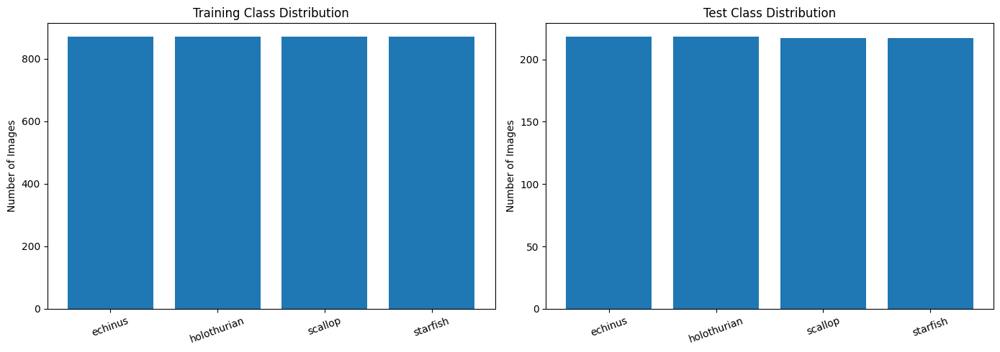

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(train_counts.keys(), train_counts.values())
axes[0].set_title("Training Class Distribution")
axes[0].set_ylabel("Number of Images")
axes[0].tick_params(axis="x", rotation=20)

axes[1].bar(test_counts.keys(), test_counts.values())
axes[1].set_title("Test Class Distribution")
axes[1].set_ylabel("Number of Images")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

In [ ]:
def build_metadata(split_dir, split_name):
    records = []

    for cls in classes:
        folder = os.path.join(split_dir, cls)

        for filename in os.listdir(folder):
            if filename.lower().endswith((".jpg", ".jpeg", ".png")):
                filepath = os.path.join(folder, filename)

                try:
                    with Image.open(filepath) as img:
                        width, height = img.size
                        mode = img.mode

                    records.append({
                        "split": split_name,
                        "class": cls,
                        "filename": filename,
                        "filepath": filepath,
                        "width": width,
                        "height": height,
                        "channels": mode,
                        "area": width * height,
                        "aspect_ratio": width / height
                    })

                except Exception as e:
                    records.append({
                        "split": split_name,
                        "class": cls,
                        "filename": filename,
                        "filepath": filepath,
                        "width": None,
                        "height": None,
                        "channels": None,
                        "area": None,
                        "aspect_ratio": None
                    })

    return pd.DataFrame(records)

train_meta = build_metadata(train_dir, "train")
test_meta = build_metadata(test_dir, "test")

metadata = pd.concat([train_meta, test_meta], ignore_index=True)

print("Total images:", len(metadata))
metadata.head()

Total images: 4350


,split,class,filename,filepath,width,height,channels,area,aspect_ratio
0,train,echinus,002695_9aa35733.jpg,/content/uwi2020/cls_crops/train/echinus/00269...,59,54,RGB,3186,1.092593
1,train,echinus,001649_f4fd686b.jpg,/content/uwi2020/cls_crops/train/echinus/00164...,113,122,RGB,13786,0.926230
2,train,echinus,002052_a6212bae.jpg,/content/uwi2020/cls_crops/train/echinus/00205...,39,31,RGB,1209,1.258065
3,train,echinus,002316_6e75630e.jpg,/content/uwi2020/cls_crops/train/echinus/00231...,33,27,RGB,891,1.222222
4,train,echinus,003406_f0053932.jpg,/content/uwi2020/cls_crops/train/echinus/00340...,45,40,RGB,1800,1.125000


In [ ]:
metadata.to_csv("/content/uwi2020_metadata.csv", index=False)

print("Metadata saved.")

Metadata saved.


In [ ]:
metadata[["width", "height", "aspect_ratio"]].describe()

,width,height,aspect_ratio
count,4350.000000,4350.000000,4350.000000
mean,156.955862,127.682989,1.280314
std,137.800241,107.444429,0.497917
min,16.000000,16.000000,0.239316
25%,63.000000,53.000000,0.979694
50%,108.000000,90.000000,1.172414
75%,210.000000,168.000000,1.470588
max,1330.000000,1139.000000,6.219780


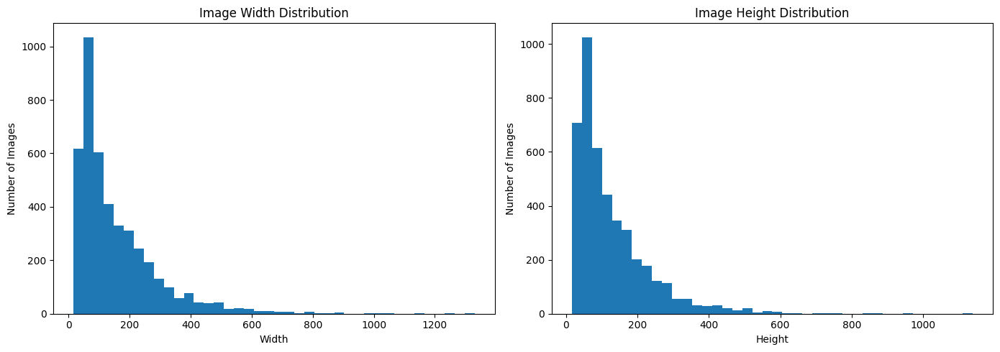

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(metadata["width"], bins=40)
axes[0].set_title("Image Width Distribution")
axes[0].set_xlabel("Width")
axes[0].set_ylabel("Number of Images")

axes[1].hist(metadata["height"], bins=40)
axes[1].set_title("Image Height Distribution")
axes[1].set_xlabel("Height")
axes[1].set_ylabel("Number of Images")

plt.tight_layout()
plt.show()

In [ ]:
def check_corrupted_images(df):
    corrupted = []

    for _, row in tqdm(df.iterrows(), total=len(df)):
        try:
            with Image.open(row["filepath"]) as img:
                img.verify()
        except Exception as e:
            corrupted.append({
                "filepath": row["filepath"],
                "error": str(e)
            })

    return pd.DataFrame(corrupted)

corrupted_df = check_corrupted_images(metadata)

print("Corrupted images:", len(corrupted_df))

  0%|          | 0/4350 [00:00<?, ?it/s]

Corrupted images: 0


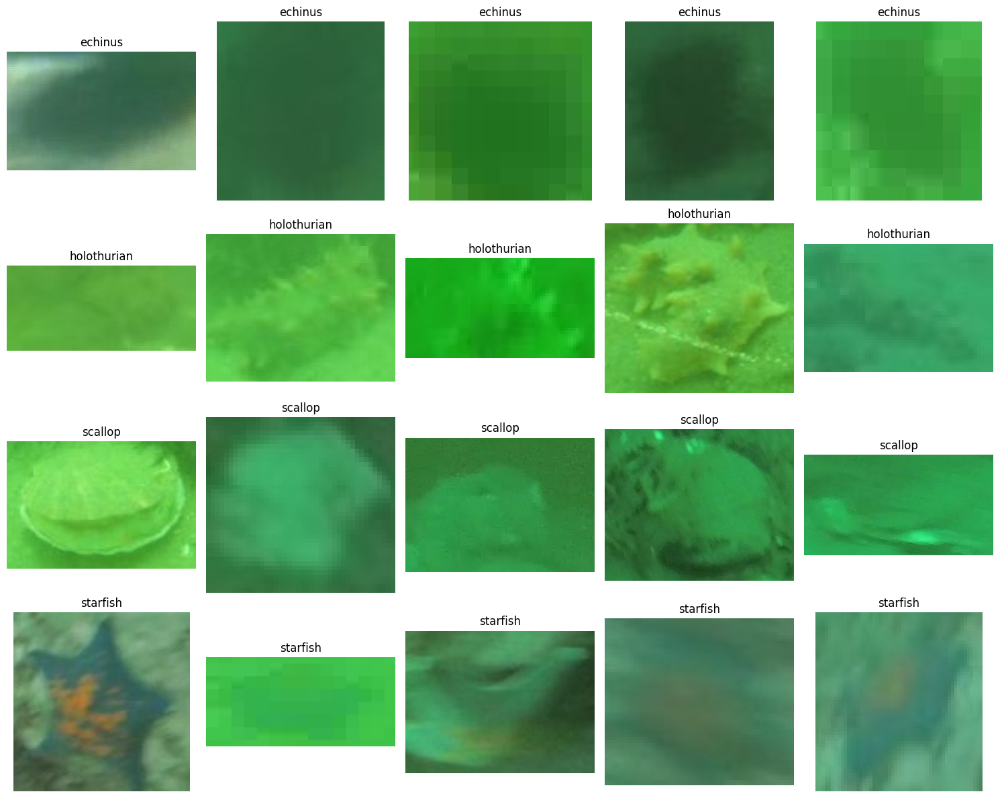

In [ ]:
fig, axes = plt.subplots(4, 5, figsize=(15, 12))

for row_idx, cls in enumerate(classes):
    class_df = train_meta[train_meta["class"] == cls]
    samples = class_df.sample(5, random_state=42)

    for col_idx, (_, row) in enumerate(samples.iterrows()):
        img = Image.open(row["filepath"]).convert("RGB")

        axes[row_idx, col_idx].imshow(img)
        axes[row_idx, col_idx].set_title(cls)
        axes[row_idx, col_idx].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
metadata["source_prefix"] = metadata["filename"].str.split("_").str[0]

train_prefixes = set(
    metadata[metadata["split"] == "train"]["source_prefix"]
)

test_prefixes = set(
    metadata[metadata["split"] == "test"]["source_prefix"]
)

overlap = train_prefixes.intersection(test_prefixes)

print("Train prefixes:", len(train_prefixes))
print("Test prefixes:", len(test_prefixes))
print("Overlapping prefixes:", len(overlap))

Train prefixes: 645
Test prefixes: 220
Overlapping prefixes: 27


In [ ]:
print("Example overlapping prefixes:")
print(list(overlap)[:20])

Example overlapping prefixes:
['000178', '001121', '000168', '000494', '000307', '000465', '000047', '000799', '001043', '000882', '000451', '000013', '000830', '000925', '000654', '000618', '000246', '000843', '000334', '000559']


In [ ]:
overlap_df = metadata[
    metadata["source_prefix"].isin(overlap)
].sort_values("source_prefix")

overlap_df[[
    "split",
    "class",
    "filename",
    "source_prefix"
]].head(30)

,split,class,filename,source_prefix
3728,test,holothurian,000013_fcae5ac6.jpg,000013
3829,test,holothurian,000013_7a251c7e.jpg,000013
1338,train,holothurian,000013_bbe64daf.jpg,000013
3142,train,starfish,000013_223d28ed.jpg,000013
1619,train,holothurian,000017_e79958a7.jpg,000017
3814,test,holothurian,000017_c7e71ef8.jpg,000017
3725,test,holothurian,000017_120a62ca.jpg,000017
3763,test,holothurian,000032_e061ddd9.jpg,000032
3776,test,holothurian,000032_c5620595.jpg,000032
901,train,holothurian,000032_fa4a6ca8.jpg,000032


In [ ]:
def image_hash(filepath):
    with open(filepath, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

metadata["file_hash"] = metadata["filepath"].apply(image_hash)

duplicate_hashes = metadata[
    metadata.duplicated("file_hash", keep=False)
].sort_values("file_hash")

print("Duplicate file entries:", len(duplicate_hashes))

Duplicate file entries: 0


In [ ]:
cross_split_duplicates = (
    duplicate_hashes.groupby("file_hash")["split"]
    .nunique()
)

print(
    "Hashes appearing in both train and test:",
    (cross_split_duplicates > 1).sum()
)

Hashes appearing in both train and test: 0


In [ ]:
CONFIG = {
    "seed": 42,
    "image_size": 224,
    "batch_size": 32,
    "num_classes": 4,
    "num_workers": 2,
    "epochs": 25,
    "learning_rate": 1e-4,
    "weight_decay": 1e-4,
    "model_name": "efficientnet_v2_s",
}

In [ ]:
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(42)

Prefixes selected for visual inspection:
['000178', '001121', '000168', '000494', '000307']

SOURCE PREFIX: 000178
split       class            filename  width  height
train    starfish 000178_6ed8ec3c.jpg    443     202
 test holothurian 000178_29523f03.jpg    844     265


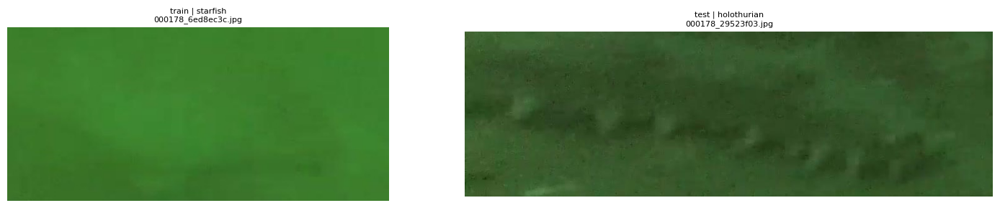


SOURCE PREFIX: 001121
split    class            filename  width  height
train  scallop 001121_43a38aa0.jpg    172     152
train  scallop 001121_cdac31c6.jpg    143     135
train  scallop 001121_dac4ac34.jpg    277     203
train  scallop 001121_da6f4044.jpg    232     159
train  scallop 001121_82ee3dc7.jpg    319     299
train  scallop 001121_8fb0a8fd.jpg    213     211
train  scallop 001121_2c35d34e.jpg    157     126
train  scallop 001121_eae9dcb7.jpg    195     164
train  scallop 001121_d450a513.jpg    160     123
train  scallop 001121_dcb7a2de.jpg    142     114
train  scallop 001121_6269c9b5.jpg    217     154
train  scallop 001121_bcf1d1ea.jpg    331     314
train  scallop 001121_a5169d1c.jpg    184     154
train  scallop 001121_354525c5.jpg    208     118
train  scallop 001121_704d08a2.jpg    171     140
train  scallop 001121_ddd5fd44.jpg    123     121
train  scallop 001121_16affab4.jpg    195     136
train  scallop 001121_16689907.jpg    164     145
 test  echinus 001121_9bec3

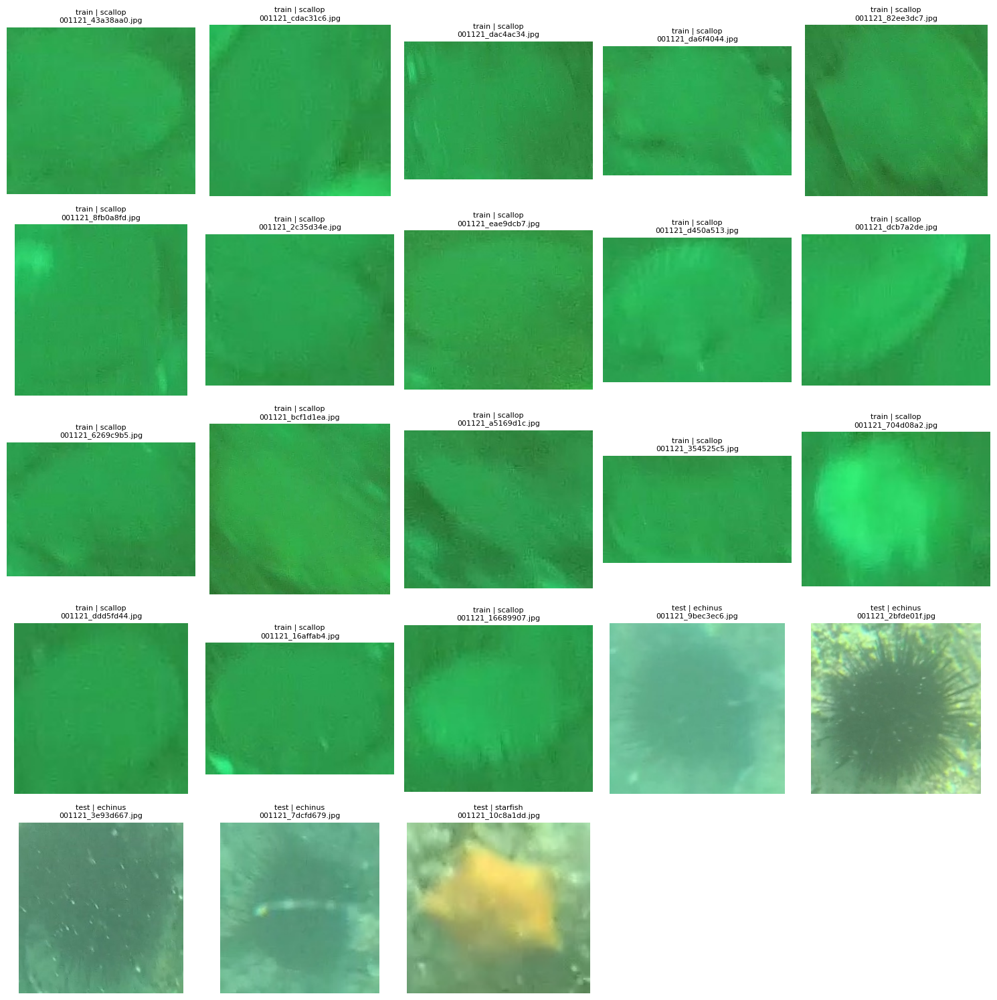


SOURCE PREFIX: 000168
split       class            filename  width  height
train     scallop 000168_7a8d479b.jpg    719     328
train     scallop 000168_a70494f5.jpg    476     226
 test holothurian 000168_6bb670fa.jpg    461     283


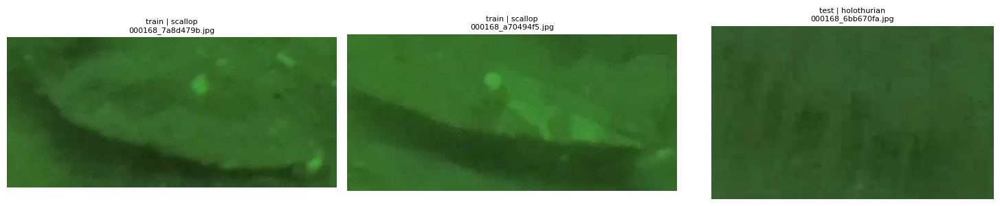


SOURCE PREFIX: 000494
split       class            filename  width  height
train     echinus 000494_9f16e131.jpg    853     500
train holothurian 000494_a4e1407d.jpg    564     398
train holothurian 000494_54ad97f5.jpg    605     361
 test     echinus 000494_ad5cb09f.jpg     86      84
 test     echinus 000494_44847102.jpg     50      61
 test     echinus 000494_dd52c3d2.jpg     94      91
 test     echinus 000494_1c1588b8.jpg     59      67
 test     echinus 000494_669272b3.jpg     57      50
 test holothurian 000494_9dfb4c5d.jpg     52      52
 test    starfish 000494_25a1f3ed.jpg     47      53
 test    starfish 000494_39410563.jpg     53      62
 test    starfish 000494_8fd0c469.jpg     61      47
 test    starfish 000494_7ed619ce.jpg     48      35
 test    starfish 000494_51f0bb79.jpg     34      32
 test    starfish 000494_f478eab3.jpg     63      42


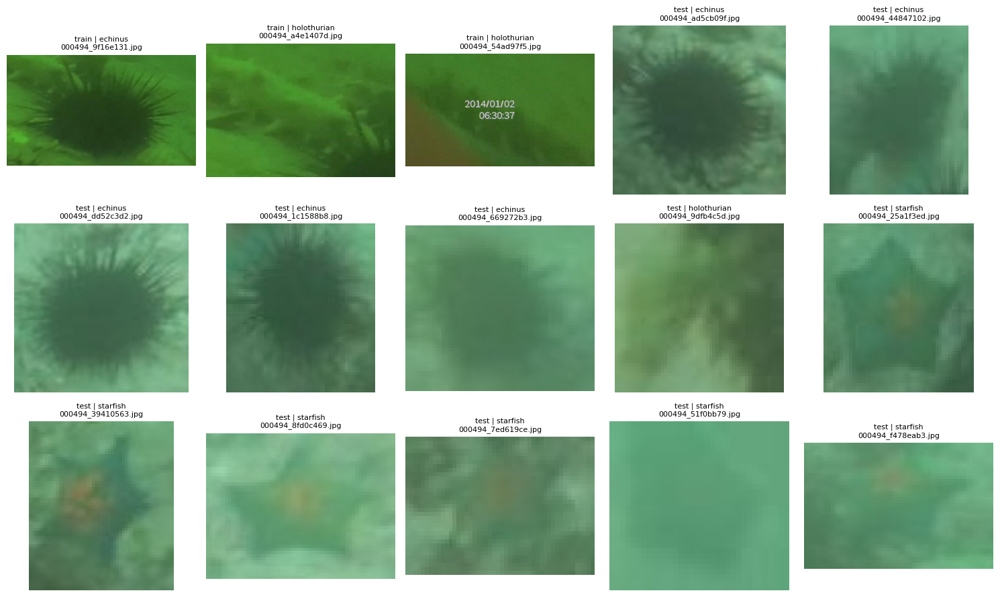


SOURCE PREFIX: 000307
split       class            filename  width  height
train holothurian 000307_cb4617cc.jpg    209     395
 test holothurian 000307_ac4305b7.jpg    275     307


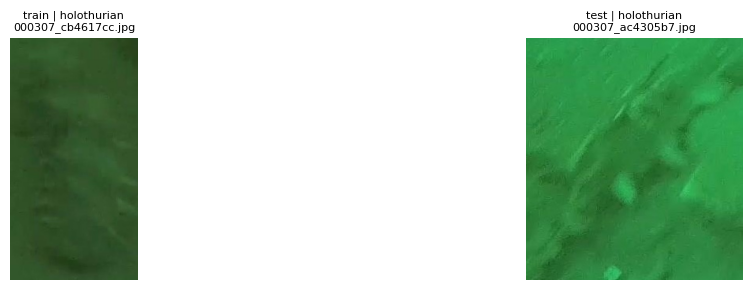

In [ ]:
# ============================================
# STEP 24: VISUAL INSPECTION OF OVERLAPPING GROUPS
# ============================================

import math

# Select a few overlapping prefixes
sample_prefixes = list(overlap)[:5]

print("Prefixes selected for visual inspection:")
print(sample_prefixes)

for prefix in sample_prefixes:

    group_df = metadata[
        metadata["source_prefix"] == prefix
    ]

    print("\n" + "="*70)
    print("SOURCE PREFIX:", prefix)
    print("="*70)

    print(
        group_df[
            ["split", "class", "filename", "width", "height"]
        ].to_string(index=False)
    )

    n_images = len(group_df)
    cols = min(5, n_images)
    rows = math.ceil(n_images / cols)

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(15, 3 * rows)
    )

    axes = np.array(axes).reshape(-1)

    for ax, (_, row) in zip(axes, group_df.iterrows()):

        try:
            img = Image.open(row["filepath"]).convert("RGB")

            ax.imshow(img)
            ax.set_title(
                f"{row['split']} | {row['class']}\n"
                f"{row['filename']}",
                fontsize=8
            )
            ax.axis("off")

        except Exception as e:
            ax.text(
                0.5,
                0.5,
                "Error",
                ha="center",
                va="center"
            )
            ax.axis("off")

    # Hide unused axes
    for ax in axes[n_images:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
# ============================================
# STEP 25: PREFIX DISTRIBUTION ANALYSIS
# ============================================

prefix_summary = (
    metadata
    .groupby(["source_prefix", "split"])
    .size()
    .unstack(fill_value=0)
)

prefix_summary["total"] = prefix_summary.sum(axis=1)

prefix_summary["cross_split"] = (
    (prefix_summary.get("train", 0) > 0) &
    (prefix_summary.get("test", 0) > 0)
)

print("Total unique prefixes:", len(prefix_summary))

print(
    "Prefixes appearing in both train and test:",
    prefix_summary["cross_split"].sum()
)

print("\nLargest prefixes:")
display(
    prefix_summary
    .sort_values("total", ascending=False)
    .head(30)
)

Total unique prefixes: 838
Prefixes appearing in both train and test: 27

Largest prefixes:


split,test,train,total,cross_split
source_prefix,,,,
002567,0,41,41,False
002553,0,37,37,False
000110,0,36,36,False
001094,0,31,31,False
001067,0,30,30,False
002593,0,30,30,False
000882,13,16,29,True
001069,0,29,29,False
000046,28,0,28,False


In [ ]:
# ============================================
# STEP 26A: ALL CROSS-SPLIT PREFIXES
# ============================================

cross_split_prefixes = prefix_summary[
    prefix_summary["cross_split"] == True
].index.tolist()

print("Number of cross-split prefixes:", len(cross_split_prefixes))

print("\nCross-split prefixes:")
for p in cross_split_prefixes:
    print(p)

Number of cross-split prefixes: 27

Cross-split prefixes:
000013
000017
000032
000047
000168
000178
000246
000307
000334
000451
000458
000465
000494
000559
000618
000649
000654
000700
000710
000754
000799
000830
000843
000882
000925
001043
001121


In [ ]:
# ============================================
# STEP 26B: CROSS-SPLIT PREFIX SUMMARY
# ============================================

cross_summary = prefix_summary[
    prefix_summary["cross_split"] == True
].copy()

display(
    cross_summary.sort_values(
        "total",
        ascending=False
    )
)

split,test,train,total,cross_split
source_prefix,,,,
000882,13,16,29,True
000618,10,17,27,True
001043,1,24,25,True
001121,5,18,23,True
000494,12,3,15,True
000654,5,8,13,True
000830,4,8,12,True
000843,6,5,11,True
000754,2,8,10,True


In [ ]:
# ============================================
# STEP 26C: CLASS DISTRIBUTION WITHIN
# CROSS-SPLIT PREFIXES
# ============================================

for prefix in cross_split_prefixes:

    group = metadata[
        metadata["source_prefix"] == prefix
    ]

    print("\n" + "=" * 70)
    print("PREFIX:", prefix)
    print("=" * 70)

    print("\nSplit distribution:")
    print(
        group["split"]
        .value_counts()
    )

    print("\nClass distribution:")
    print(
        pd.crosstab(
            group["split"],
            group["class"]
        )
    )


PREFIX: 000013

Split distribution:
split
train    2
test     2
Name: count, dtype: int64

Class distribution:
class  holothurian  starfish
split                       
test             2         0
train            1         1

PREFIX: 000017

Split distribution:
split
test     2
train    1
Name: count, dtype: int64

Class distribution:
class  holothurian
split             
test             2
train            1

PREFIX: 000032

Split distribution:
split
train    3
test     3
Name: count, dtype: int64

Class distribution:
class  holothurian
split             
test             3
train            3

PREFIX: 000047

Split distribution:
split
train    7
test     2
Name: count, dtype: int64

Class distribution:
class  echinus  holothurian  starfish
split                                
test         0            0         2
train        6            1         0

PREFIX: 000168

Split distribution:
split
train    2
test     1
Name: count, dtype: int64

Class distribution:
class  holothurian  


SOURCE PREFIX: 000013
split       class            filename  width  height
train holothurian 000013_bbe64daf.jpg    195     142
train    starfish 000013_223d28ed.jpg    175     143
 test holothurian 000013_fcae5ac6.jpg    378     304
 test holothurian 000013_7a251c7e.jpg    304     276


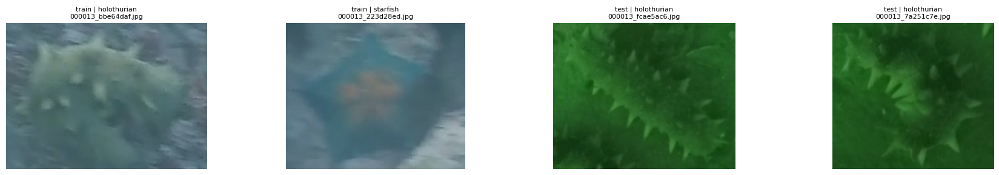


SOURCE PREFIX: 000017
split       class            filename  width  height
train holothurian 000017_e79958a7.jpg    176     417
 test holothurian 000017_120a62ca.jpg    229     149
 test holothurian 000017_c7e71ef8.jpg    210      94


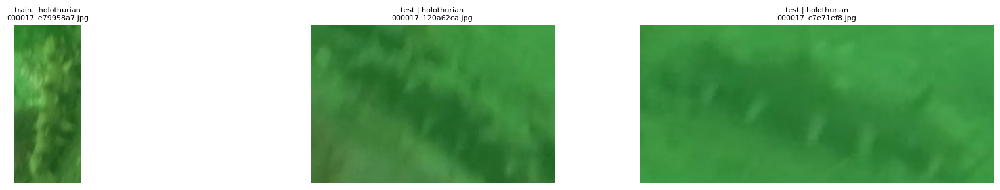


SOURCE PREFIX: 000032
split       class            filename  width  height
train holothurian 000032_fa4a6ca8.jpg    117      34
train holothurian 000032_bab62676.jpg     87      95
train holothurian 000032_9012731e.jpg     99     153
 test holothurian 000032_e061ddd9.jpg    217      90
 test holothurian 000032_c5620595.jpg    147      72
 test holothurian 000032_a1c74a78.jpg    157     147


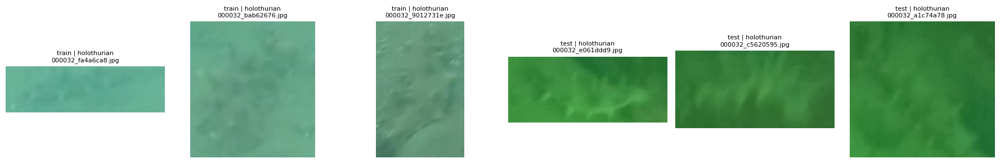


SOURCE PREFIX: 000047
split       class            filename  width  height
train     echinus 000047_dd722bb2.jpg     90     176
train     echinus 000047_fc6898d8.jpg    155     137
train     echinus 000047_e106683b.jpg    138      96
train     echinus 000047_ca2f73fd.jpg    130     145
train     echinus 000047_19afea28.jpg    151     163
train     echinus 000047_7f1ff254.jpg    147     115
train holothurian 000047_9c28e4b9.jpg    104     194
 test    starfish 000047_67a47a0f.jpg    140     159
 test    starfish 000047_f5dce244.jpg    137     143


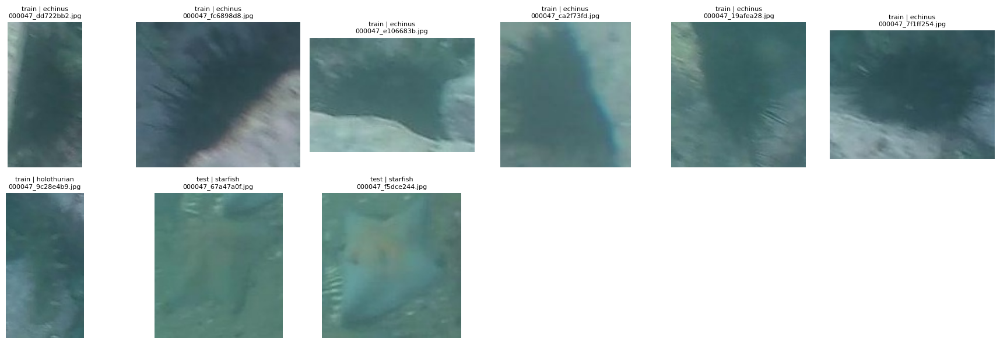


SOURCE PREFIX: 000168
split       class            filename  width  height
train     scallop 000168_7a8d479b.jpg    719     328
train     scallop 000168_a70494f5.jpg    476     226
 test holothurian 000168_6bb670fa.jpg    461     283


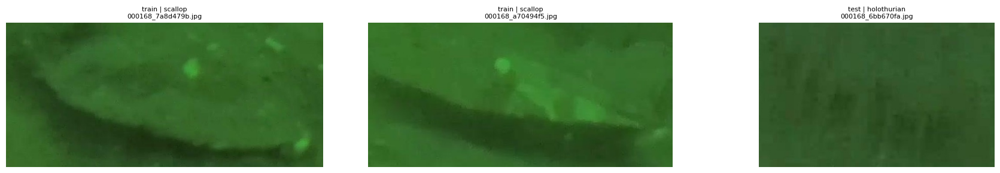


SOURCE PREFIX: 000178
split       class            filename  width  height
train    starfish 000178_6ed8ec3c.jpg    443     202
 test holothurian 000178_29523f03.jpg    844     265


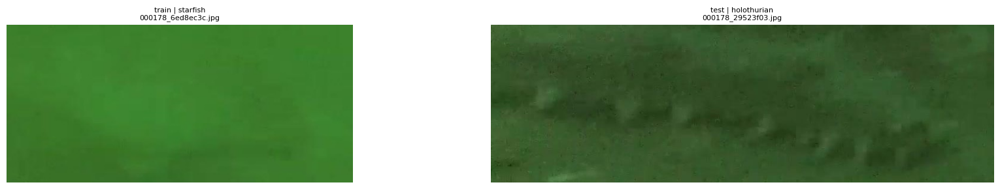


SOURCE PREFIX: 000246
split       class            filename  width  height
train holothurian 000246_bdb7ef10.jpg    749     243
 test holothurian 000246_57ca54ea.jpg    656     255
 test holothurian 000246_3dcd1345.jpg    415     203


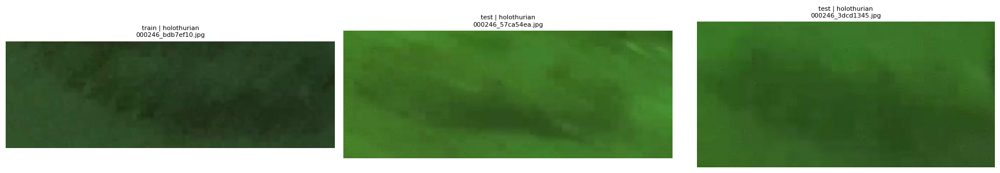


SOURCE PREFIX: 000307
split       class            filename  width  height
train holothurian 000307_cb4617cc.jpg    209     395
 test holothurian 000307_ac4305b7.jpg    275     307


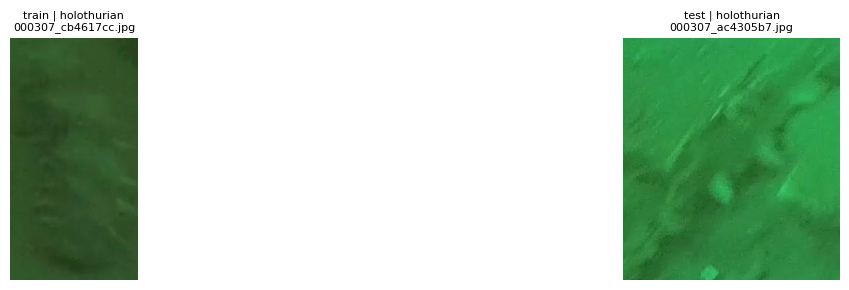


SOURCE PREFIX: 000334
split       class            filename  width  height
train holothurian 000334_bdad1539.jpg    901     454
 test    starfish 000334_2bd629a7.jpg    331     268


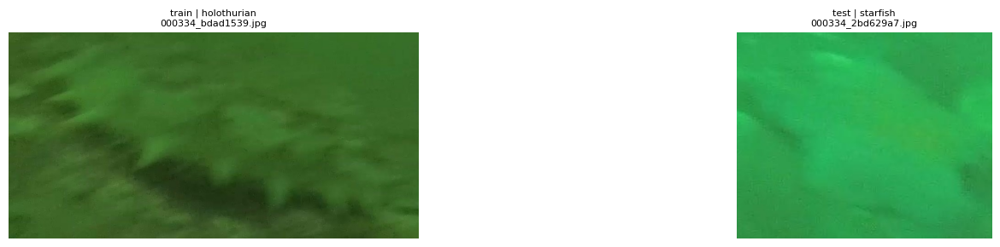


SOURCE PREFIX: 000451
split       class            filename  width  height
train holothurian 000451_a4d849ef.jpg    674     224
train holothurian 000451_28029f73.jpg   1056     573
 test holothurian 000451_77ae8466.jpg    268     206


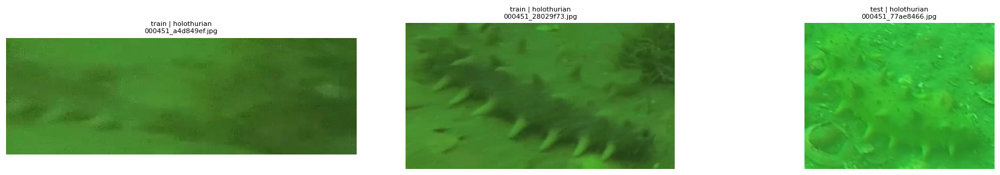


SOURCE PREFIX: 000458
split       class            filename  width  height
train holothurian 000458_d57fcd83.jpg    604     464
train holothurian 000458_ebbd7169.jpg    436     296
 test holothurian 000458_f82070ee.jpg    387     181


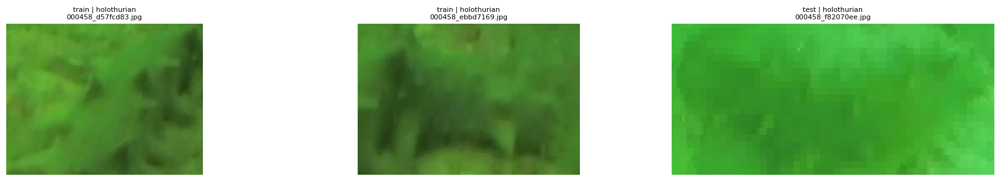


SOURCE PREFIX: 000465
split       class            filename  width  height
train holothurian 000465_d915354f.jpg    326     371
train    starfish 000465_2cdb9f21.jpg   1024     949
 test holothurian 000465_4507bb92.jpg    114     150


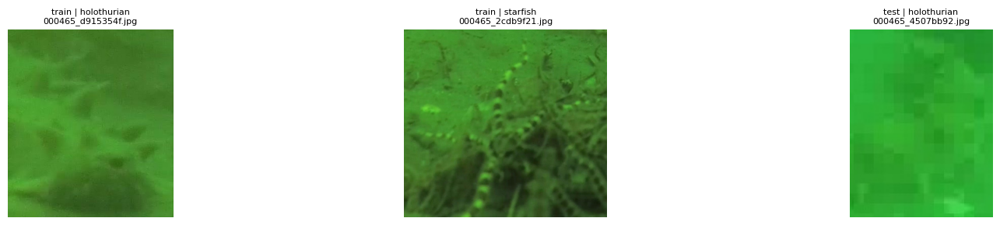


SOURCE PREFIX: 000494
split       class            filename  width  height
train     echinus 000494_9f16e131.jpg    853     500
train holothurian 000494_a4e1407d.jpg    564     398
train holothurian 000494_54ad97f5.jpg    605     361
 test     echinus 000494_ad5cb09f.jpg     86      84
 test     echinus 000494_44847102.jpg     50      61
 test     echinus 000494_dd52c3d2.jpg     94      91
 test     echinus 000494_1c1588b8.jpg     59      67
 test     echinus 000494_669272b3.jpg     57      50
 test holothurian 000494_9dfb4c5d.jpg     52      52
 test    starfish 000494_25a1f3ed.jpg     47      53
 test    starfish 000494_39410563.jpg     53      62
 test    starfish 000494_8fd0c469.jpg     61      47
 test    starfish 000494_7ed619ce.jpg     48      35
 test    starfish 000494_51f0bb79.jpg     34      32
 test    starfish 000494_f478eab3.jpg     63      42


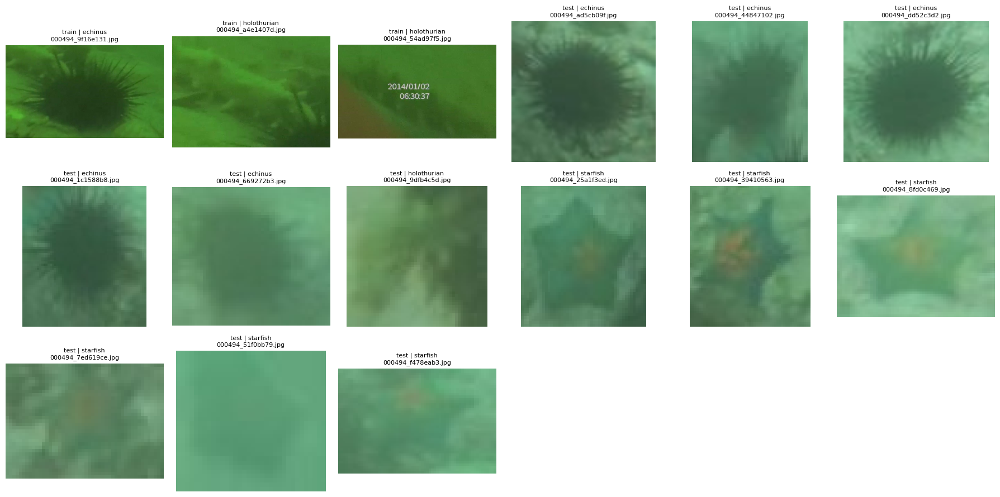


SOURCE PREFIX: 000559
split       class            filename  width  height
train holothurian 000559_bf001858.jpg    320     419
 test holothurian 000559_4bfdd65b.jpg     77      93
 test holothurian 000559_26186ae0.jpg     46     105
 test    starfish 000559_7679a3f6.jpg     51      46
 test    starfish 000559_71fb281b.jpg     65      48
 test    starfish 000559_4b88e8d9.jpg     29      64


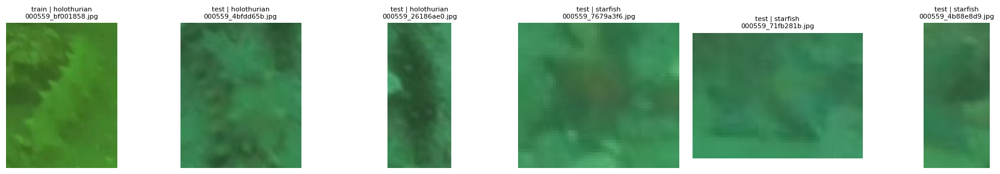


SOURCE PREFIX: 000618
split       class            filename  width  height
train holothurian 000618_34c01b14.jpg    568     655
train holothurian 000618_f99adf8b.jpg    505     401
train holothurian 000618_74d22f2f.jpg    382     143
train holothurian 000618_cf69810d.jpg    398     235
train holothurian 000618_ea78e62f.jpg    459     312
train     scallop 000618_d47c38fe.jpg    184     184
train     scallop 000618_6c0be6c8.jpg    399     384
train     scallop 000618_52191b09.jpg    234     168
train     scallop 000618_c62d9eec.jpg    339     251
train     scallop 000618_0d30ef82.jpg    185     271
train     scallop 000618_0327a960.jpg    206     193
train     scallop 000618_546fb69e.jpg    215     201
train     scallop 000618_798d737e.jpg    198     116
train     scallop 000618_2c552853.jpg    302     292
train    starfish 000618_2de31f75.jpg    384     237
train    starfish 000618_279c7f76.jpg    163     348
train    starfish 000618_9409b223.jpg    268     338
 test     echinus 00061

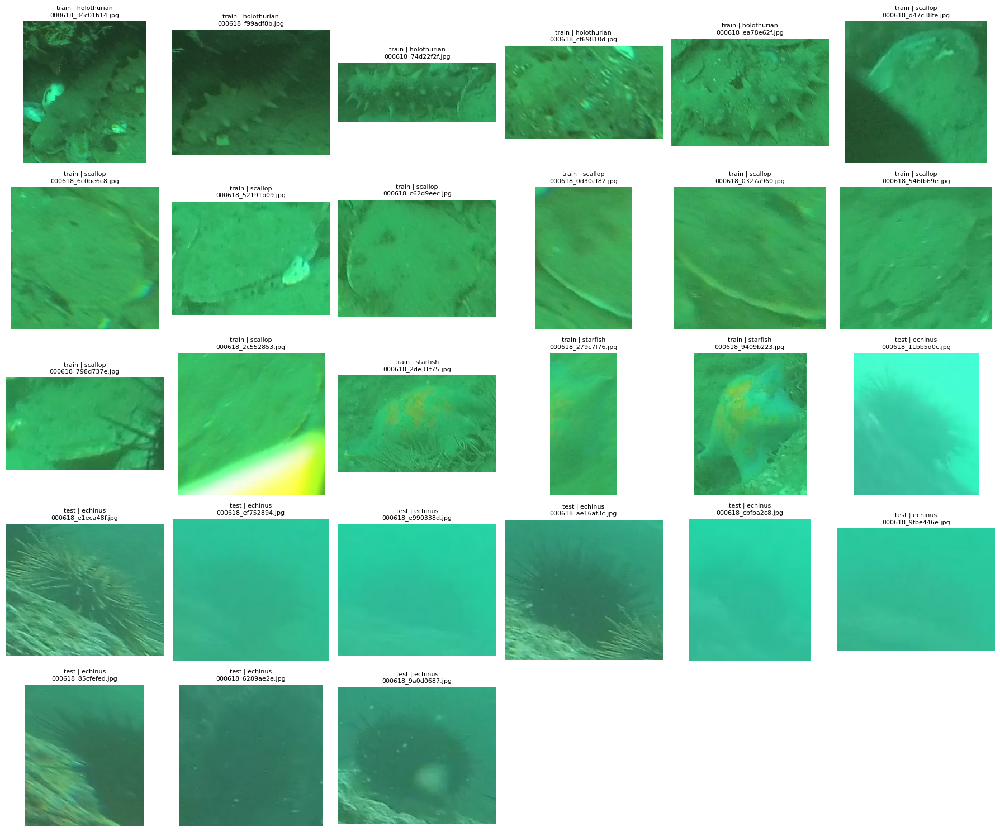


SOURCE PREFIX: 000649
split       class            filename  width  height
train holothurian 000649_88c6e314.jpg    290     207
 test    starfish 000649_da446d05.jpg     59      43


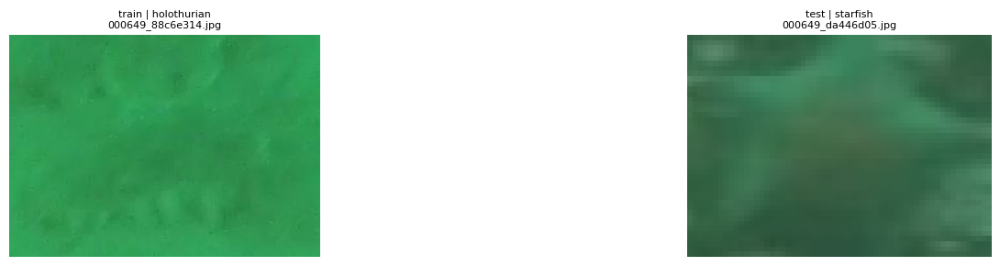


SOURCE PREFIX: 000654
split       class            filename  width  height
train holothurian 000654_3c17621c.jpg    109     199
train    starfish 000654_8b98f5aa.jpg    220     164
train    starfish 000654_b297554b.jpg    150     107
train    starfish 000654_69206e80.jpg    254     218
train    starfish 000654_0c6971e8.jpg    244     152
train    starfish 000654_343c14de.jpg    138     109
train    starfish 000654_c0e761aa.jpg    208     191
train    starfish 000654_fae50c61.jpg    228     207
 test     echinus 000654_e4277042.jpg     71      71
 test     echinus 000654_ce872aff.jpg     59      52
 test     echinus 000654_8ee46d4f.jpg     68      71
 test     echinus 000654_ef9b43fe.jpg     57      66
 test holothurian 000654_e1506349.jpg     91      45


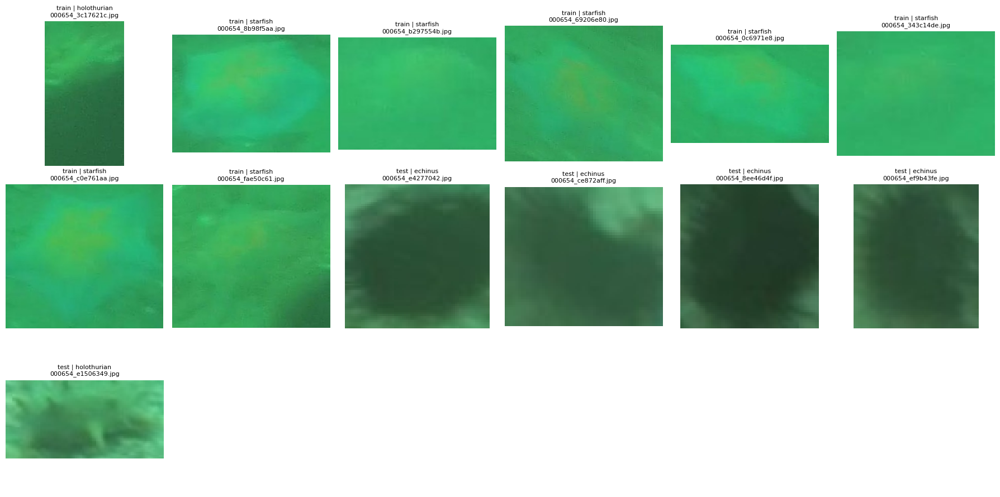


SOURCE PREFIX: 000700
split       class            filename  width  height
train     scallop 000700_56365543.jpg    259     229
train     scallop 000700_dee81ded.jpg    660     513
train     scallop 000700_8b0b1d98.jpg    196      90
train     scallop 000700_4ea5c3a7.jpg    177     116
train     scallop 000700_f236c71e.jpg    232     102
train     scallop 000700_b009a840.jpg    343     326
train     scallop 000700_234afa2c.jpg    374     292
 test holothurian 000700_65fed51f.jpg    266      96


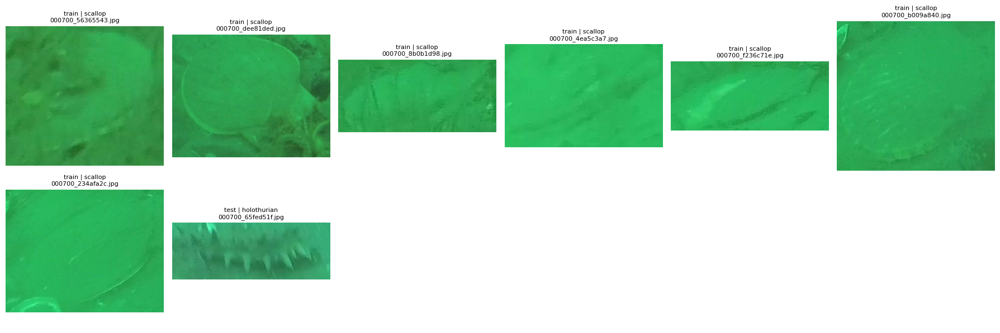


SOURCE PREFIX: 000710
split   class            filename  width  height
train scallop 000710_4a9f5c7a.jpg    184     135
train scallop 000710_b659ed00.jpg    213     164
train scallop 000710_45906ed3.jpg    145     106
train scallop 000710_e71b945c.jpg    162     152
 test echinus 000710_cc262922.jpg    165     144
 test echinus 000710_cfdafbcb.jpg    157     119
 test echinus 000710_8a8b65ec.jpg    178     183
 test echinus 000710_a5f2963b.jpg    119     132


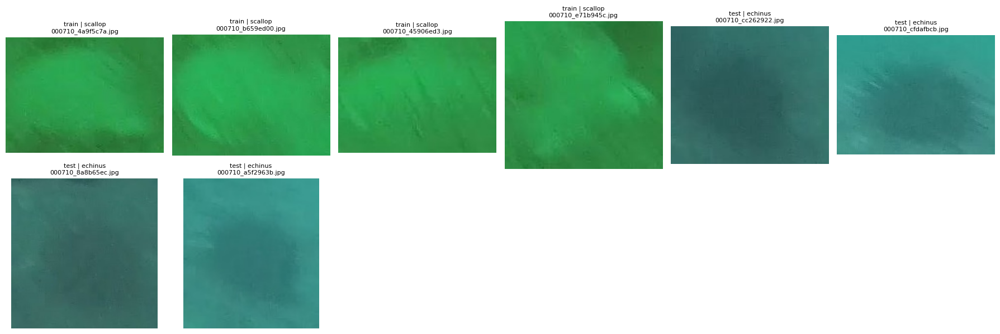


SOURCE PREFIX: 000754
split    class            filename  width  height
train  scallop 000754_f4e2e9c2.jpg    152      94
train  scallop 000754_dbb1e599.jpg    193     121
train  scallop 000754_c485ad4e.jpg    169     128
train  scallop 000754_ba13fba0.jpg     82      65
train  scallop 000754_f0902021.jpg    188     119
train  scallop 000754_6e5fa3e6.jpg    142      82
train starfish 000754_470608a5.jpg    228     135
train starfish 000754_50f0ce93.jpg    385     244
 test starfish 000754_aef80f40.jpg     58      43
 test starfish 000754_79e62410.jpg     40      59


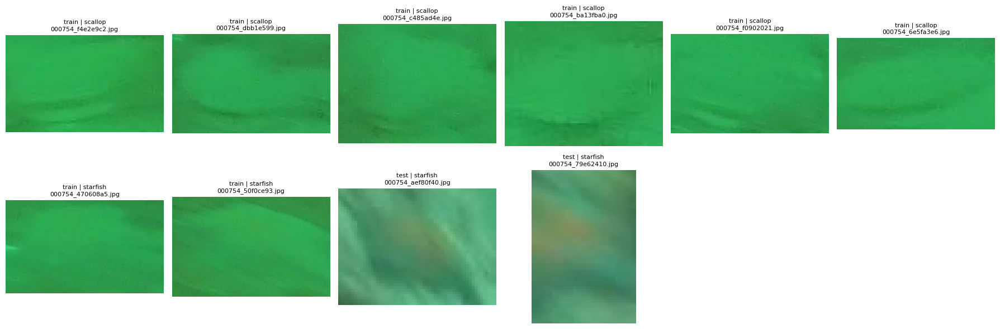


SOURCE PREFIX: 000799
split    class            filename  width  height
train  scallop 000799_46e8913c.jpg    210     161
train  scallop 000799_b09f1eba.jpg     91      46
train  scallop 000799_42107398.jpg    213     114
train  scallop 000799_5e8d5ce4.jpg    305     190
train  scallop 000799_66c0174e.jpg    407     224
 test starfish 000799_a4dcd7da.jpg    247     216
 test starfish 000799_24089bcb.jpg    107     244


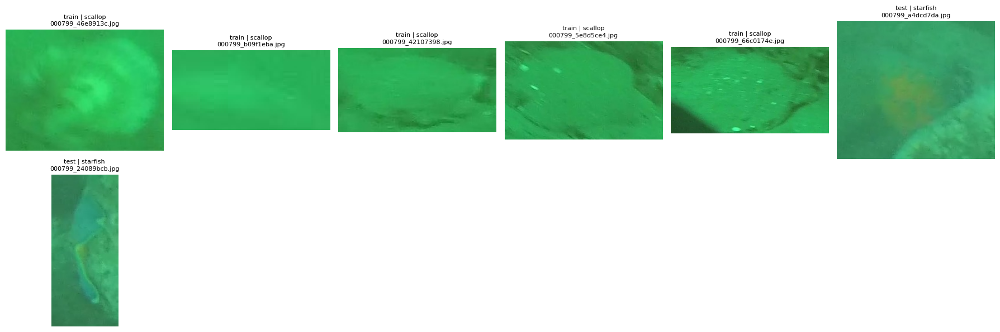


SOURCE PREFIX: 000830
split       class            filename  width  height
train     scallop 000830_34ce3973.jpg    122     114
train     scallop 000830_ed48b1bc.jpg    237     168
train     scallop 000830_38609697.jpg    164      91
train     scallop 000830_5ad4fcaa.jpg    256     134
train     scallop 000830_4bde388a.jpg    114     105
train     scallop 000830_9dab777b.jpg    339     288
train     scallop 000830_322647ad.jpg     42      59
train    starfish 000830_64f49845.jpg    240     135
 test holothurian 000830_d9b3a678.jpg    426     394
 test holothurian 000830_4ae7c344.jpg    394     182
 test    starfish 000830_aa43fada.jpg    194     216
 test    starfish 000830_f1ff142f.jpg    189     202


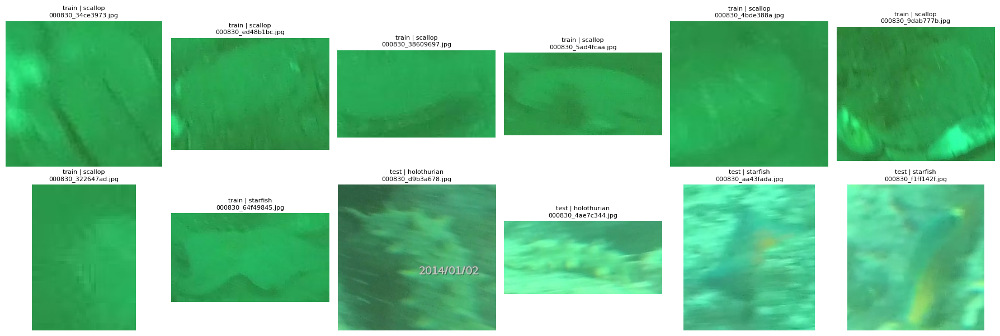


SOURCE PREFIX: 000843
split       class            filename  width  height
train     scallop 000843_a28a46f1.jpg    153     115
train     scallop 000843_2de73669.jpg    217      66
train     scallop 000843_848df08d.jpg     95     105
train    starfish 000843_89a73186.jpg    234     144
train    starfish 000843_04b908b0.jpg    164     105
 test holothurian 000843_53dc2dfc.jpg    400     494
 test holothurian 000843_cf3b1a31.jpg    281     142
 test holothurian 000843_27048a49.jpg    169     289
 test holothurian 000843_3903d6db.jpg    198     136
 test    starfish 000843_1da9d100.jpg    161     182
 test    starfish 000843_b7394b74.jpg    236     301


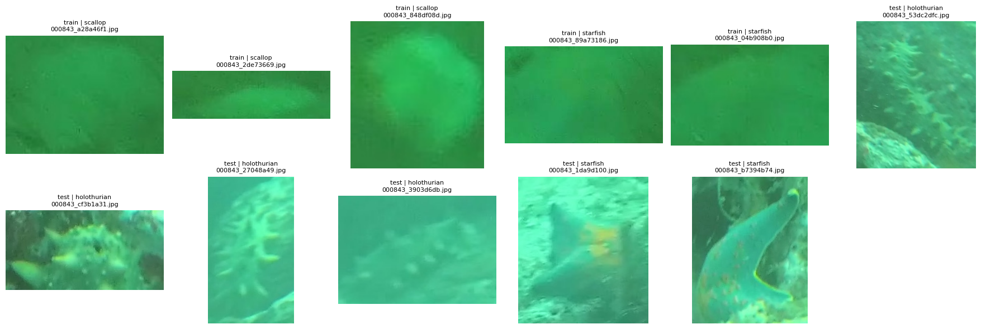


SOURCE PREFIX: 000882
split    class            filename  width  height
train  scallop 000882_c8ed1ebe.jpg    276     305
train  scallop 000882_d1008a03.jpg    396     247
train  scallop 000882_150c9f06.jpg    175     190
train  scallop 000882_a2c8db3f.jpg    181     227
train  scallop 000882_cc090123.jpg    153     128
train  scallop 000882_72fd1300.jpg    113     163
train  scallop 000882_a746c065.jpg    256     145
train  scallop 000882_1cad1f6f.jpg    520     385
train  scallop 000882_6fa8d81c.jpg    247     264
train  scallop 000882_75eaa249.jpg    220     232
train  scallop 000882_c152f20a.jpg    171     184
train  scallop 000882_270c7af9.jpg    173     188
train  scallop 000882_fe80261a.jpg    178     181
train  scallop 000882_42ba69aa.jpg    476     369
train starfish 000882_fc9a4bf7.jpg    152      78
train starfish 000882_95ec58b6.jpg    220     115
 test  echinus 000882_535c1850.jpg    146     138
 test  echinus 000882_0b7475d5.jpg    214     208
 test  echinus 000882_b2f23

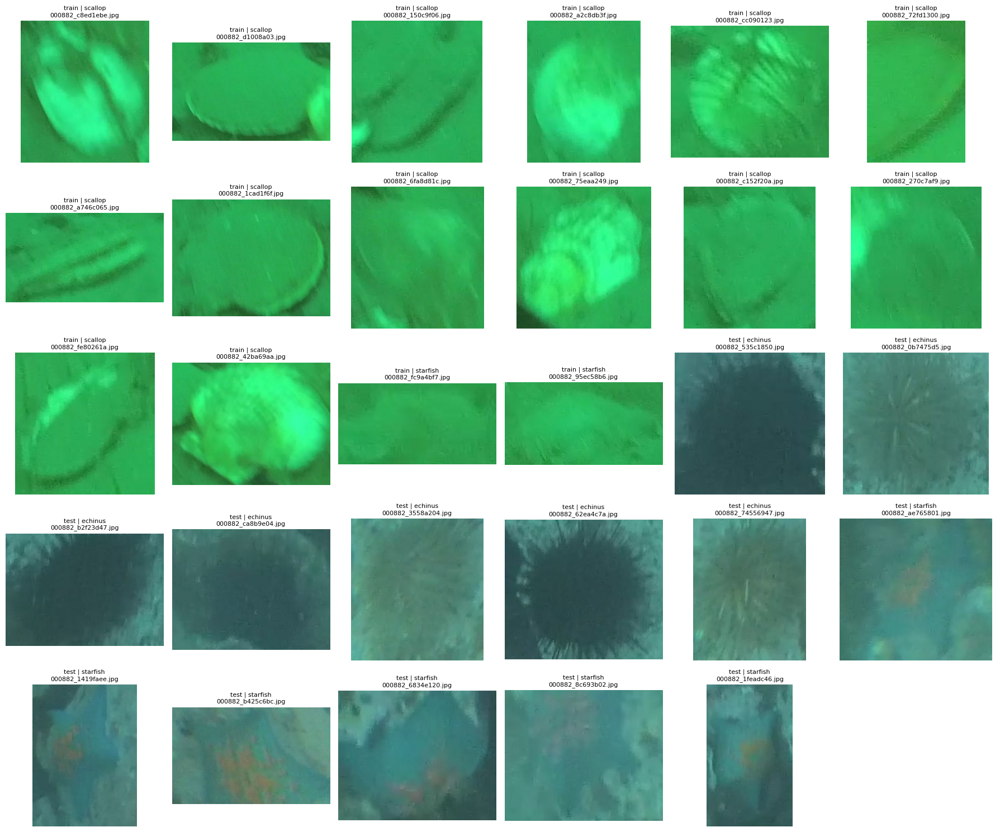


SOURCE PREFIX: 000925
split    class            filename  width  height
train  scallop 000925_73944eae.jpg    593     322
train starfish 000925_7a9e10b3.jpg    440     276
train starfish 000925_67fb4f9c.jpg    512     374
 test  echinus 000925_a13b84f9.jpg    193     123
 test  echinus 000925_1bba0ccf.jpg    172     131
 test  echinus 000925_cb8b7afe.jpg    174     120
 test  echinus 000925_db45a380.jpg    156      97
 test starfish 000925_73a680c1.jpg    147     146
 test starfish 000925_bea515b0.jpg    126     143


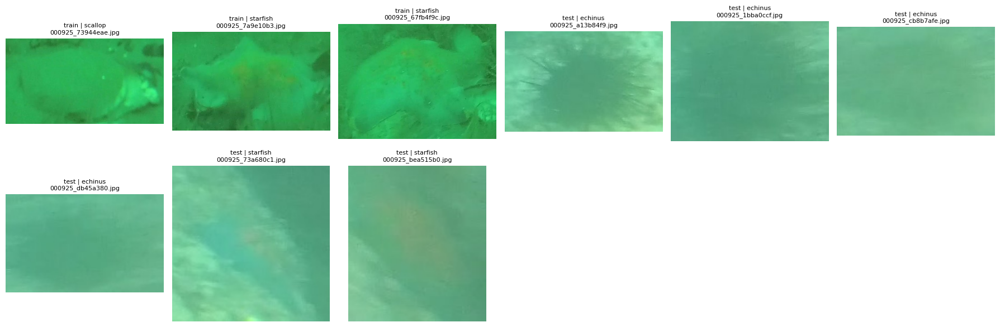


SOURCE PREFIX: 001043
split       class            filename  width  height
train holothurian 001043_f5db94c3.jpg    457     276
train     scallop 001043_b61cf503.jpg    206     156
train     scallop 001043_e1115c04.jpg    233     206
train     scallop 001043_8cb931ca.jpg    273     208
train     scallop 001043_d196ba02.jpg    243     187
train     scallop 001043_59f475ec.jpg    271     214
train     scallop 001043_5a603d7b.jpg    212     156
train     scallop 001043_dd65a91c.jpg    217     174
train     scallop 001043_9be0d6ee.jpg    131     115
train     scallop 001043_c0aa0c3e.jpg    349     287
train     scallop 001043_fcc640aa.jpg    208     196
train     scallop 001043_2dc5e641.jpg    201     190
train     scallop 001043_341b113b.jpg    299     281
train     scallop 001043_7c7ed74e.jpg    174     118
train     scallop 001043_941e2eb0.jpg    177     139
train     scallop 001043_32775e5f.jpg    158     124
train     scallop 001043_d6efcbcf.jpg    182      99
train     scallop 00104

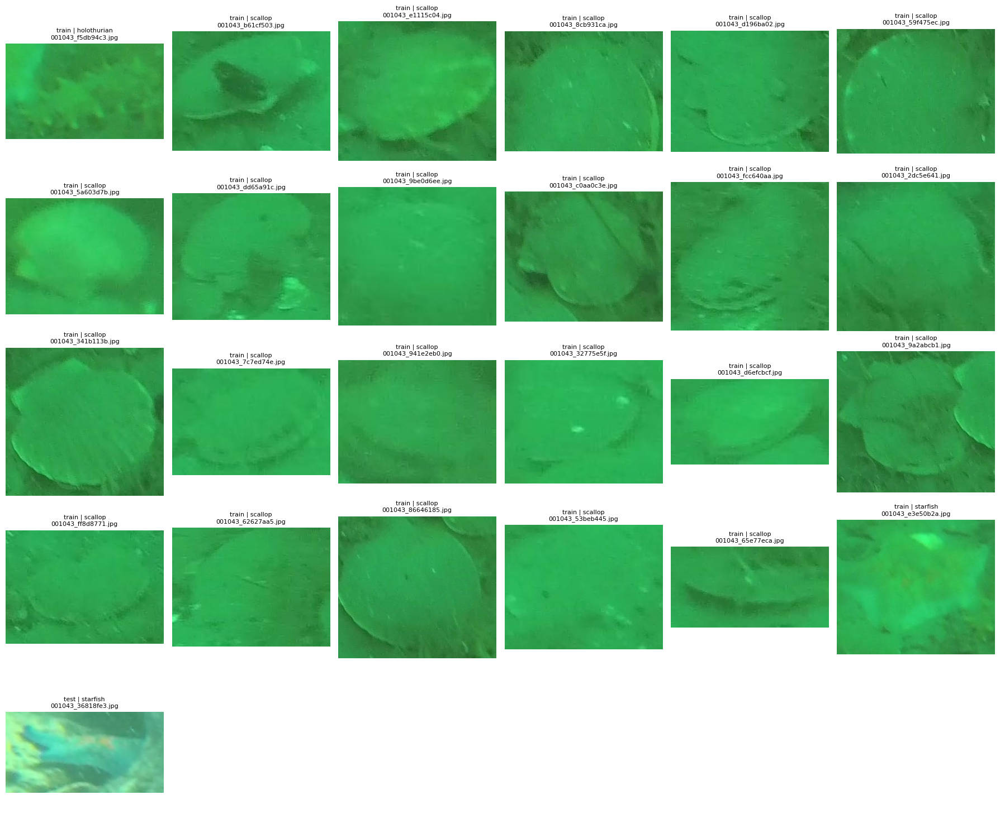


SOURCE PREFIX: 001121
split    class            filename  width  height
train  scallop 001121_43a38aa0.jpg    172     152
train  scallop 001121_cdac31c6.jpg    143     135
train  scallop 001121_dac4ac34.jpg    277     203
train  scallop 001121_da6f4044.jpg    232     159
train  scallop 001121_82ee3dc7.jpg    319     299
train  scallop 001121_8fb0a8fd.jpg    213     211
train  scallop 001121_2c35d34e.jpg    157     126
train  scallop 001121_eae9dcb7.jpg    195     164
train  scallop 001121_d450a513.jpg    160     123
train  scallop 001121_dcb7a2de.jpg    142     114
train  scallop 001121_6269c9b5.jpg    217     154
train  scallop 001121_bcf1d1ea.jpg    331     314
train  scallop 001121_a5169d1c.jpg    184     154
train  scallop 001121_354525c5.jpg    208     118
train  scallop 001121_704d08a2.jpg    171     140
train  scallop 001121_ddd5fd44.jpg    123     121
train  scallop 001121_16affab4.jpg    195     136
train  scallop 001121_16689907.jpg    164     145
 test  echinus 001121_9bec3

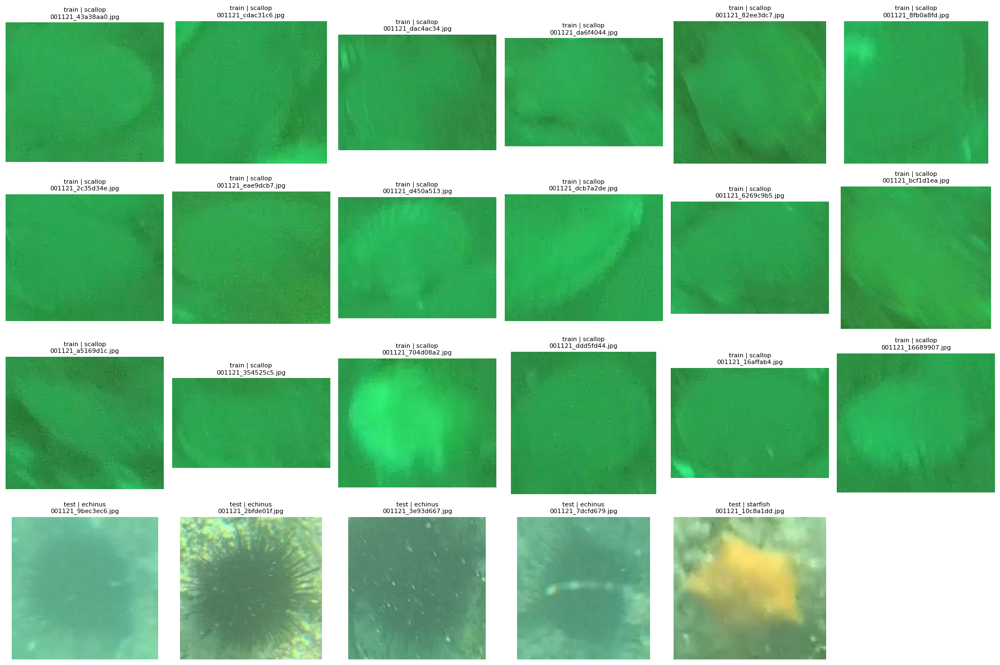

In [ ]:
# ============================================
# STEP 26D: VISUALIZE ALL CROSS-SPLIT PREFIXES
# ============================================

for prefix in cross_split_prefixes:

    group_df = metadata[
        metadata["source_prefix"] == prefix
    ].reset_index(drop=True)

    print("\n" + "=" * 80)
    print(f"SOURCE PREFIX: {prefix}")
    print("=" * 80)

    print(
        group_df[
            ["split", "class", "filename", "width", "height"]
        ].to_string(index=False)
    )

    n_images = len(group_df)

    cols = min(6, n_images)
    rows = math.ceil(n_images / cols)

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(18, 3 * rows)
    )

    axes = np.array(axes).reshape(-1)

    for ax, (_, row) in zip(
        axes,
        group_df.iterrows()
    ):

        try:

            img = Image.open(
                row["filepath"]
            ).convert("RGB")

            ax.imshow(img)

            ax.set_title(
                f"{row['split']} | {row['class']}\n"
                f"{row['filename']}",
                fontsize=8
            )

            ax.axis("off")

        except Exception as e:

            ax.text(
                0.5,
                0.5,
                "Error",
                ha="center",
                va="center"
            )

            ax.axis("off")

    for ax in axes[n_images:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
# ============================================
# STEP 27A: CREATE TRAIN / VALIDATION SPLIT
# ============================================

from sklearn.model_selection import train_test_split

# Copy original training metadata
train_metadata = metadata[
    metadata["split"] == "train"
].copy()

# Test metadata remains completely untouched
test_metadata = metadata[
    metadata["split"] == "test"
].copy()

print("Original training images:", len(train_metadata))
print("Test images:", len(test_metadata))

# Stratified 80/20 split
train_df, val_df = train_test_split(
    train_metadata,
    test_size=0.20,
    stratify=train_metadata["class"],
    random_state=42
)

# Reset indexes
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_metadata.reset_index(drop=True)

print("\nFinal dataset sizes:")
print("Training   :", len(train_df))
print("Validation :", len(val_df))
print("Test       :", len(test_df))

Original training images: 3480
Test images: 870

Final dataset sizes:
Training   : 2784
Validation : 696
Test       : 870


In [ ]:
# ============================================
# STEP 27B: VERIFY CLASS BALANCE
# ============================================

print("Training distribution:")
print(train_df["class"].value_counts().sort_index())

print("\nValidation distribution:")
print(val_df["class"].value_counts().sort_index())

print("\nTest distribution:")
print(test_df["class"].value_counts().sort_index())

Training distribution:
class
echinus        696
holothurian    696
scallop        696
starfish       696
Name: count, dtype: int64

Validation distribution:
class
echinus        174
holothurian    174
scallop        174
starfish       174
Name: count, dtype: int64

Test distribution:
class
echinus        218
holothurian    218
scallop        217
starfish       217
Name: count, dtype: int64


In [ ]:
# ============================================
# STEP 27C: SAVE DATA SPLITS
# ============================================

train_df.to_csv(
    "/content/train_split.csv",
    index=False
)

val_df.to_csv(
    "/content/val_split.csv",
    index=False
)

test_df.to_csv(
    "/content/test_split.csv",
    index=False
)

print("Train/validation/test split files saved.")

Train/validation/test split files saved.


In [ ]:
# ============================================
# STEP 28A: CLASS CONFIGURATION
# ============================================

class_names = sorted(train_df["class"].unique())

class_to_idx = {
    cls_name: idx
    for idx, cls_name in enumerate(class_names)
}

idx_to_class = {
    idx: cls_name
    for cls_name, idx in class_to_idx.items()
}

print("Classes:", class_names)
print("Class to index:", class_to_idx)

Classes: ['echinus', 'holothurian', 'scallop', 'starfish']
Class to index: {'echinus': 0, 'holothurian': 1, 'scallop': 2, 'starfish': 3}


In [ ]:
# ============================================
# STEP 28B: IMAGE TRANSFORMS
# ============================================

from torchvision import transforms

IMAGE_SIZE = 224

train_transform = transforms.Compose([
    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        degrees=10
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


val_test_transform = transforms.Compose([
    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [ ]:
# ============================================
# STEP 28C: CUSTOM PYTORCH DATASET
# ============================================

from torch.utils.data import Dataset
from PIL import Image
import torch

class UnderwaterDataset(Dataset):

    def __init__(
        self,
        dataframe,
        class_to_idx,
        transform=None
    ):

        self.dataframe = dataframe.reset_index(
            drop=True
        )

        self.class_to_idx = class_to_idx
        self.transform = transform

    def __len__(self):

        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_path = row["filepath"]
        class_name = row["class"]

        # Load image
        image = Image.open(
            image_path
        ).convert("RGB")

        # Apply transformation
        if self.transform:
            image = self.transform(image)

        # Convert class name to numerical label
        label = self.class_to_idx[class_name]

        return image, label

In [ ]:
# ============================================
# STEP 28D: CREATE DATASETS
# ============================================

train_dataset = UnderwaterDataset(
    train_df,
    class_to_idx,
    transform=train_transform
)

val_dataset = UnderwaterDataset(
    val_df,
    class_to_idx,
    transform=val_test_transform
)

test_dataset = UnderwaterDataset(
    test_df,
    class_to_idx,
    transform=val_test_transform
)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

Training dataset: 2784
Validation dataset: 696
Test dataset: 870


In [ ]:
# ============================================
# STEP 28E: PYTORCH DATALOADERS
# ============================================

from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders created.")

DataLoaders created.


In [ ]:
# ============================================
# STEP 28F: CHECK A BATCH
# ============================================

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

print("Labels:", labels[:10])

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Image dtype: torch.float32
Label dtype: torch.int64
Labels: tensor([0, 2, 0, 1, 2, 2, 3, 3, 0, 2])


Device: cuda
GPU: Tesla T4

Baseline CNN:
BaselineCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): 

Training:   0%|          | 0/87 [00:00<?, ?it/s]

Validation:   0%|          | 0/22 [00:00<?, ?it/s]

✓ Best model updated
Train Loss: 1.1469 | Train Accuracy: 0.4982
Val Loss:   1.0208 | Val Accuracy: 0.5718
Learning Rate: 0.000100

Epoch 2/25


Training:   0%|          | 0/87 [00:00<?, ?it/s]

...

Train Loss: 0.7702 | Train Accuracy: 0.6943
Val Loss:   0.7701 | Val Accuracy: 0.6925
Learning Rate: 0.000100

Epoch 25/25


Training:   0%|          | 0/87 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a0333478f40>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    
self._shutdown_workers()  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a0333478f40>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Validation:   0%|          | 0/22 [00:00<?, ?it/s]

Train Loss: 0.7515 | Train Accuracy: 0.7101
Val Loss:   0.7436 | Val Accuracy: 0.6983
Learning Rate: 0.000050

BASELINE CNN TRAINING COMPLETED
Best Validation Loss: 0.7324


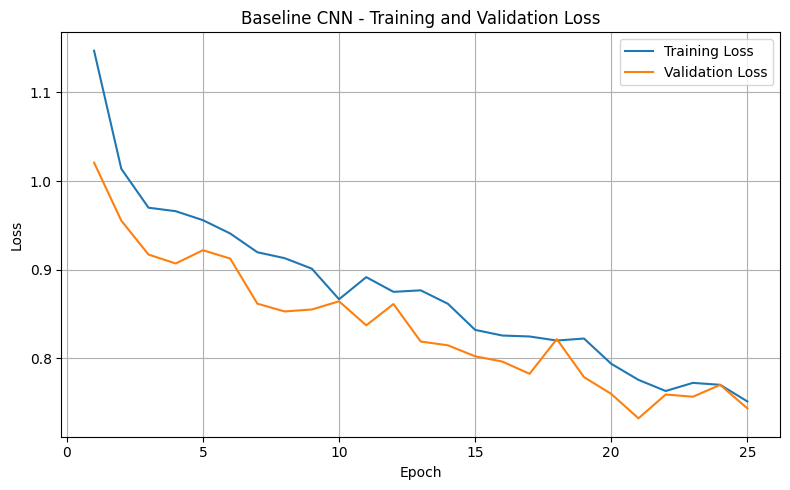

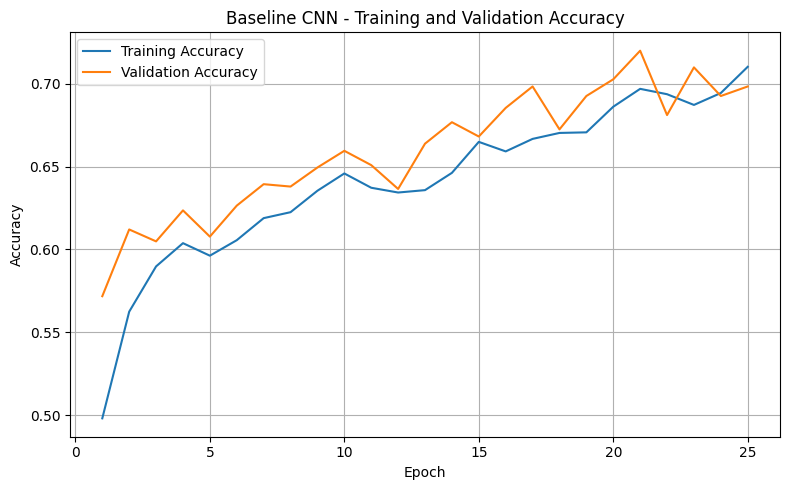


Baseline CNN Summary
----------------------------------------
Number of classes : 4
Training epochs   : 25
Total parameters  : 422,788
Trainable params  : 422,788
Best val loss     : 0.7324
Best val accuracy : 0.7198


In [ ]:
# ============================================================
# STEP 30 — BASELINE CNN
# ============================================================

import copy
import torch
import torch.nn as nn
from tqdm.auto import tqdm
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 30A. DEVICE
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ------------------------------------------------------------
# 30B. BASELINE CNN ARCHITECTURE
# ------------------------------------------------------------

class BaselineCNN(nn.Module):

    def __init__(self, num_classes):
        super(BaselineCNN, self).__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(
                in_channels=3,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(
                in_channels=32,
                out_channels=64,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Block 3
            nn.Conv2d(
                in_channels=64,
                out_channels=128,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Block 4
            nn.Conv2d(
                in_channels=128,
                out_channels=256,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Convert feature maps to 1 × 1
            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(256, 128),
            nn.ReLU(inplace=True),

            nn.Dropout(0.5),

            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        x = self.features(x)
        x = self.classifier(x)

        return x


# ------------------------------------------------------------
# 30C. CREATE MODEL
# ------------------------------------------------------------

baseline_model = BaselineCNN(
    num_classes=len(class_names)
).to(device)

print("\nBaseline CNN:")
print(baseline_model)


# ------------------------------------------------------------
# 30D. COUNT PARAMETERS
# ------------------------------------------------------------

total_params = sum(
    p.numel()
    for p in baseline_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in baseline_model.parameters()
    if p.requires_grad
)

print("\nModel parameters:")
print(f"Total parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")


# ------------------------------------------------------------
# 30E. LOSS FUNCTION
# ------------------------------------------------------------

criterion = nn.CrossEntropyLoss()


# ------------------------------------------------------------
# 30F. OPTIMIZER
# ------------------------------------------------------------

optimizer = torch.optim.Adam(
    baseline_model.parameters(),
    lr=CONFIG["learning_rate"],
    weight_decay=CONFIG["weight_decay"]
)


# ------------------------------------------------------------
# 30G. LEARNING-RATE SCHEDULER
# ------------------------------------------------------------

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)


# ------------------------------------------------------------
# 30H. TRAINING FUNCTION
# ------------------------------------------------------------

def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(
        loader,
        desc="Training",
        leave=False
    ):

        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(
            outputs,
            labels
        )

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Statistics
        running_loss += (
            loss.item() * images.size(0)
        )

        _, predicted = torch.max(
            outputs,
            1
        )

        total += labels.size(0)

        correct += (
            predicted == labels
        ).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


# ------------------------------------------------------------
# 30I. VALIDATION FUNCTION
# ------------------------------------------------------------

def evaluate_model(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for images, labels in tqdm(
            loader,
            desc="Validation",
            leave=False
        ):

            images = images.to(device)
            labels = labels.to(device)

            # Forward pass
            outputs = model(images)

            # Loss
            loss = criterion(
                outputs,
                labels
            )

            running_loss += (
                loss.item() * images.size(0)
            )

            # Predictions
            _, predicted = torch.max(
                outputs,
                1
            )

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_predictions.extend(
                predicted.cpu().numpy()
            )

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return (
        epoch_loss,
        epoch_accuracy,
        all_labels,
        all_predictions
    )


# ------------------------------------------------------------
# 30J. TRAIN BASELINE CNN
# ------------------------------------------------------------

NUM_EPOCHS = CONFIG["epochs"]

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_val_loss = float("inf")
best_model_state = None

print("\n" + "=" * 60)
print("STARTING BASELINE CNN TRAINING")
print("=" * 60)

for epoch in range(NUM_EPOCHS):

    print(
        f"\nEpoch {epoch + 1}/{NUM_EPOCHS}"
    )

    # -------------------------
    # Training
    # -------------------------

    train_loss, train_accuracy = train_one_epoch(
        baseline_model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    # -------------------------
    # Validation
    # -------------------------

    val_loss, val_accuracy, _, _ = evaluate_model(
        baseline_model,
        val_loader,
        criterion,
        device
    )

    # Update learning rate
    scheduler.step(val_loss)

    # Save history
    history["train_loss"].append(
        train_loss
    )

    history["train_accuracy"].append(
        train_accuracy
    )

    history["val_loss"].append(
        val_loss
    )

    history["val_accuracy"].append(
        val_accuracy
    )

    # Save best model
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_model_state = copy.deepcopy(
            baseline_model.state_dict()
        )

        print("✓ Best model updated")

    # Print results
    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.4f}"
    )

    print(
        f"Val Loss:   {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f}"
    )

    print(
        f"Learning Rate: "
        f"{optimizer.param_groups[0]['lr']:.6f}"
    )


# ------------------------------------------------------------
# 30K. RESTORE BEST MODEL
# ------------------------------------------------------------

if best_model_state is not None:

    baseline_model.load_state_dict(
        best_model_state
    )

print("\n" + "=" * 60)
print("BASELINE CNN TRAINING COMPLETED")
print("=" * 60)

print(
    f"Best Validation Loss: "
    f"{best_val_loss:.4f}"
)


# ------------------------------------------------------------
# 30L. PLOT LOSS CURVES
# ------------------------------------------------------------

epochs_range = range(
    1,
    len(history["train_loss"]) + 1
)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    epochs_range,
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Baseline CNN - Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 30M. PLOT ACCURACY CURVES
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    history["train_accuracy"],
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Baseline CNN - Training and Validation Accuracy")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 30N. FINAL TRAINING SUMMARY
# ------------------------------------------------------------

print("\nBaseline CNN Summary")
print("-" * 40)
print(f"Number of classes : {len(class_names)}")
print(f"Training epochs   : {NUM_EPOCHS}")
print(f"Total parameters  : {total_params:,}")
print(f"Trainable params  : {trainable_params:,}")
print(f"Best val loss     : {best_val_loss:.4f}")
print(
    f"Best val accuracy : "
    f"{max(history['val_accuracy']):.4f}"
)

In [ ]:
# ============================================================
# SAVE TRAINED BASELINE CNN
# ============================================================

import os
import torch

save_path = "/content/baseline_cnn_best.pth"

# Make sure the best validation model is loaded
if best_model_state is not None:
    baseline_model.load_state_dict(best_model_state)

# Save model weights
torch.save(baseline_model.state_dict(), save_path)

print("=" * 60)
print("BASELINE CNN SAVED")
print("=" * 60)
print("Path:", save_path)
print("Size: {:.2f} MB".format(os.path.getsize(save_path) / (1024 * 1024)))

BASELINE CNN SAVED
Path: /content/baseline_cnn_best.pth
Size: 1.63 MB


Testing:   0%|          | 0/28 [00:00<?, ?it/s]


BASELINE CNN — TEST SET RESULTS
Test Loss     : 1.2524
Test Accuracy : 0.5057
Test Accuracy : 50.57%

Overall Metrics
----------------------------------------
Weighted Precision : 0.5561
Weighted Recall    : 0.5057
Weighted F1-score  : 0.5080

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     echinus     0.5038    0.3028    0.3782       218
 holothurian     0.7062    0.5734    0.6329       218
     scallop     0.6541    0.4793    0.5532       217
    starfish     0.3598    0.6682    0.4677       217

    accuracy                         0.5057       870
   macro avg     0.5560    0.5059    0.5080       870
weighted avg     0.5561    0.5057    0.5080       870



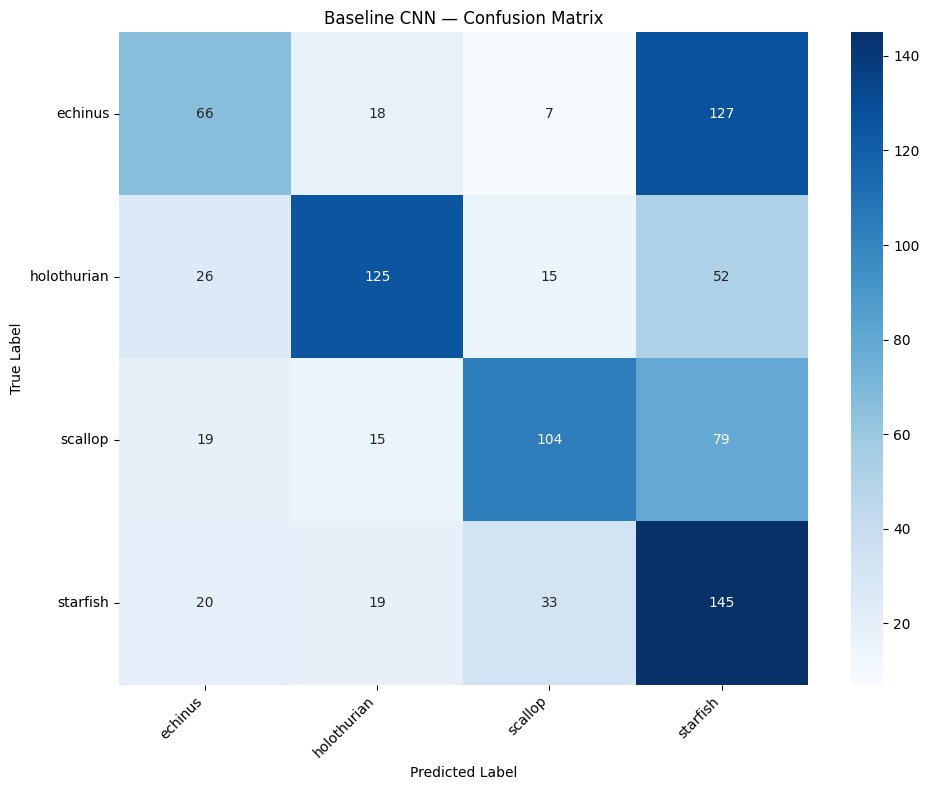

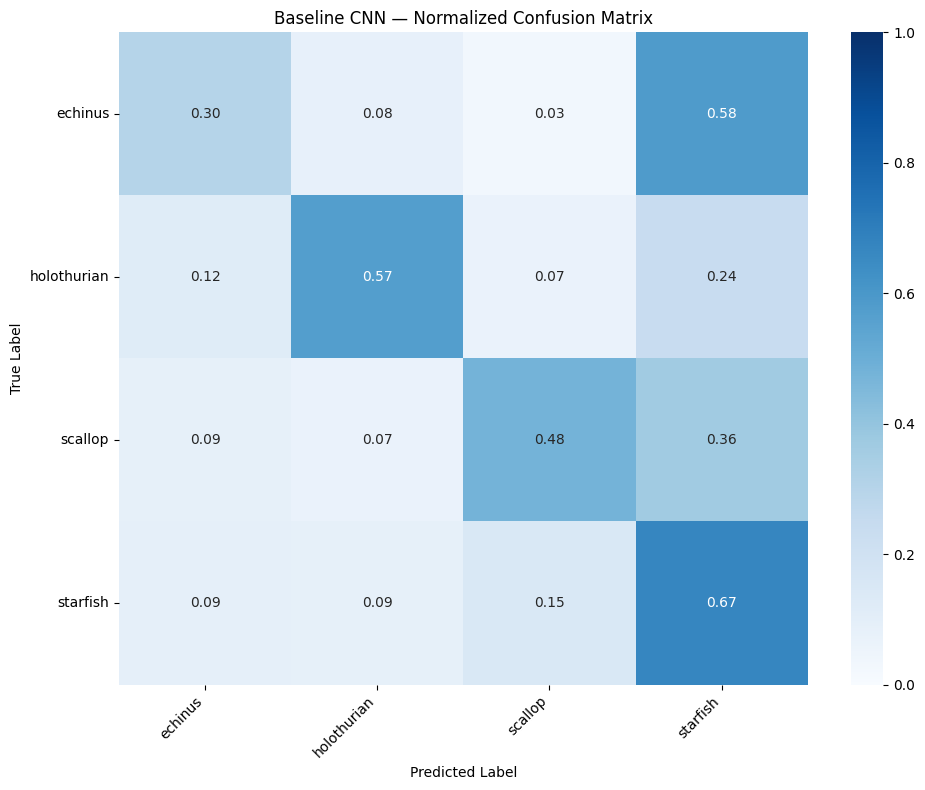


PER-CLASS PERFORMANCE


,Class,Precision,Recall,F1-Score
0,echinus,0.5038,0.3028,0.3782
1,holothurian,0.7062,0.5734,0.6329
2,scallop,0.6541,0.4793,0.5532
3,starfish,0.3598,0.6682,0.4677



BASELINE CNN SUMMARY


,Model,Test Loss,Accuracy,Precision,Recall,F1-Score,Parameters
0,Baseline CNN,1.2524,0.5057,0.5561,0.5057,0.5080,"422,788"



Results saved:
  baseline_cnn_results.csv
  baseline_cnn_per_class_results.csv

STEP 31 COMPLETED
Baseline CNN Test Accuracy : 50.57%
Baseline CNN Test F1-score : 0.5080


In [ ]:
# ============================================================
# STEP 31 — BASELINE CNN EVALUATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 31A. EVALUATE ON TEST SET
# ------------------------------------------------------------

baseline_model.eval()

test_loss = 0.0
test_correct = 0
test_total = 0

y_true = []
y_pred = []
y_prob = []

with torch.no_grad():

    for images, labels in tqdm(
        test_loader,
        desc="Testing"
    ):

        images = images.to(device)
        labels = labels.to(device)

        # Forward pass
        outputs = baseline_model(images)

        # Test loss
        loss = criterion(
            outputs,
            labels
        )

        test_loss += (
            loss.item() * images.size(0)
        )

        # Predicted class
        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        _, predicted = torch.max(
            outputs,
            1
        )

        # Statistics
        test_total += labels.size(0)

        test_correct += (
            predicted == labels
        ).sum().item()

        # Store labels and predictions
        y_true.extend(
            labels.cpu().numpy()
        )

        y_pred.extend(
            predicted.cpu().numpy()
        )

        y_prob.extend(
            probabilities.cpu().numpy()
        )


# ------------------------------------------------------------
# 31B. CALCULATE TEST LOSS AND ACCURACY
# ------------------------------------------------------------

test_loss = test_loss / test_total

test_accuracy = accuracy_score(
    y_true,
    y_pred
)

print("\n" + "=" * 60)
print("BASELINE CNN — TEST SET RESULTS")
print("=" * 60)

print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f}")
print(f"Test Accuracy : {test_accuracy * 100:.2f}%")


# ------------------------------------------------------------
# 31C. PRECISION, RECALL AND F1-SCORE
# ------------------------------------------------------------

test_precision = precision_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

test_recall = recall_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

test_f1 = f1_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

print("\nOverall Metrics")
print("-" * 40)

print(
    f"Weighted Precision : "
    f"{test_precision:.4f}"
)

print(
    f"Weighted Recall    : "
    f"{test_recall:.4f}"
)

print(
    f"Weighted F1-score  : "
    f"{test_f1:.4f}"
)


# ------------------------------------------------------------
# 31D. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


# ------------------------------------------------------------
# 31E. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(
    figsize=(10, 8)
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Baseline CNN — Confusion Matrix")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 31F. NORMALIZED CONFUSION MATRIX
# ------------------------------------------------------------

cm_normalized = confusion_matrix(
    y_true,
    y_pred,
    normalize="true"
)

plt.figure(
    figsize=(10, 8)
)

sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    vmin=0,
    vmax=1
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title(
    "Baseline CNN — Normalized Confusion Matrix"
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 31G. PER-CLASS METRICS
# ------------------------------------------------------------

class_precision = precision_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

class_recall = recall_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

class_f1 = f1_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

class_results = pd.DataFrame({
    "Class": class_names,
    "Precision": class_precision,
    "Recall": class_recall,
    "F1-Score": class_f1
})

print("\n" + "=" * 60)
print("PER-CLASS PERFORMANCE")
print("=" * 60)

display(
    class_results.style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}"
    })
)


# ------------------------------------------------------------
# 31H. SAVE BASELINE RESULTS
# ------------------------------------------------------------

baseline_results = pd.DataFrame([{
    "Model": "Baseline CNN",
    "Test Loss": test_loss,
    "Accuracy": test_accuracy,
    "Precision": test_precision,
    "Recall": test_recall,
    "F1-Score": test_f1,
    "Parameters": total_params
}])

print("\n" + "=" * 60)
print("BASELINE CNN SUMMARY")
print("=" * 60)

display(
    baseline_results.style.format({
        "Test Loss": "{:.4f}",
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "Parameters": "{:,.0f}"
    })
)


# ------------------------------------------------------------
# 31I. SAVE RESULTS TO CSV
# ------------------------------------------------------------

baseline_results.to_csv(
    "baseline_cnn_results.csv",
    index=False
)

class_results.to_csv(
    "baseline_cnn_per_class_results.csv",
    index=False
)

print("\nResults saved:")
print("  baseline_cnn_results.csv")
print("  baseline_cnn_per_class_results.csv")


# ------------------------------------------------------------
# 31J. FINAL OUTPUT
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("STEP 31 COMPLETED")
print("=" * 60)

print(
    f"Baseline CNN Test Accuracy : "
    f"{test_accuracy * 100:.2f}%"
)

print(
    f"Baseline CNN Test F1-score : "
    f"{test_f1:.4f}"
)

Device: cuda
GPU: Tesla T4

Loading pretrained ResNet50...

ResNet50:
Linear(in_features=2048, out_features=4, bias=True)

Model parameters:
Total parameters:     23,516,228
Trainable parameters: 23,516,228

STARTING RESNET50 TRAINING

Epoch 1/25


ResNet50 Training:   0%|          | 0/87 [00:00<?, ?it/s]

ResNet50 Validation:   0%|          | 0/22 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a0333478f40>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process


✓ Best ResNet50 model updated
Train Loss:     0.7225
Train Accuracy: 0.7572
Val Loss:       0.2721
Val Accuracy:   0.9181
Learning Rate:  0.000100

Epoch 2/25


...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a0333478f40>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child processException ignored in: 
<function _MultiProcessingDataLoaderIter.__del__ at 0x7a0333478f40>
Traceback (most recent call last):
Exception ignored in:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
<function _MultiProcessingDataLoaderIter.__del__ at 0x7a0333478f40>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/u

Train Loss:     0.0045
Train Accuracy: 0.9993
Val Loss:       0.1433
Val Accuracy:   0.9756
Learning Rate:  0.000006

Epoch 25/25


ResNet50 Training:   0%|          | 0/87 [00:00<?, ?it/s]

ResNet50 Validation:   0%|          | 0/22 [00:00<?, ?it/s]

Train Loss:     0.0048
Train Accuracy: 0.9993
Val Loss:       0.1434
Val Accuracy:   0.9784
Learning Rate:  0.000006

RESNET50 TRAINING COMPLETED
Best validation loss: 0.1347
Best validation accuracy: 0.9784


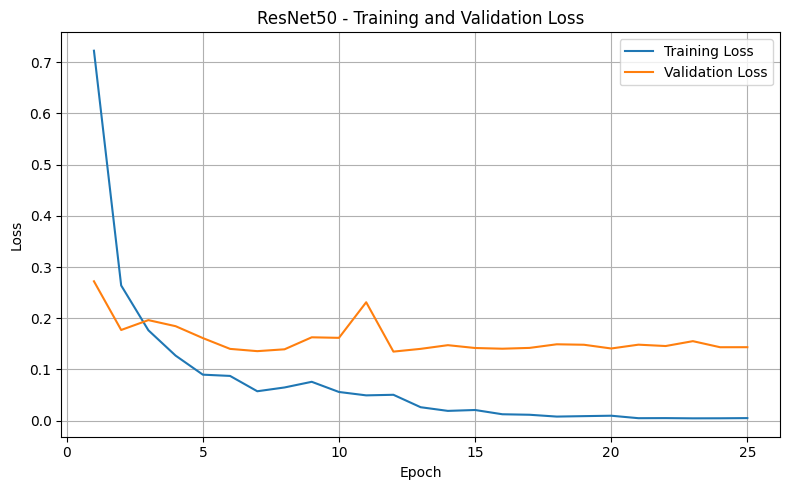

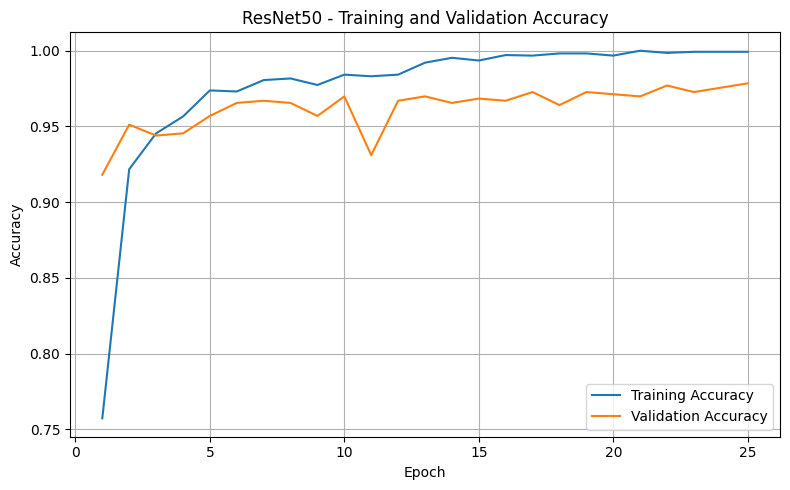


STEP 32 COMPLETED — RESNET50
Classes           : 4
Total parameters  : 23,516,228
Trainable params  : 23,516,228
Best Val Loss     : 0.1347
Best Val Accuracy : 0.9784

Saved model: resnet50_best.pth

NOTE: Test-set evaluation will be done after training, separately from validation.


In [ ]:
# ============================================================
# STEP 32 — RESNET50
# ============================================================

import copy
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from torchvision import models


# ------------------------------------------------------------
# 32A. DEVICE
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ------------------------------------------------------------
# 32B. LOAD PRETRAINED RESNET50
# ------------------------------------------------------------

print("\nLoading pretrained ResNet50...")

resnet50 = models.resnet50(
    weights=models.ResNet50_Weights.DEFAULT
)


# ------------------------------------------------------------
# 32C. REPLACE FINAL CLASSIFIER
# ------------------------------------------------------------

num_classes = len(class_names)

in_features = resnet50.fc.in_features

resnet50.fc = nn.Linear(
    in_features,
    num_classes
)

resnet50 = resnet50.to(device)


print("\nResNet50:")
print(resnet50.fc)


# ------------------------------------------------------------
# 32D. COUNT PARAMETERS
# ------------------------------------------------------------

resnet_total_params = sum(
    p.numel()
    for p in resnet50.parameters()
)

resnet_trainable_params = sum(
    p.numel()
    for p in resnet50.parameters()
    if p.requires_grad
)

print("\nModel parameters:")
print(
    f"Total parameters:     "
    f"{resnet_total_params:,}"
)

print(
    f"Trainable parameters: "
    f"{resnet_trainable_params:,}"
)


# ------------------------------------------------------------
# 32E. LOSS FUNCTION
# ------------------------------------------------------------

resnet_criterion = nn.CrossEntropyLoss()


# ------------------------------------------------------------
# 32F. OPTIMIZER
# ------------------------------------------------------------

resnet_optimizer = torch.optim.Adam(
    resnet50.parameters(),
    lr=CONFIG["learning_rate"],
    weight_decay=CONFIG["weight_decay"]
)


# ------------------------------------------------------------
# 32G. LEARNING-RATE SCHEDULER
# ------------------------------------------------------------

resnet_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    resnet_optimizer,
    mode="min",
    factor=0.5,
    patience=3
)


# ------------------------------------------------------------
# 32H. TRAINING FUNCTION
# ------------------------------------------------------------

def train_resnet50_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(
        loader,
        desc="ResNet50 Training",
        leave=False
    ):

        images = images.to(device)
        labels = labels.to(device)

        # Clear gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(
            outputs,
            labels
        )

        # Backpropagation
        loss.backward()

        # Update parameters
        optimizer.step()

        # Statistics
        running_loss += (
            loss.item() * images.size(0)
        )

        _, predicted = torch.max(
            outputs,
            1
        )

        total += labels.size(0)

        correct += (
            predicted == labels
        ).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


# ------------------------------------------------------------
# 32I. VALIDATION FUNCTION
# ------------------------------------------------------------

def validate_resnet50(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in tqdm(
            loader,
            desc="ResNet50 Validation",
            leave=False
        ):

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            running_loss += (
                loss.item() * images.size(0)
            )

            _, predicted = torch.max(
                outputs,
                1
            )

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


# ------------------------------------------------------------
# 32J. TRAIN RESNET50
# ------------------------------------------------------------

NUM_EPOCHS = CONFIG["epochs"]

resnet_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_resnet_val_loss = float("inf")
best_resnet_state = None

print("\n" + "=" * 60)
print("STARTING RESNET50 TRAINING")
print("=" * 60)

for epoch in range(NUM_EPOCHS):

    print(
        f"\nEpoch {epoch + 1}/{NUM_EPOCHS}"
    )

    # -------------------------
    # Training
    # -------------------------

    train_loss, train_accuracy = (
        train_resnet50_one_epoch(
            resnet50,
            train_loader,
            resnet_criterion,
            resnet_optimizer,
            device
        )
    )

    # -------------------------
    # Validation
    # -------------------------

    val_loss, val_accuracy = (
        validate_resnet50(
            resnet50,
            val_loader,
            resnet_criterion,
            device
        )
    )

    # Update scheduler
    resnet_scheduler.step(val_loss)

    # Store history
    resnet_history["train_loss"].append(
        train_loss
    )

    resnet_history["train_accuracy"].append(
        train_accuracy
    )

    resnet_history["val_loss"].append(
        val_loss
    )

    resnet_history["val_accuracy"].append(
        val_accuracy
    )

    # -------------------------
    # Save best model
    # -------------------------

    if val_loss < best_resnet_val_loss:

        best_resnet_val_loss = val_loss

        best_resnet_state = copy.deepcopy(
            resnet50.state_dict()
        )

        print("✓ Best ResNet50 model updated")

    # -------------------------
    # Print results
    # -------------------------

    print(
        f"Train Loss:     {train_loss:.4f}"
    )

    print(
        f"Train Accuracy: {train_accuracy:.4f}"
    )

    print(
        f"Val Loss:       {val_loss:.4f}"
    )

    print(
        f"Val Accuracy:   {val_accuracy:.4f}"
    )

    print(
        f"Learning Rate:  "
        f"{resnet_optimizer.param_groups[0]['lr']:.6f}"
    )


# ------------------------------------------------------------
# 32K. RESTORE BEST RESNET50
# ------------------------------------------------------------

if best_resnet_state is not None:

    resnet50.load_state_dict(
        best_resnet_state
    )

print("\n" + "=" * 60)
print("RESNET50 TRAINING COMPLETED")
print("=" * 60)

print(
    f"Best validation loss: "
    f"{best_resnet_val_loss:.4f}"
)

print(
    f"Best validation accuracy: "
    f"{max(resnet_history['val_accuracy']):.4f}"
)


# ------------------------------------------------------------
# 32L. TRAINING / VALIDATION LOSS CURVE
# ------------------------------------------------------------

epochs_range = range(
    1,
    len(resnet_history["train_loss"]) + 1
)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    resnet_history["train_loss"],
    label="Training Loss"
)

plt.plot(
    epochs_range,
    resnet_history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "ResNet50 - Training and Validation Loss"
)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 32M. TRAINING / VALIDATION ACCURACY CURVE
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    resnet_history["train_accuracy"],
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    resnet_history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "ResNet50 - Training and Validation Accuracy"
)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 32N. SAVE BEST MODEL
# ------------------------------------------------------------

torch.save(
    {
        "model_state_dict": resnet50.state_dict(),
        "class_names": class_names,
        "num_classes": num_classes,
        "best_val_loss": best_resnet_val_loss
    },
    "resnet50_best.pth"
)


# ------------------------------------------------------------
# 32O. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("STEP 32 COMPLETED — RESNET50")
print("=" * 60)

print(
    f"Classes           : {num_classes}"
)

print(
    f"Total parameters  : "
    f"{resnet_total_params:,}"
)

print(
    f"Trainable params  : "
    f"{resnet_trainable_params:,}"
)

print(
    f"Best Val Loss     : "
    f"{best_resnet_val_loss:.4f}"
)

print(
    f"Best Val Accuracy : "
    f"{max(resnet_history['val_accuracy']):.4f}"
)

print(
    "\nSaved model: resnet50_best.pth"
)

print(
    "\nNOTE: Test-set evaluation will be done "
    "after training, separately from validation."
)

Device: cuda
GPU: Tesla T4

Loading pretrained EfficientNetV2-S...

EfficientNetV2-S classifier:
Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=4, bias=True)
)

Model parameters:
Total parameters:     20,182,612
Trainable parameters: 20,182,612

STARTING EFFICIENTNETV2-S TRAINING

Epoch 1/25


EfficientNetV2-S Training:   0%|          | 0/87 [00:00<?, ?it/s]

EfficientNetV2-S Validation:   0%|          | 0/22 [00:00<?, ?it/s]

✓ Best EfficientNetV2-S model updated
Train Loss:     0.6381
Train Accuracy: 0.7784
Val Loss:       0.2157
Val Accuracy:   0.9382
Learning Rate:  0.000100

Epoch 2/25


EfficientNetV2-S Training:   0%|          | 0/87 [00:00<?, ?it/s]

...

Train Loss:     0.0031
Train Accuracy: 0.9993
Val Loss:       0.1533
Val Accuracy:   0.9770
Learning Rate:  0.000013

Epoch 25/25


EfficientNetV2-S Training:   0%|          | 0/87 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a0333478f40>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a0333478f40>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

EfficientNetV2-S Validation:   0%|          | 0/22 [00:00<?, ?it/s]

Train Loss:     0.0041
Train Accuracy: 0.9989
Val Loss:       0.1500
Val Accuracy:   0.9756
Learning Rate:  0.000006

EFFICIENTNETV2-S TRAINING COMPLETED
Best validation loss: 0.1249
Best validation accuracy: 0.9770


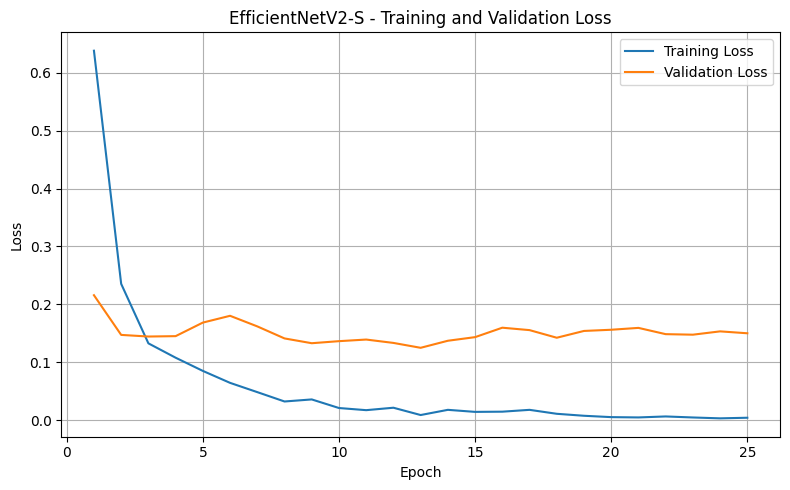

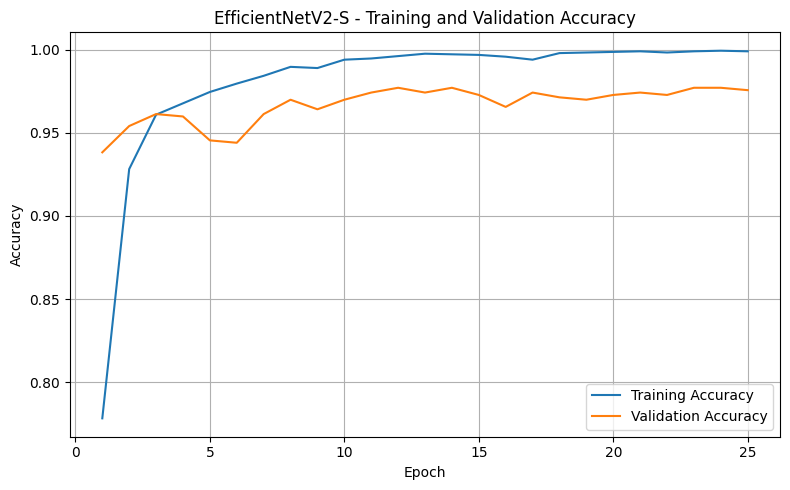


STEP 33 COMPLETED — EFFICIENTNETV2-S
Classes           : 4
Total parameters  : 20,182,612
Trainable params  : 20,182,612
Best Val Loss     : 0.1249
Best Val Accuracy : 0.9770

Saved model: efficientnetv2_s_best.pth

NOTE: Test-set evaluation will be performed separately after the model experiments.


In [ ]:
# ============================================================
# STEP 33 — EFFICIENTNETV2-S
# ============================================================

import copy
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from torchvision import models


# ------------------------------------------------------------
# 33A. DEVICE
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ------------------------------------------------------------
# 33B. LOAD PRETRAINED EFFICIENTNETV2-S
# ------------------------------------------------------------

print("\nLoading pretrained EfficientNetV2-S...")

efficientnet = models.efficientnet_v2_s(
    weights=models.EfficientNet_V2_S_Weights.DEFAULT
)


# ------------------------------------------------------------
# 33C. REPLACE FINAL CLASSIFIER
# ------------------------------------------------------------

num_classes = len(class_names)

in_features = efficientnet.classifier[-1].in_features

efficientnet.classifier[-1] = nn.Linear(
    in_features,
    num_classes
)

efficientnet = efficientnet.to(device)


print("\nEfficientNetV2-S classifier:")
print(efficientnet.classifier)


# ------------------------------------------------------------
# 33D. COUNT PARAMETERS
# ------------------------------------------------------------

efficientnet_total_params = sum(
    p.numel()
    for p in efficientnet.parameters()
)

efficientnet_trainable_params = sum(
    p.numel()
    for p in efficientnet.parameters()
    if p.requires_grad
)

print("\nModel parameters:")
print(
    f"Total parameters:     "
    f"{efficientnet_total_params:,}"
)

print(
    f"Trainable parameters: "
    f"{efficientnet_trainable_params:,}"
)


# ------------------------------------------------------------
# 33E. LOSS FUNCTION
# ------------------------------------------------------------

efficientnet_criterion = nn.CrossEntropyLoss()


# ------------------------------------------------------------
# 33F. OPTIMIZER
# ------------------------------------------------------------

efficientnet_optimizer = torch.optim.Adam(
    efficientnet.parameters(),
    lr=CONFIG["learning_rate"],
    weight_decay=CONFIG["weight_decay"]
)


# ------------------------------------------------------------
# 33G. LEARNING-RATE SCHEDULER
# ------------------------------------------------------------

efficientnet_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    efficientnet_optimizer,
    mode="min",
    factor=0.5,
    patience=3
)


# ------------------------------------------------------------
# 33H. TRAINING FUNCTION
# ------------------------------------------------------------

def train_efficientnet_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(
        loader,
        desc="EfficientNetV2-S Training",
        leave=False
    ):

        images = images.to(device)
        labels = labels.to(device)

        # Clear gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(
            outputs,
            labels
        )

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Statistics
        running_loss += (
            loss.item() * images.size(0)
        )

        _, predicted = torch.max(
            outputs,
            1
        )

        total += labels.size(0)

        correct += (
            predicted == labels
        ).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


# ------------------------------------------------------------
# 33I. VALIDATION FUNCTION
# ------------------------------------------------------------

def validate_efficientnet(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in tqdm(
            loader,
            desc="EfficientNetV2-S Validation",
            leave=False
        ):

            images = images.to(device)
            labels = labels.to(device)

            # Forward pass
            outputs = model(images)

            # Loss
            loss = criterion(
                outputs,
                labels
            )

            running_loss += (
                loss.item() * images.size(0)
            )

            # Predictions
            _, predicted = torch.max(
                outputs,
                1
            )

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


# ------------------------------------------------------------
# 33J. TRAIN EFFICIENTNETV2-S
# ------------------------------------------------------------

NUM_EPOCHS = CONFIG["epochs"]

efficientnet_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_efficientnet_val_loss = float("inf")
best_efficientnet_state = None

print("\n" + "=" * 60)
print("STARTING EFFICIENTNETV2-S TRAINING")
print("=" * 60)

for epoch in range(NUM_EPOCHS):

    print(
        f"\nEpoch {epoch + 1}/{NUM_EPOCHS}"
    )

    # -------------------------
    # Training
    # -------------------------

    train_loss, train_accuracy = (
        train_efficientnet_one_epoch(
            efficientnet,
            train_loader,
            efficientnet_criterion,
            efficientnet_optimizer,
            device
        )
    )

    # -------------------------
    # Validation
    # -------------------------

    val_loss, val_accuracy = (
        validate_efficientnet(
            efficientnet,
            val_loader,
            efficientnet_criterion,
            device
        )
    )

    # Update scheduler
    efficientnet_scheduler.step(
        val_loss
    )

    # Store history
    efficientnet_history["train_loss"].append(
        train_loss
    )

    efficientnet_history["train_accuracy"].append(
        train_accuracy
    )

    efficientnet_history["val_loss"].append(
        val_loss
    )

    efficientnet_history["val_accuracy"].append(
        val_accuracy
    )

    # -------------------------
    # Save best model
    # -------------------------

    if val_loss < best_efficientnet_val_loss:

        best_efficientnet_val_loss = val_loss

        best_efficientnet_state = copy.deepcopy(
            efficientnet.state_dict()
        )

        print("✓ Best EfficientNetV2-S model updated")

    # -------------------------
    # Print results
    # -------------------------

    print(
        f"Train Loss:     {train_loss:.4f}"
    )

    print(
        f"Train Accuracy: {train_accuracy:.4f}"
    )

    print(
        f"Val Loss:       {val_loss:.4f}"
    )

    print(
        f"Val Accuracy:   {val_accuracy:.4f}"
    )

    print(
        f"Learning Rate:  "
        f"{efficientnet_optimizer.param_groups[0]['lr']:.6f}"
    )


# ------------------------------------------------------------
# 33K. RESTORE BEST MODEL
# ------------------------------------------------------------

if best_efficientnet_state is not None:

    efficientnet.load_state_dict(
        best_efficientnet_state
    )

print("\n" + "=" * 60)
print("EFFICIENTNETV2-S TRAINING COMPLETED")
print("=" * 60)

print(
    f"Best validation loss: "
    f"{best_efficientnet_val_loss:.4f}"
)

print(
    f"Best validation accuracy: "
    f"{max(efficientnet_history['val_accuracy']):.4f}"
)


# ------------------------------------------------------------
# 33L. LOSS CURVE
# ------------------------------------------------------------

epochs_range = range(
    1,
    len(efficientnet_history["train_loss"]) + 1
)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    efficientnet_history["train_loss"],
    label="Training Loss"
)

plt.plot(
    epochs_range,
    efficientnet_history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "EfficientNetV2-S - Training and Validation Loss"
)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 33M. ACCURACY CURVE
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    efficientnet_history["train_accuracy"],
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    efficientnet_history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "EfficientNetV2-S - Training and Validation Accuracy"
)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 33N. SAVE BEST MODEL
# ------------------------------------------------------------

torch.save(
    {
        "model_state_dict": efficientnet.state_dict(),
        "class_names": class_names,
        "num_classes": num_classes,
        "best_val_loss": best_efficientnet_val_loss
    },
    "efficientnetv2_s_best.pth"
)


# ------------------------------------------------------------
# 33O. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("STEP 33 COMPLETED — EFFICIENTNETV2-S")
print("=" * 60)

print(
    f"Classes           : {num_classes}"
)

print(
    f"Total parameters  : "
    f"{efficientnet_total_params:,}"
)

print(
    f"Trainable params  : "
    f"{efficientnet_trainable_params:,}"
)

print(
    f"Best Val Loss     : "
    f"{best_efficientnet_val_loss:.4f}"
)

print(
    f"Best Val Accuracy : "
    f"{max(efficientnet_history['val_accuracy']):.4f}"
)

print(
    "\nSaved model: efficientnetv2_s_best.pth"
)

print(
    "\nNOTE: Test-set evaluation will be performed "
    "separately after the model experiments."
)

Device: cuda
GPU: Tesla T4

Loading pretrained ConvNeXt-Tiny...

ConvNeXt-Tiny classifier:
Sequential(
  (0): LayerNorm2d((768,), eps=1e-06, elementwise_affine=True)
  (1): Flatten(start_dim=1, end_dim=-1)
  (2): Linear(in_features=768, out_features=4, bias=True)
)

Model parameters:
Total parameters:     27,823,204
Trainable parameters: 27,823,204

STARTING CONVNEXT-TINY TRAINING

Epoch 1/25


ConvNeXt-Tiny Training:   0%|          | 0/87 [00:00<?, ?it/s]

ConvNeXt-Tiny Validation:   0%|          | 0/22 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a0333478f40>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a0333478f40>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

✓ Best ConvNeXt-Tiny model updated
Train Loss:     0.4287
Train Accuracy: 0.8488
Val Loss:       0.1615
Val Accuracy:   0.9497
Learning Rate:  0.000100

Epoch 2/25


...

Train Loss:     0.0025
Train Accuracy: 0.9989
Val Loss:       0.1811
Val Accuracy:   0.9612
Learning Rate:  0.000006

Epoch 25/25


ConvNeXt-Tiny Training:   0%|          | 0/87 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a0333478f40>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a0333478f40>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

ConvNeXt-Tiny Validation:   0%|          | 0/22 [00:00<?, ?it/s]

Train Loss:     0.0029
Train Accuracy: 0.9989
Val Loss:       0.1700
Val Accuracy:   0.9641
Learning Rate:  0.000006

CONVNEXT-TINY TRAINING COMPLETED
Best validation loss: 0.1271
Best validation accuracy: 0.9741


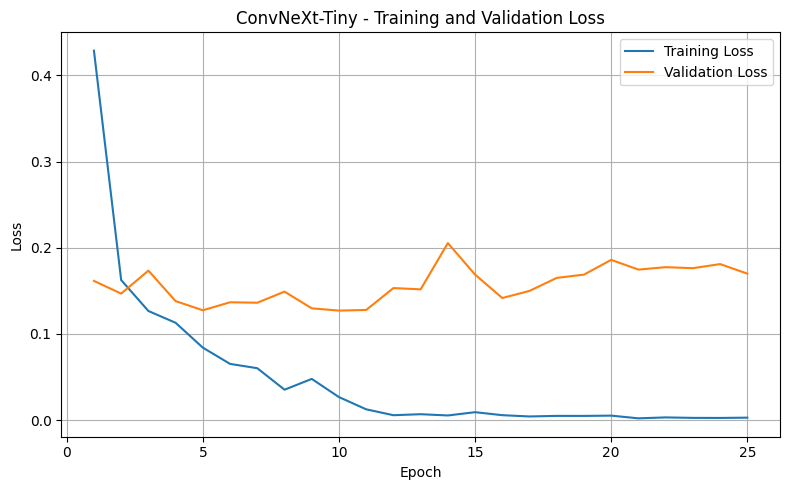

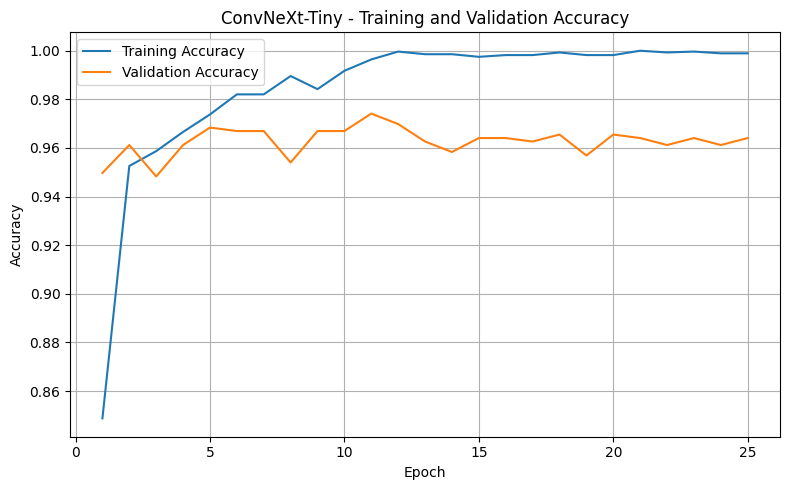


STEP 34 COMPLETED — CONVNEXT-TINY
Classes           : 4
Total parameters  : 27,823,204
Trainable params  : 27,823,204
Best Val Loss     : 0.1271
Best Val Accuracy : 0.9741

Saved model: convnext_tiny_best.pth

NOTE: Test-set evaluation remains separate.


In [ ]:
# ============================================================
# STEP 34 — CONVNEXT-TINY
# ============================================================

import copy
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from torchvision import models


# ------------------------------------------------------------
# 34A. DEVICE
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ------------------------------------------------------------
# 34B. LOAD PRETRAINED CONVNEXT-TINY
# ------------------------------------------------------------

print("\nLoading pretrained ConvNeXt-Tiny...")

convnext = models.convnext_tiny(
    weights=models.ConvNeXt_Tiny_Weights.DEFAULT
)


# ------------------------------------------------------------
# 34C. REPLACE FINAL CLASSIFIER
# ------------------------------------------------------------

num_classes = len(class_names)

in_features = convnext.classifier[-1].in_features

convnext.classifier[-1] = nn.Linear(
    in_features,
    num_classes
)

convnext = convnext.to(device)


print("\nConvNeXt-Tiny classifier:")
print(convnext.classifier)


# ------------------------------------------------------------
# 34D. COUNT PARAMETERS
# ------------------------------------------------------------

convnext_total_params = sum(
    p.numel()
    for p in convnext.parameters()
)

convnext_trainable_params = sum(
    p.numel()
    for p in convnext.parameters()
    if p.requires_grad
)

print("\nModel parameters:")
print(
    f"Total parameters:     "
    f"{convnext_total_params:,}"
)

print(
    f"Trainable parameters: "
    f"{convnext_trainable_params:,}"
)


# ------------------------------------------------------------
# 34E. LOSS FUNCTION
# ------------------------------------------------------------

convnext_criterion = nn.CrossEntropyLoss()


# ------------------------------------------------------------
# 34F. OPTIMIZER
# ------------------------------------------------------------

convnext_optimizer = torch.optim.Adam(
    convnext.parameters(),
    lr=CONFIG["learning_rate"],
    weight_decay=CONFIG["weight_decay"]
)


# ------------------------------------------------------------
# 34G. LEARNING-RATE SCHEDULER
# ------------------------------------------------------------

convnext_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    convnext_optimizer,
    mode="min",
    factor=0.5,
    patience=3
)


# ------------------------------------------------------------
# 34H. TRAINING FUNCTION
# ------------------------------------------------------------

def train_convnext_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(
        loader,
        desc="ConvNeXt-Tiny Training",
        leave=False
    ):

        images = images.to(device)
        labels = labels.to(device)

        # Clear gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Loss
        loss = criterion(
            outputs,
            labels
        )

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Statistics
        running_loss += (
            loss.item() * images.size(0)
        )

        _, predicted = torch.max(
            outputs,
            1
        )

        total += labels.size(0)

        correct += (
            predicted == labels
        ).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


# ------------------------------------------------------------
# 34I. VALIDATION FUNCTION
# ------------------------------------------------------------

def validate_convnext(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in tqdm(
            loader,
            desc="ConvNeXt-Tiny Validation",
            leave=False
        ):

            images = images.to(device)
            labels = labels.to(device)

            # Forward pass
            outputs = model(images)

            # Loss
            loss = criterion(
                outputs,
                labels
            )

            running_loss += (
                loss.item() * images.size(0)
            )

            # Predictions
            _, predicted = torch.max(
                outputs,
                1
            )

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


# ------------------------------------------------------------
# 34J. TRAIN CONVNEXT-TINY
# ------------------------------------------------------------

NUM_EPOCHS = CONFIG["epochs"]

convnext_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_convnext_val_loss = float("inf")
best_convnext_state = None

print("\n" + "=" * 60)
print("STARTING CONVNEXT-TINY TRAINING")
print("=" * 60)

for epoch in range(NUM_EPOCHS):

    print(
        f"\nEpoch {epoch + 1}/{NUM_EPOCHS}"
    )

    # -------------------------
    # Training
    # -------------------------

    train_loss, train_accuracy = (
        train_convnext_one_epoch(
            convnext,
            train_loader,
            convnext_criterion,
            convnext_optimizer,
            device
        )
    )

    # -------------------------
    # Validation
    # -------------------------

    val_loss, val_accuracy = (
        validate_convnext(
            convnext,
            val_loader,
            convnext_criterion,
            device
        )
    )

    # Update scheduler
    convnext_scheduler.step(
        val_loss
    )

    # Store history
    convnext_history["train_loss"].append(
        train_loss
    )

    convnext_history["train_accuracy"].append(
        train_accuracy
    )

    convnext_history["val_loss"].append(
        val_loss
    )

    convnext_history["val_accuracy"].append(
        val_accuracy
    )

    # -------------------------
    # Save best model
    # -------------------------

    if val_loss < best_convnext_val_loss:

        best_convnext_val_loss = val_loss

        best_convnext_state = copy.deepcopy(
            convnext.state_dict()
        )

        print("✓ Best ConvNeXt-Tiny model updated")

    # -------------------------
    # Print results
    # -------------------------

    print(
        f"Train Loss:     {train_loss:.4f}"
    )

    print(
        f"Train Accuracy: {train_accuracy:.4f}"
    )

    print(
        f"Val Loss:       {val_loss:.4f}"
    )

    print(
        f"Val Accuracy:   {val_accuracy:.4f}"
    )

    print(
        f"Learning Rate:  "
        f"{convnext_optimizer.param_groups[0]['lr']:.6f}"
    )


# ------------------------------------------------------------
# 34K. RESTORE BEST MODEL
# ------------------------------------------------------------

if best_convnext_state is not None:

    convnext.load_state_dict(
        best_convnext_state
    )

print("\n" + "=" * 60)
print("CONVNEXT-TINY TRAINING COMPLETED")
print("=" * 60)

print(
    f"Best validation loss: "
    f"{best_convnext_val_loss:.4f}"
)

print(
    f"Best validation accuracy: "
    f"{max(convnext_history['val_accuracy']):.4f}"
)


# ------------------------------------------------------------
# 34L. LOSS CURVE
# ------------------------------------------------------------

epochs_range = range(
    1,
    len(convnext_history["train_loss"]) + 1
)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    convnext_history["train_loss"],
    label="Training Loss"
)

plt.plot(
    epochs_range,
    convnext_history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "ConvNeXt-Tiny - Training and Validation Loss"
)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 34M. ACCURACY CURVE
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    convnext_history["train_accuracy"],
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    convnext_history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "ConvNeXt-Tiny - Training and Validation Accuracy"
)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 34N. SAVE BEST MODEL
# ------------------------------------------------------------

torch.save(
    {
        "model_state_dict": convnext.state_dict(),
        "class_names": class_names,
        "num_classes": num_classes,
        "best_val_loss": best_convnext_val_loss
    },
    "convnext_tiny_best.pth"
)


# ------------------------------------------------------------
# 34O. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("STEP 34 COMPLETED — CONVNEXT-TINY")
print("=" * 60)

print(
    f"Classes           : {num_classes}"
)

print(
    f"Total parameters  : "
    f"{convnext_total_params:,}"
)

print(
    f"Trainable params  : "
    f"{convnext_trainable_params:,}"
)

print(
    f"Best Val Loss     : "
    f"{best_convnext_val_loss:.4f}"
)

print(
    f"Best Val Accuracy : "
    f"{max(convnext_history['val_accuracy']):.4f}"
)

print(
    "\nSaved model: convnext_tiny_best.pth"
)

print(
    "\nNOTE: Test-set evaluation remains separate."
)

In [ ]:
import os

print("=" * 70)
print("ALL FILES IN /content")
print("=" * 70)

for root, dirs, files in os.walk("/content"):
    for file in files:
        path = os.path.join(root, file)
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"{path}  —  {size_mb:.2f} MB")

ALL FILES IN /content
/content/baseline_cnn_best.pth  —  1.63 MB
/content/best_model_confusion_matrix.png  —  0.13 MB
/content/resnet50_best.pth  —  90.01 MB
/content/baseline_cnn_results.csv  —  0.00 MB
/content/baseline_cnn_per_class_results.csv  —  0.00 MB
/content/efficientnetv2_s_wb_clahe_best.pth  —  77.87 MB
/content/model_metrics_comparison.png  —  0.12 MB
/content/uwi2020_metadata.csv  —  0.54 MB
/content/convnext_tiny_best.pth  —  106.20 MB
/content/step37_robustness_results.csv  —  0.00 MB
/content/train_split.csv  —  0.45 MB
/content/efficientnetv2_s_best.pth  —  77.86 MB
/content/val_split.csv  —  0.11 MB
/content/archive.zip  —  29.48 MB
/content/test_split.csv  —  0.14 MB
/content/convnext_tiny_wb_clahe_best.pth  —  106.20 MB
/content/model_accuracy_comparison.png  —  0.17 MB
/content/four_model_comparison.csv  —  0.00 MB
/content/resnet50_wb_clahe_best.pth  —  90.02 MB
/content/.config/default_configs.db  —  0.01 MB
/content/.config/hidden_gcloud_config_universe_descrip

In [ ]:
import os
import zipfile

from google.colab import files

output_dir = "/content"

files_to_save = [
    # Trained models
    "resnet50_wb_clahe_best.pth",
    "efficientnetv2_s_wb_clahe_best.pth",
    "convnext_tiny_wb_clahe_best.pth",

    # Comparison results
    "four_model_comparison.csv",
    "model_accuracy_comparison.png",
    "model_metrics_comparison.png",
    "best_model_confusion_matrix.png",

    # Robustness results
    "step37_robustness_results.csv",
]

zip_path = "/content/thesis_results.zip"

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for filename in files_to_save:

        filepath = os.path.join(
            output_dir,
            filename
        )

        if os.path.exists(filepath):

            zipf.write(
                filepath,
                arcname=filename
            )

            print("Added:", filename)

        else:
            print("Not found:", filename)


print("\nZIP created:")
print(zip_path)

files.download(zip_path)

Added: resnet50_wb_clahe_best.pth
Added: efficientnetv2_s_wb_clahe_best.pth
Added: convnext_tiny_wb_clahe_best.pth
Added: four_model_comparison.csv
Added: model_accuracy_comparison.png
Added: model_metrics_comparison.png
Added: best_model_confusion_matrix.png
Added: step37_robustness_results.csv

ZIP created:
/content/thesis_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import shutil
from google.colab import files

gradcam_zip = "/content/step38_gradcam.zip"

shutil.make_archive(
    "/content/step38_gradcam",
    "zip",
    "/content/step38_gradcam"
)

files.download(gradcam_zip)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

MODEL COMPARISON — 4 MODELS

Device: cuda

Checking trained models...

Models found:
  ✓ Baseline CNN
  ✓ ResNet50
  ✓ EfficientNetV2-S
  ✓ ConvNeXt-Tiny


EVALUATING MODELS ON TEST SET

Evaluating Baseline CNN...
  Accuracy : 94.25%
  Precision: 94.40%
  Recall   : 94.25%
  F1-Score : 94.25%
  Loss     : 0.1844

Evaluating ResNet50...
  Accuracy : 91.15%
  Precision: 91.15%
  Recall   : 91.15%
  F1-Score : 91.09%
  Loss     : 0.2810

Evaluating EfficientNetV2-S...
  Accuracy : 93.56%
  Precision: 93.59%
  Recall   : 93.56%
  F1-Score : 93.57%
  Loss     : 0.2462

Evaluating ConvNeXt-Tiny...
  Accuracy : 94.94%
  Precision: 95.04%
  Recall   : 94.94%
  F1-Score : 94.96%
  Loss     : 0.2101


FINAL MODEL COMPARISON


,Test Accuracy (%),Precision (%),Recall (%),F1-Score (%),Test Loss
ConvNeXt-Tiny,94.94,95.04,94.94,94.96,0.2101
Baseline CNN,94.25,94.40,94.25,94.25,0.1844
EfficientNetV2-S,93.56,93.59,93.56,93.57,0.2462
ResNet50,91.15,91.15,91.15,91.09,0.2810



🏆 Best Model: ConvNeXt-Tiny
🏆 Test Accuracy: 94.94%


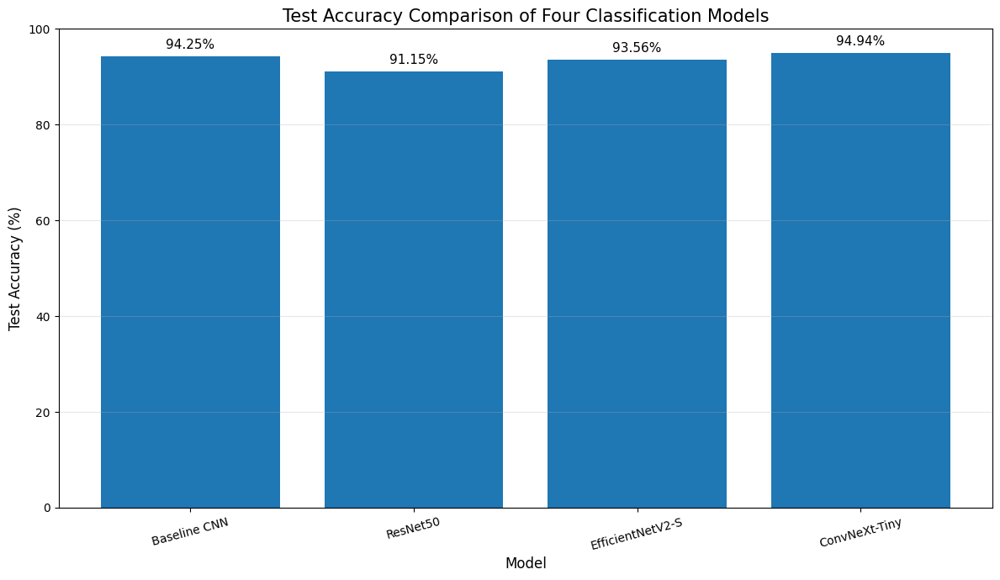

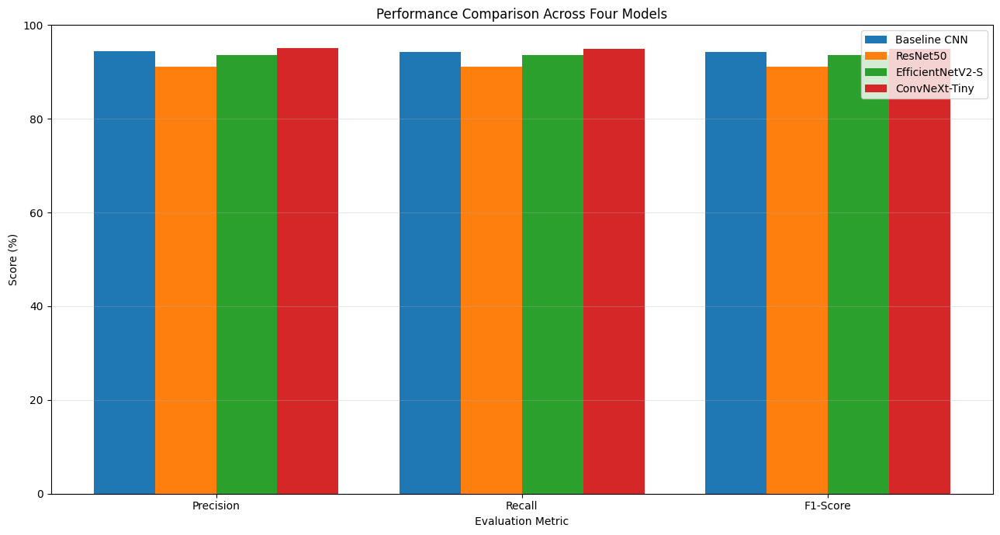


Getting class names...
Number of classes: 4


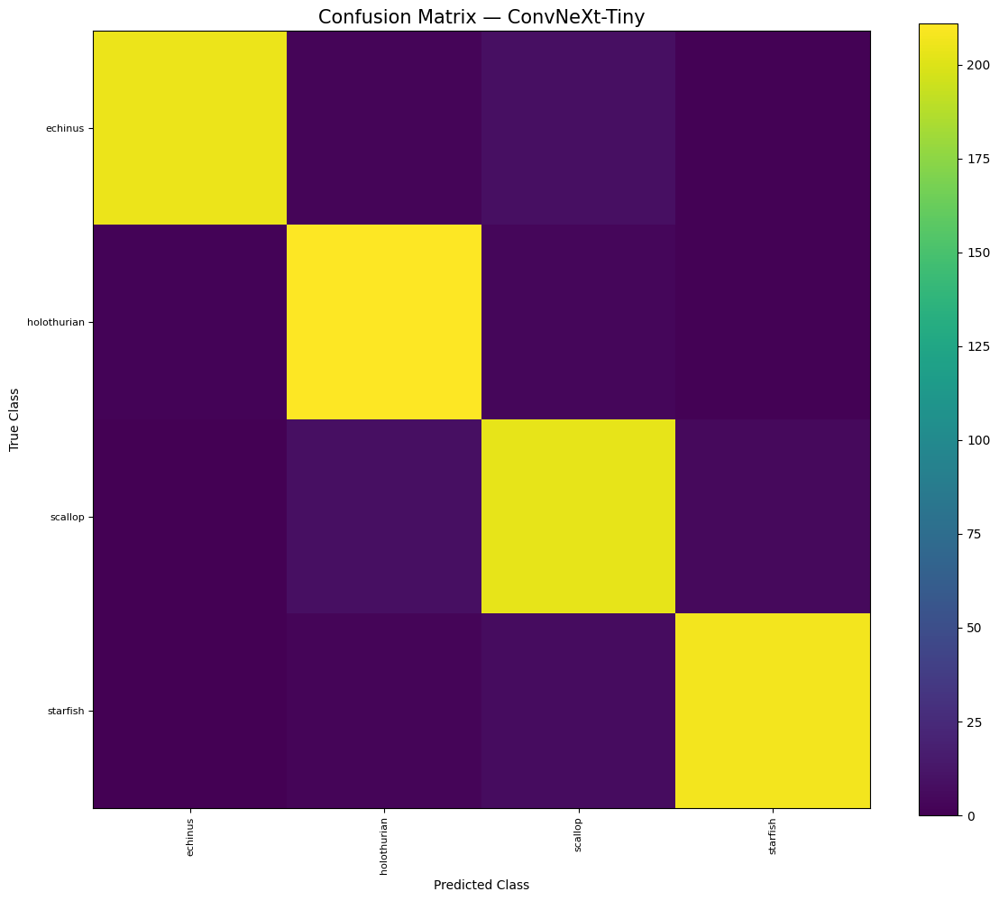



FILES SAVED
Comparison table:
/content/four_model_comparison.csv

Accuracy chart:
/content/model_accuracy_comparison.png

Metrics chart:
/content/model_metrics_comparison.png

Confusion matrix:
/content/best_model_confusion_matrix.png

MODEL COMPARISON COMPLETED


In [ ]:
# ============================================================
# MODEL COMPARISON — 4 MODELS
# Baseline CNN vs ResNet50 vs EfficientNetV2-S vs ConvNeXt-Tiny
# FIXED FOR UnderwaterDataset
# ============================================================

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("=" * 75)
print("MODEL COMPARISON — 4 MODELS")
print("=" * 75)

# ------------------------------------------------------------
# 1. DEVICE
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"\nDevice: {device}")


# ------------------------------------------------------------
# 2. MAKE SURE MODELS EXIST
# ------------------------------------------------------------

print("\nChecking trained models...")

# Baseline CNN
try:
    baseline_cnn
except NameError:
    try:
        # Your Step 30 uses "baseline_model"
        baseline_cnn = baseline_model
        print("Using 'baseline_model' as Baseline CNN.")
    except NameError:
        try:
            baseline_cnn = model
            print("Using 'model' as Baseline CNN.")
        except NameError:
            raise NameError(
                "Baseline CNN model was not found. "
                "Please make sure your trained Baseline CNN is in memory."
            )

# ResNet50
try:
    resnet50
except NameError:
    raise NameError(
        "ResNet50 model was not found in memory."
    )

# EfficientNetV2-S
try:
    efficientnet
except NameError:
    raise NameError(
        "EfficientNetV2-S model was not found in memory."
    )

# ConvNeXt-Tiny
try:
    convnext
except NameError:
    raise NameError(
        "ConvNeXt-Tiny model was not found in memory."
    )


models_to_compare = {
    "Baseline CNN": baseline_cnn,
    "ResNet50": resnet50,
    "EfficientNetV2-S": efficientnet,
    "ConvNeXt-Tiny": convnext
}

print("\nModels found:")

for name in models_to_compare:
    print(f"  ✓ {name}")


# ------------------------------------------------------------
# 3. EVALUATION FUNCTION
# ------------------------------------------------------------

def evaluate_model(model, loader):

    model = model.to(device)
    model.eval()

    all_predictions = []
    all_labels = []

    total_loss = 0.0
    criterion = torch.nn.CrossEntropyLoss()

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            total_loss += (
                loss.item() * labels.size(0)
            )

            predictions = outputs.argmax(
                dim=1
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    all_predictions = np.array(
        all_predictions
    )

    all_labels = np.array(
        all_labels
    )

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    precision = precision_score(
        all_labels,
        all_predictions,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        all_labels,
        all_predictions,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        all_labels,
        all_predictions,
        average="weighted",
        zero_division=0
    )

    avg_loss = (
        total_loss / len(all_labels)
    )

    return {
        "accuracy": accuracy * 100,
        "precision": precision * 100,
        "recall": recall * 100,
        "f1": f1 * 100,
        "loss": avg_loss,
        "predictions": all_predictions,
        "labels": all_labels
    }


# ------------------------------------------------------------
# 4. EVALUATE ALL FOUR MODELS
# ------------------------------------------------------------

results = {}
predictions_dict = {}
labels_dict = {}

print("\n")
print("=" * 75)
print("EVALUATING MODELS ON TEST SET")
print("=" * 75)

for name, model in models_to_compare.items():

    print(f"\nEvaluating {name}...")

    result = evaluate_model(
        model,
        test_loader
    )

    results[name] = {
        "Test Accuracy (%)": result["accuracy"],
        "Precision (%)": result["precision"],
        "Recall (%)": result["recall"],
        "F1-Score (%)": result["f1"],
        "Test Loss": result["loss"]
    }

    predictions_dict[name] = (
        result["predictions"]
    )

    labels_dict[name] = (
        result["labels"]
    )

    print(
        f"  Accuracy : {result['accuracy']:.2f}%"
    )

    print(
        f"  Precision: {result['precision']:.2f}%"
    )

    print(
        f"  Recall   : {result['recall']:.2f}%"
    )

    print(
        f"  F1-Score : {result['f1']:.2f}%"
    )

    print(
        f"  Loss     : {result['loss']:.4f}"
    )


# ------------------------------------------------------------
# 5. COMPARISON TABLE
# ------------------------------------------------------------

comparison_df = pd.DataFrame(
    results
).T

comparison_df = comparison_df.sort_values(
    by="Test Accuracy (%)",
    ascending=False
)

print("\n")
print("=" * 75)
print("FINAL MODEL COMPARISON")
print("=" * 75)

display(
    comparison_df.style.format({
        "Test Accuracy (%)": "{:.2f}",
        "Precision (%)": "{:.2f}",
        "Recall (%)": "{:.2f}",
        "F1-Score (%)": "{:.2f}",
        "Test Loss": "{:.4f}"
    })
)


# ------------------------------------------------------------
# 6. BEST MODEL
# ------------------------------------------------------------

best_model_name = (
    comparison_df[
        "Test Accuracy (%)"
    ].idxmax()
)

best_accuracy = (
    comparison_df.loc[
        best_model_name,
        "Test Accuracy (%)"
    ]
)

print(
    f"\n🏆 Best Model: {best_model_name}"
)

print(
    f"🏆 Test Accuracy: {best_accuracy:.2f}%"
)


# ------------------------------------------------------------
# 7. ACCURACY COMPARISON BAR CHART
# ------------------------------------------------------------

plt.figure(
    figsize=(12, 7)
)

accuracy_values = [
    results[name]["Test Accuracy (%)"]
    for name in models_to_compare
]

bars = plt.bar(
    list(models_to_compare.keys()),
    accuracy_values
)

plt.ylabel(
    "Test Accuracy (%)",
    fontsize=12
)

plt.xlabel(
    "Model",
    fontsize=12
)

plt.title(
    "Test Accuracy Comparison of Four Classification Models",
    fontsize=15
)

plt.ylim(
    0,
    100
)

plt.xticks(
    rotation=15
)

for bar, value in zip(
    bars,
    accuracy_values
):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

accuracy_plot_path = (
    "/content/model_accuracy_comparison.png"
)

plt.savefig(
    accuracy_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ------------------------------------------------------------
# 8. METRIC COMPARISON CHART
# ------------------------------------------------------------

metrics = [
    "Precision (%)",
    "Recall (%)",
    "F1-Score (%)"
]

x = np.arange(
    len(metrics)
)

width = 0.20

plt.figure(
    figsize=(13, 7)
)

for i, model_name in enumerate(
    models_to_compare.keys()
):

    values = [
        results[model_name][metric]
        for metric in metrics
    ]

    plt.bar(
        x + (i - 1.5) * width,
        values,
        width,
        label=model_name
    )

plt.xticks(
    x,
    [
        "Precision",
        "Recall",
        "F1-Score"
    ]
)

plt.ylabel(
    "Score (%)"
)

plt.xlabel(
    "Evaluation Metric"
)

plt.title(
    "Performance Comparison Across Four Models"
)

plt.ylim(
    0,
    100
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

metrics_plot_path = (
    "/content/model_metrics_comparison.png"
)

plt.savefig(
    metrics_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ------------------------------------------------------------
# 9. GET CLASS NAMES — FIXED
# ------------------------------------------------------------

print("\nGetting class names...")

# Your UnderwaterDataset does NOT have .classes.
# Use the existing class_names variable if available.

if "class_names" in globals():

    class_names_for_cm = list(class_names)

elif hasattr(test_dataset, "class_names"):

    class_names_for_cm = list(
        test_dataset.class_names
    )

elif hasattr(test_dataset, "class_to_idx"):

    class_names_for_cm = list(
        test_dataset.class_to_idx.keys()
    )

elif hasattr(test_dataset, "idx_to_class"):

    idx_to_class = test_dataset.idx_to_class

    class_names_for_cm = [
        idx_to_class[i]
        for i in range(len(idx_to_class))
    ]

else:
    raise AttributeError(
        "Class names could not be found. "
        "Please check the class_names variable "
        "or the UnderwaterDataset definition."
    )

print(
    f"Number of classes: {len(class_names_for_cm)}"
)


# ------------------------------------------------------------
# 10. CONFUSION MATRIX FOR BEST MODEL
# ------------------------------------------------------------

best_predictions = predictions_dict[
    best_model_name
]

best_labels = labels_dict[
    best_model_name
]

cm = confusion_matrix(
    best_labels,
    best_predictions
)

# Make sure class names match confusion matrix size
if len(class_names_for_cm) != cm.shape[0]:

    print(
        "\nWarning: Number of class names does not match "
        "the confusion matrix."
    )

    print(
        "Class names:",
        len(class_names_for_cm)
    )

    print(
        "Confusion matrix classes:",
        cm.shape[0]
    )

    raise ValueError(
        "Class-name count does not match number of classes."
    )


plt.figure(
    figsize=(12, 10)
)

plt.imshow(
    cm,
    interpolation="nearest"
)

plt.title(
    f"Confusion Matrix — {best_model_name}",
    fontsize=15
)

plt.colorbar()

tick_marks = np.arange(
    len(class_names_for_cm)
)

plt.xticks(
    tick_marks,
    class_names_for_cm,
    rotation=90,
    fontsize=8
)

plt.yticks(
    tick_marks,
    class_names_for_cm,
    fontsize=8
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "True Class"
)

plt.tight_layout()

cm_path = (
    "/content/best_model_confusion_matrix.png"
)

plt.savefig(
    cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ------------------------------------------------------------
# 11. SAVE RESULTS
# ------------------------------------------------------------

csv_path = (
    "/content/four_model_comparison.csv"
)

comparison_df.to_csv(
    csv_path
)

print("\n")
print("=" * 75)
print("FILES SAVED")
print("=" * 75)

print(
    f"Comparison table:\n{csv_path}"
)

print(
    f"\nAccuracy chart:\n{accuracy_plot_path}"
)

print(
    f"\nMetrics chart:\n{metrics_plot_path}"
)

print(
    f"\nConfusion matrix:\n{cm_path}"
)


# ------------------------------------------------------------
# 12. COMPLETION
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("MODEL COMPARISON COMPLETED")
print("=" * 75)

STEP 35 — WHITE BALANCE + CLAHE PREPROCESSING

Image size: 224

Transform created successfully.


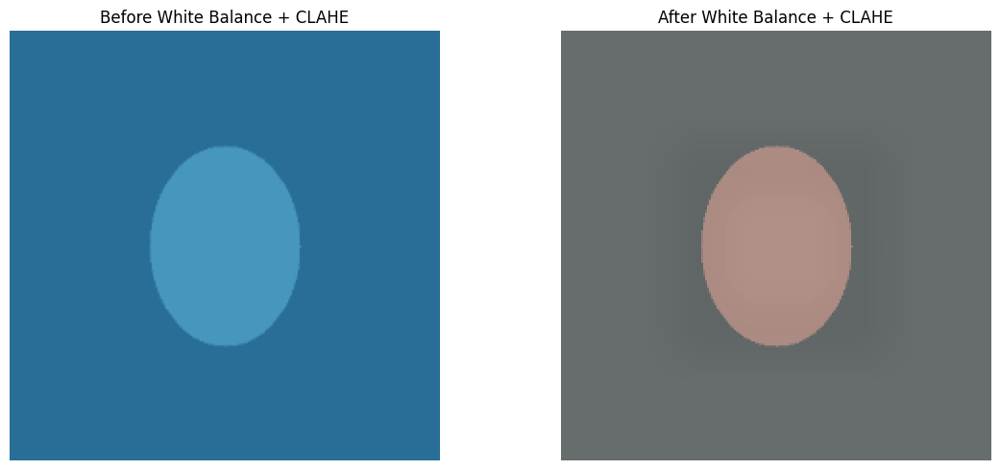


Transformed tensor information:
Shape: torch.Size([3, 224, 224])
Dtype: torch.float32
Minimum: -0.4739275872707367
Maximum: 0.8960527777671814

STEP 35 COMPLETED

Preprocessing pipeline:
1. Gray-World White Balance
2. LAB-space CLAHE
3. Resize to 224 × 224
4. Convert to Tensor
5. ImageNet normalization

CLAHE settings:
Clip limit     : 2.0
Tile grid size : (8, 8)

No train_loader required.
No val_loader required.
No test_loader required.
No CONFIG required.

Next step:
STEP 36 — Repeat model experiments using enhanced images


In [ ]:
# ============================================================
# STEP 35 — WHITE BALANCE + CLAHE PREPROCESSING
# ============================================================

import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
from torchvision import transforms


print("=" * 70)
print("STEP 35 — WHITE BALANCE + CLAHE PREPROCESSING")
print("=" * 70)


# ------------------------------------------------------------
# 1. IMAGE SIZE
# ------------------------------------------------------------

WB_CLAHE_IMAGE_SIZE = 224

print("\nImage size:", WB_CLAHE_IMAGE_SIZE)


# ------------------------------------------------------------
# 2. GRAY-WORLD WHITE BALANCE
# ------------------------------------------------------------

def gray_world_white_balance(image):
    """
    Gray-world white balance.

    Input:
        RGB uint8 image

    Output:
        RGB uint8 image
    """

    image = image.astype(np.float32)

    mean_r = np.mean(image[:, :, 0])
    mean_g = np.mean(image[:, :, 1])
    mean_b = np.mean(image[:, :, 2])

    mean_gray = (
        mean_r +
        mean_g +
        mean_b
    ) / 3.0

    mean_r = max(mean_r, 1e-6)
    mean_g = max(mean_g, 1e-6)
    mean_b = max(mean_b, 1e-6)

    image[:, :, 0] *= mean_gray / mean_r
    image[:, :, 1] *= mean_gray / mean_g
    image[:, :, 2] *= mean_gray / mean_b

    image = np.clip(
        image,
        0,
        255
    )

    return image.astype(np.uint8)


# ------------------------------------------------------------
# 3. CLAHE
# ------------------------------------------------------------

def apply_clahe(image):
    """
    Apply CLAHE to the luminance channel
    in LAB color space.
    """

    lab = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2LAB
    )

    l_channel, a_channel, b_channel = cv2.split(
        lab
    )

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    l_channel = clahe.apply(
        l_channel
    )

    lab = cv2.merge(
        [
            l_channel,
            a_channel,
            b_channel
        ]
    )

    enhanced = cv2.cvtColor(
        lab,
        cv2.COLOR_LAB2RGB
    )

    return enhanced


# ------------------------------------------------------------
# 4. COMBINED PREPROCESSING
# ------------------------------------------------------------

def white_balance_clahe(image):
    """
    Complete preprocessing:

    Original image
        ↓
    Gray-World White Balance
        ↓
    CLAHE
    """

    image = gray_world_white_balance(
        image
    )

    image = apply_clahe(
        image
    )

    return image


# ------------------------------------------------------------
# 5. MODEL INPUT TRANSFORM
# ------------------------------------------------------------

wb_clahe_transform = transforms.Compose([

    transforms.ToPILImage(),

    transforms.Resize(
        (
            WB_CLAHE_IMAGE_SIZE,
            WB_CLAHE_IMAGE_SIZE
        )
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],
        std=[
            0.229,
            0.224,
            0.225
        ]
    )
])


print("\nTransform created successfully.")


# ------------------------------------------------------------
# 6. CREATE A TEST IMAGE
# ------------------------------------------------------------
#
# This verifies that the preprocessing pipeline works
# without depending on train_loader or CONFIG.
#
# The test image is only a synthetic image for checking
# the preprocessing functions.
# ------------------------------------------------------------

test_image = np.zeros(
    (
        300,
        400,
        3
    ),
    dtype=np.uint8
)

# Create a simple underwater-like blue/green image
test_image[:, :, 0] = 40
test_image[:, :, 1] = 110
test_image[:, :, 2] = 150


# Add a brighter region
cv2.circle(
    test_image,
    (200, 150),
    70,
    (70, 150, 190),
    -1
)


# ------------------------------------------------------------
# 7. APPLY WHITE BALANCE + CLAHE
# ------------------------------------------------------------

enhanced_test_image = white_balance_clahe(
    test_image
)


# ------------------------------------------------------------
# 8. RESIZE
# ------------------------------------------------------------

original_display = cv2.resize(
    test_image,
    (
        WB_CLAHE_IMAGE_SIZE,
        WB_CLAHE_IMAGE_SIZE
    )
)

enhanced_display = cv2.resize(
    enhanced_test_image,
    (
        WB_CLAHE_IMAGE_SIZE,
        WB_CLAHE_IMAGE_SIZE
    )
)


# ------------------------------------------------------------
# 9. VISUALIZE
# ------------------------------------------------------------

plt.figure(
    figsize=(12, 5)
)


plt.subplot(
    1,
    2,
    1
)

plt.imshow(
    original_display
)

plt.title(
    "Before White Balance + CLAHE"
)

plt.axis("off")


plt.subplot(
    1,
    2,
    2
)

plt.imshow(
    enhanced_display
)

plt.title(
    "After White Balance + CLAHE"
)

plt.axis("off")


plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 10. TEST MODEL INPUT TRANSFORM
# ------------------------------------------------------------

enhanced_tensor = wb_clahe_transform(
    enhanced_test_image
)


print("\nTransformed tensor information:")
print(
    "Shape:",
    enhanced_tensor.shape
)

print(
    "Dtype:",
    enhanced_tensor.dtype
)

print(
    "Minimum:",
    enhanced_tensor.min().item()
)

print(
    "Maximum:",
    enhanced_tensor.max().item()
)


# ------------------------------------------------------------
# 11. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 35 COMPLETED")
print("=" * 70)

print("\nPreprocessing pipeline:")
print("1. Gray-World White Balance")
print("2. LAB-space CLAHE")
print("3. Resize to 224 × 224")
print("4. Convert to Tensor")
print("5. ImageNet normalization")

print("\nCLAHE settings:")
print("Clip limit     : 2.0")
print("Tile grid size : (8, 8)")

print("\nNo train_loader required.")
print("No val_loader required.")
print("No test_loader required.")
print("No CONFIG required.")

print("\nNext step:")
print("STEP 36 — Repeat model experiments using enhanced images")

STEP 36 — MODEL EXPERIMENTS WITH WHITE BALANCE + CLAHE

✓ train_loader found
✓ val_loader found
✓ test_loader found

Device: cuda
Image size: 224

✓ White Balance + CLAHE applied to:
  - Training set
  - Validation set
  - Test set

Number of classes: 4

TRAINING: ResNet50
Epoch 01/25 | Train Loss: 0.7351 | Train Acc: 0.7504 | Val Loss: 0.2894 | Val Acc: 0.9080
Epoch 02/25 | Train Loss: 0.2657 | Train Acc: 0.9163 | Val Loss: 0.2307 | Val Acc: 0.9195
Epoch 03/25 | Train Loss: 0.1909 | Train Acc: 0.9436 | Val Loss: 0.1800 | Val Acc: 0.9440
Epoch 04/25 | Train Loss: 0.1311 | Train Acc: 0.9601 | Val Loss: 0.1725 | Val Acc: 0.9483
Epoch 05/25 | Train Loss: 0.1148 | Train Acc: 0.9612 | Val Loss: 0.1590 | Val Acc: 0.9569
Epoch 06/25 | Train Loss: 0.1211 | Train Acc: 0.9612 | Val Loss: 0.1377 | Val Acc: 0.9612
Epoch 07/25 | Train Loss: 0.0821 | Train Acc: 0.9741 | Val Loss: 0.1582 | Val Acc: 0.9526
Epoch 08/25 | Train Loss: 0.0855 | Train Acc: 0.9752 | Val Loss: 0.1599 | Val Acc: 0.9526
Epoch 

100%|██████████| 82.7M/82.7M [00:00<00:00, 160MB/s]



TRAINING: EfficientNetV2_S
Epoch 01/25 | Train Loss: 0.6966 | Train Acc: 0.7471 | Val Loss: 0.2169 | Val Acc: 0.9339
Epoch 02/25 | Train Loss: 0.2043 | Train Acc: 0.9364 | Val Loss: 0.1503 | Val Acc: 0.9555
Epoch 03/25 | Train Loss: 0.1471 | Train Acc: 0.9583 | Val Loss: 0.1513 | Val Acc: 0.9540
Epoch 04/25 | Train Loss: 0.1227 | Train Acc: 0.9637 | Val Loss: 0.1521 | Val Acc: 0.9497
Epoch 05/25 | Train Loss: 0.0884 | Train Acc: 0.9723 | Val Loss: 0.1477 | Val Acc: 0.9598
Epoch 06/25 | Train Loss: 0.0612 | Train Acc: 0.9820 | Val Loss: 0.1563 | Val Acc: 0.9583
Epoch 07/25 | Train Loss: 0.0584 | Train Acc: 0.9806 | Val Loss: 0.1220 | Val Acc: 0.9670
Epoch 08/25 | Train Loss: 0.0510 | Train Acc: 0.9831 | Val Loss: 0.1504 | Val Acc: 0.9598
Epoch 09/25 | Train Loss: 0.0412 | Train Acc: 0.9874 | Val Loss: 0.1758 | Val Acc: 0.9497
Epoch 10/25 | Train Loss: 0.0331 | Train Acc: 0.9889 | Val Loss: 0.1892 | Val Acc: 0.9555
Epoch 11/25 | Train Loss: 0.0324 | Train Acc: 0.9903 | Val Loss: 0.1548 

100%|██████████| 109M/109M [00:00<00:00, 165MB/s] 



TRAINING: ConvNeXt_Tiny
Epoch 01/25 | Train Loss: 0.4261 | Train Acc: 0.8549 | Val Loss: 0.1793 | Val Acc: 0.9497
Epoch 02/25 | Train Loss: 0.1870 | Train Acc: 0.9440 | Val Loss: 0.1659 | Val Acc: 0.9497
Epoch 03/25 | Train Loss: 0.1198 | Train Acc: 0.9652 | Val Loss: 0.1399 | Val Acc: 0.9655
Epoch 04/25 | Train Loss: 0.1055 | Train Acc: 0.9705 | Val Loss: 0.1663 | Val Acc: 0.9483
Epoch 05/25 | Train Loss: 0.0662 | Train Acc: 0.9838 | Val Loss: 0.1528 | Val Acc: 0.9626
Epoch 06/25 | Train Loss: 0.0735 | Train Acc: 0.9767 | Val Loss: 0.1656 | Val Acc: 0.9425
Epoch 07/25 | Train Loss: 0.0453 | Train Acc: 0.9860 | Val Loss: 0.1297 | Val Acc: 0.9612
Epoch 08/25 | Train Loss: 0.0283 | Train Acc: 0.9932 | Val Loss: 0.1312 | Val Acc: 0.9698
Epoch 09/25 | Train Loss: 0.0295 | Train Acc: 0.9907 | Val Loss: 0.1471 | Val Acc: 0.9670
Epoch 10/25 | Train Loss: 0.0260 | Train Acc: 0.9914 | Val Loss: 0.1384 | Val Acc: 0.9612
Epoch 11/25 | Train Loss: 0.0222 | Train Acc: 0.9935 | Val Loss: 0.1332 | V

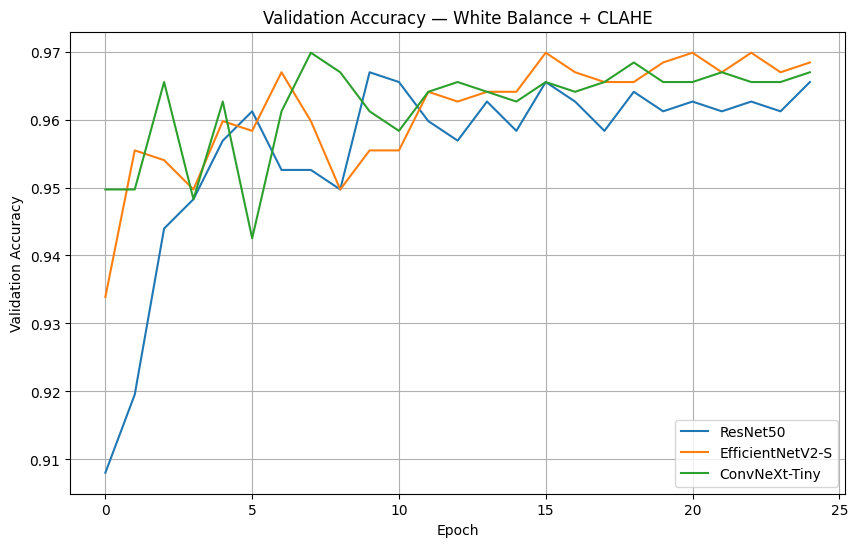


STEP 36 COMPLETED

Best validation accuracies:
ResNet50:       0.9670
EfficientNetV2: 0.9698
ConvNeXt-Tiny:  0.9698

Saved checkpoints:
  - resnet50_wb_clahe_best.pth
  - efficientnetv2_s_wb_clahe_best.pth
  - convnext_tiny_wb_clahe_best.pth

Next: Step 37 — Robustness Testing


In [ ]:
# ============================================================
# STEP 36 — REPEAT MODEL EXPERIMENTS WITH WHITE BALANCE + CLAHE
# ============================================================

import os
import copy
import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from torchvision import models, transforms
from torch.optim.lr_scheduler import ReduceLROnPlateau

print("=" * 70)
print("STEP 36 — MODEL EXPERIMENTS WITH WHITE BALANCE + CLAHE")
print("=" * 70)

# ------------------------------------------------------------
# 1. CHECK REQUIRED DATA LOADERS
# ------------------------------------------------------------

required = ["train_loader", "val_loader", "test_loader"]

missing = [x for x in required if x not in globals()]

if missing:
    print("\n❌ Required variables are missing:")
    for x in missing:
        print("   -", x)

    print("\nPlease rerun STEP 29 — TRAIN / VALIDATION / TEST DATALOADERS")
    print("Then run STEP 36 again.")

else:
    print("\n✓ train_loader found")
    print("✓ val_loader found")
    print("✓ test_loader found")

    # --------------------------------------------------------
    # 2. DEVICE
    # --------------------------------------------------------

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    print("\nDevice:", device)

    # --------------------------------------------------------
    # 3. IMAGE SIZE
    # --------------------------------------------------------

    IMAGE_SIZE = 224

    print("Image size:", IMAGE_SIZE)

    # --------------------------------------------------------
    # 4. WHITE BALANCE
    # --------------------------------------------------------

    def gray_world_white_balance(image):

        image = image.astype(np.float32)

        channel_means = image.mean(axis=(0, 1))

        gray_mean = channel_means.mean()

        scale = gray_mean / (channel_means + 1e-6)

        image = image * scale

        image = np.clip(image, 0, 255)

        return image.astype(np.uint8)

    # --------------------------------------------------------
    # 5. CLAHE
    # --------------------------------------------------------

    def apply_clahe(image):

        lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)

        l_channel, a_channel, b_channel = cv2.split(lab)

        clahe = cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(8, 8)
        )

        l_channel = clahe.apply(l_channel)

        lab = cv2.merge(
            [l_channel, a_channel, b_channel]
        )

        result = cv2.cvtColor(
            lab,
            cv2.COLOR_LAB2RGB
        )

        return result

    # --------------------------------------------------------
    # 6. COMBINED PREPROCESSING
    # --------------------------------------------------------

    def white_balance_clahe(image):

        image = gray_world_white_balance(image)

        image = apply_clahe(image)

        return image

    # --------------------------------------------------------
    # 7. TRANSFORM
    # --------------------------------------------------------

    imagenet_mean = [0.485, 0.456, 0.406]
    imagenet_std = [0.229, 0.224, 0.225]

    wb_clahe_transform = transforms.Compose([

        transforms.Lambda(
            lambda img: transforms.ToPILImage()(
                white_balance_clahe(
                    np.array(img)
                )
            )
        ),

        transforms.Resize(
            (IMAGE_SIZE, IMAGE_SIZE)
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=imagenet_mean,
            std=imagenet_std
        )
    ])

    # --------------------------------------------------------
    # 8. APPLY TRANSFORM TO DATASETS
    # --------------------------------------------------------

    train_dataset = train_loader.dataset
    val_dataset = val_loader.dataset
    test_dataset = test_loader.dataset

    # Keep original transforms so they can be restored later
    original_train_transform = getattr(
        train_dataset, "transform", None
    )

    original_val_transform = getattr(
        val_dataset, "transform", None
    )

    original_test_transform = getattr(
        test_dataset, "transform", None
    )

    train_dataset.transform = wb_clahe_transform
    val_dataset.transform = wb_clahe_transform
    test_dataset.transform = wb_clahe_transform

    print("\n✓ White Balance + CLAHE applied to:")
    print("  - Training set")
    print("  - Validation set")
    print("  - Test set")

    # --------------------------------------------------------
    # 9. NUMBER OF CLASSES
    # --------------------------------------------------------

    if hasattr(train_dataset, "classes"):
        num_classes = len(train_dataset.classes)
        class_names = train_dataset.classes

    elif hasattr(train_dataset, "dataset") and hasattr(
        train_dataset.dataset, "classes"
    ):
        num_classes = len(train_dataset.dataset.classes)
        class_names = train_dataset.dataset.classes

    else:
        raise RuntimeError(
            "Could not determine the number of classes."
        )

    print("\nNumber of classes:", num_classes)

    # --------------------------------------------------------
    # 10. TRAINING FUNCTION
    # --------------------------------------------------------

    def train_model(
        model,
        model_name,
        epochs=10,
        learning_rate=1e-4,
        weight_decay=1e-4
    ):

        model = model.to(device)

        criterion = nn.CrossEntropyLoss()

        optimizer = optim.Adam(
            model.parameters(),
            lr=learning_rate,
            weight_decay=weight_decay
        )

        scheduler = ReduceLROnPlateau(
            optimizer,
            mode="min",
            factor=0.5,
            patience=2
        )

        best_val_loss = float("inf")
        best_state = None

        history = {
            "train_loss": [],
            "val_loss": [],
            "train_acc": [],
            "val_acc": []
        }

        print("\n" + "=" * 70)
        print("TRAINING:", model_name)
        print("=" * 70)

        for epoch in range(epochs):

            # -----------------------------
            # TRAIN
            # -----------------------------

            model.train()

            running_loss = 0.0
            correct = 0
            total = 0

            for images, labels in train_loader:

                images = images.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                outputs = model(images)

                loss = criterion(
                    outputs,
                    labels
                )

                loss.backward()

                optimizer.step()

                running_loss += (
                    loss.item() * images.size(0)
                )

                _, predicted = torch.max(
                    outputs,
                    1
                )

                total += labels.size(0)

                correct += (
                    predicted == labels
                ).sum().item()

            train_loss = running_loss / len(
                train_loader.dataset
            )

            train_acc = correct / total

            # -----------------------------
            # VALIDATION
            # -----------------------------

            model.eval()

            val_loss_total = 0.0
            val_correct = 0
            val_total = 0

            with torch.no_grad():

                for images, labels in val_loader:

                    images = images.to(device)
                    labels = labels.to(device)

                    outputs = model(images)

                    loss = criterion(
                        outputs,
                        labels
                    )

                    val_loss_total += (
                        loss.item() * images.size(0)
                    )

                    _, predicted = torch.max(
                        outputs,
                        1
                    )

                    val_total += labels.size(0)

                    val_correct += (
                        predicted == labels
                    ).sum().item()

            val_loss = val_loss_total / len(
                val_loader.dataset
            )

            val_acc = val_correct / val_total

            scheduler.step(val_loss)

            history["train_loss"].append(
                train_loss
            )

            history["val_loss"].append(
                val_loss
            )

            history["train_acc"].append(
                train_acc
            )

            history["val_acc"].append(
                val_acc
            )

            print(
                f"Epoch {epoch+1:02d}/{epochs} | "
                f"Train Loss: {train_loss:.4f} | "
                f"Train Acc: {train_acc:.4f} | "
                f"Val Loss: {val_loss:.4f} | "
                f"Val Acc: {val_acc:.4f}"
            )

            # -----------------------------
            # SAVE BEST MODEL
            # -----------------------------

            if val_loss < best_val_loss:

                best_val_loss = val_loss

                best_state = copy.deepcopy(
                    model.state_dict()
                )

        # Restore best model
        model.load_state_dict(best_state)

        save_name = (
            model_name.lower()
            .replace(" ", "_")
            .replace("-", "_")
            + "_wb_clahe_best.pth"
        )

        torch.save(
            model.state_dict(),
            save_name
        )

        print(
            "\n✓ Best model saved:",
            save_name
        )

        return model, history

    # --------------------------------------------------------
    # 11. RESNET50 + WB/CLAHE
    # --------------------------------------------------------

    resnet50 = models.resnet50(
        weights=models.ResNet50_Weights.DEFAULT
    )

    resnet50.fc = nn.Linear(
        resnet50.fc.in_features,
        num_classes
    )

    resnet50_wb, resnet50_history = train_model(
        resnet50,
        "ResNet50",
        epochs=25
    )

    # --------------------------------------------------------
    # 12. EFFICIENTNET-V2-S + WB/CLAHE
    # --------------------------------------------------------

    efficientnet = models.efficientnet_v2_s(
        weights=models.EfficientNet_V2_S_Weights.DEFAULT
    )

    efficientnet.classifier[-1] = nn.Linear(
        efficientnet.classifier[-1].in_features,
        num_classes
    )

    efficientnet_wb, efficientnet_history = train_model(
        efficientnet,
        "EfficientNetV2_S",
        epochs=25
    )

    # --------------------------------------------------------
    # 13. CONVNEXT-TINY + WB/CLAHE
    # --------------------------------------------------------

    convnext = models.convnext_tiny(
        weights=models.ConvNeXt_Tiny_Weights.DEFAULT
    )

    convnext.classifier[-1] = nn.Linear(
        convnext.classifier[-1].in_features,
        num_classes
    )

    convnext_wb, convnext_history = train_model(
        convnext,
        "ConvNeXt_Tiny",
        epochs=25
    )

    # --------------------------------------------------------
    # 14. PLOT VALIDATION ACCURACY
    # --------------------------------------------------------

    plt.figure(figsize=(10, 6))

    plt.plot(
        resnet50_history["val_acc"],
        label="ResNet50"
    )

    plt.plot(
        efficientnet_history["val_acc"],
        label="EfficientNetV2-S"
    )

    plt.plot(
        convnext_history["val_acc"],
        label="ConvNeXt-Tiny"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Validation Accuracy")

    plt.title(
        "Validation Accuracy — White Balance + CLAHE"
    )

    plt.legend()

    plt.grid(True)

    plt.show()

    # --------------------------------------------------------
    # 15. FINAL SUMMARY
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("STEP 36 COMPLETED")
    print("=" * 70)

    print("\nBest validation accuracies:")

    print(
        f"ResNet50:       "
        f"{max(resnet50_history['val_acc']):.4f}"
    )

    print(
        f"EfficientNetV2: "
        f"{max(efficientnet_history['val_acc']):.4f}"
    )

    print(
        f"ConvNeXt-Tiny:  "
        f"{max(convnext_history['val_acc']):.4f}"
    )

    print("\nSaved checkpoints:")
    print("  - resnet50_wb_clahe_best.pth")
    print("  - efficientnetv2_s_wb_clahe_best.pth")
    print("  - convnext_tiny_wb_clahe_best.pth")

    print("\nNext: Step 37 — Robustness Testing")

In [ ]:
import os

print("Saved model files:")

for file in os.listdir("/content"):
    if file.endswith(".pth"):
        path = os.path.join("/content", file)
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"{file}  —  {size_mb:.2f} MB")

Saved model files:
efficientnetv2_s_wb_clahe_best.pth  —  77.87 MB
convnext_tiny_wb_clahe_best.pth  —  106.20 MB
resnet50_wb_clahe_best.pth  —  90.02 MB


In [ ]:
from google.colab import files

files.download("/content/resnet50_wb_clahe_best.pth")
files.download("/content/efficientnetv2_s_wb_clahe_best.pth")
files.download("/content/convnext_tiny_wb_clahe_best.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# STEP 29 — CREATE TRAIN / VALIDATION / TEST DATALOADERS
# ============================================================

import os
import torch
import numpy as np

from torch.utils.data import (
    DataLoader,
    random_split,
    Subset
)

from torchvision import (
    datasets,
    transforms
)

print("=" * 70)
print("STEP 29 — TRAIN / VALIDATION / TEST DATALOADERS")
print("=" * 70)


# ============================================================
# 1. BASIC SETTINGS
# ============================================================

IMAGE_SIZE = 224
BATCH_SIZE = 32

NUM_WORKERS = 2

RANDOM_SEED = 42

VAL_RATIO = 0.20


# ============================================================
# 2. FIND DATASET
# ============================================================

print("\nSearching for dataset...")

train_dir = None
test_dir = None

# Search for directories named train/test
for root, dirs, files in os.walk("/content"):

    lower_dirs = {
        d.lower(): d
        for d in dirs
    }

    if "train" in lower_dirs and "test" in lower_dirs:

        train_candidate = os.path.join(
            root,
            lower_dirs["train"]
        )

        test_candidate = os.path.join(
            root,
            lower_dirs["test"]
        )

        # Make sure train contains class folders
        train_subdirs = [
            d for d in os.listdir(train_candidate)
            if os.path.isdir(
                os.path.join(train_candidate, d)
            )
        ]

        if len(train_subdirs) > 0:

            train_dir = train_candidate
            test_dir = test_candidate

            break


# ============================================================
# 3. CHECK DATASET PATH
# ============================================================

if train_dir is None or test_dir is None:

    print("\n❌ TRAIN / TEST FOLDERS COULD NOT BE FOUND.")

    print("\nFolders under /content:")

    for item in os.listdir("/content"):

        path = os.path.join(
            "/content",
            item
        )

        if os.path.isdir(path):

            print("  ", path)

    raise FileNotFoundError(
        "\nCould not automatically find the train and test folders. "
        "Please check the dataset extraction path."
    )


print("\n✓ Train directory:")
print(" ", train_dir)

print("\n✓ Test directory:")
print(" ", test_dir)


# ============================================================
# 4. IMAGE TRANSFORMS
# ============================================================

imagenet_mean = [
    0.485,
    0.456,
    0.406
]

imagenet_std = [
    0.229,
    0.224,
    0.225
]


# Training augmentation
train_transform = transforms.Compose([

    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        degrees=10
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=imagenet_mean,
        std=imagenet_std
    )
])


# Validation / Test transform
eval_transform = transforms.Compose([

    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=imagenet_mean,
        std=imagenet_std
    )
])


# ============================================================
# 5. LOAD FULL TRAINING DATASET
# ============================================================

full_train_dataset = datasets.ImageFolder(
    root=train_dir,
    transform=train_transform
)


# ============================================================
# 6. LOAD TEST DATASET
# ============================================================

test_dataset = datasets.ImageFolder(
    root=test_dir,
    transform=eval_transform
)


# ============================================================
# 7. CHECK CLASS NAMES
# ============================================================

print("\nNumber of classes:",
      len(full_train_dataset.classes))

print("\nClasses:")

for i, class_name in enumerate(
    full_train_dataset.classes
):

    print(
        f"  {i}: {class_name}"
    )


# ============================================================
# 8. CHECK TRAIN / TEST CLASS CONSISTENCY
# ============================================================

if full_train_dataset.classes != test_dataset.classes:

    print("\n⚠️ WARNING:")
    print("Train and test class lists are different.")

    print("\nTrain classes:")
    print(full_train_dataset.classes)

    print("\nTest classes:")
    print(test_dataset.classes)

    raise ValueError(
        "Train/test class mismatch."
    )


# ============================================================
# 9. TRAIN / VALIDATION SPLIT
# ============================================================

dataset_size = len(
    full_train_dataset
)

val_size = int(
    dataset_size * VAL_RATIO
)

train_size = (
    dataset_size - val_size
)


generator = torch.Generator().manual_seed(
    RANDOM_SEED
)


train_subset, val_subset = random_split(
    full_train_dataset,
    [
        train_size,
        val_size
    ],
    generator=generator
)


# ============================================================
# 10. CREATE SEPARATE VALIDATION DATASET
#     WITH NO TRAINING AUGMENTATION
# ============================================================

# Create another ImageFolder using
# validation/test transforms.

full_val_dataset = datasets.ImageFolder(
    root=train_dir,
    transform=eval_transform
)


# Use the exact same indices selected above
val_dataset = Subset(
    full_val_dataset,
    val_subset.indices
)


train_dataset = train_subset


# ============================================================
# 11. PRINT DATASET SIZES
# ============================================================

print("\nDataset split:")

print(
    "  Total training images:",
    dataset_size
)

print(
    "  Training images:",
    len(train_dataset)
)

print(
    "  Validation images:",
    len(val_dataset)
)

print(
    "  Test images:",
    len(test_dataset)
)


# ============================================================
# 12. CREATE DATALOADERS
# ============================================================

train_loader = DataLoader(

    train_dataset,

    batch_size=BATCH_SIZE,

    shuffle=True,

    num_workers=NUM_WORKERS,

    pin_memory=torch.cuda.is_available()
)


val_loader = DataLoader(

    val_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=NUM_WORKERS,

    pin_memory=torch.cuda.is_available()
)


test_loader = DataLoader(

    test_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=NUM_WORKERS,

    pin_memory=torch.cuda.is_available()
)


# ============================================================
# 13. CHECK ONE BATCH
# ============================================================

images, labels = next(
    iter(train_loader)
)


print("\nFirst training batch:")

print(
    "  Image shape:",
    images.shape
)

print(
    "  Label shape:",
    labels.shape
)

print(
    "  Image dtype:",
    images.dtype
)

print(
    "  Label dtype:",
    labels.dtype
)


# ============================================================
# 14. DEVICE
# ============================================================

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


print("\nDevice:", device)


if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )


# ============================================================
# 15. FINAL CHECK
# ============================================================

print("\n" + "=" * 70)
print("STEP 29 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nVariables created:")

print("  ✓ train_dataset")
print("  ✓ val_dataset")
print("  ✓ test_dataset")

print("  ✓ train_loader")
print("  ✓ val_loader")
print("  ✓ test_loader")

print("\nReady for Step 30 onward.")

STEP 29 — TRAIN / VALIDATION / TEST DATALOADERS

Searching for dataset...

✓ Train directory:
  /content/uwi2020/cls_crops/train

✓ Test directory:
  /content/uwi2020/cls_crops/test

Number of classes: 4

Classes:
  0: echinus
  1: holothurian
  2: scallop
  3: starfish

Dataset split:
  Total training images: 3480
  Training images: 2784
  Validation images: 696
  Test images: 870

First training batch:
  Image shape: torch.Size([32, 3, 224, 224])
  Label shape: torch.Size([32])
  Image dtype: torch.float32
  Label dtype: torch.int64

Device: cuda
GPU: Tesla T4

STEP 29 COMPLETED SUCCESSFULLY

Variables created:
  ✓ train_dataset
  ✓ val_dataset
  ✓ test_dataset
  ✓ train_loader
  ✓ val_loader
  ✓ test_loader

Ready for Step 30 onward.


In [ ]:
# ============================================================
# STEP 37 — ROBUSTNESS TESTING (CORRECTED)
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import cv2

from PIL import Image, ImageEnhance
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

print("=" * 70)
print("STEP 37 — ROBUSTNESS TESTING")
print("=" * 70)

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 0   # safer for Colab robustness testing

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"\nDevice: {device}")

# ------------------------------------------------------------
# 2. IMAGE PREPROCESSING
#    Same WB + CLAHE pipeline used in Step 36
# ------------------------------------------------------------

imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

def white_balance_gray_world(image):
    """
    Gray-world white balance.
    Input: RGB uint8 numpy array
    Output: RGB uint8 numpy array
    """

    image = image.astype(np.float32)

    mean_rgb = image.mean(axis=(0, 1))

    gray_mean = mean_rgb.mean()

    scale = gray_mean / (mean_rgb + 1e-8)

    balanced = image * scale

    balanced = np.clip(balanced, 0, 255)

    return balanced.astype(np.uint8)


def apply_clahe(image):
    """
    Apply CLAHE to the L channel in LAB color space.
    Input/output: RGB uint8 numpy array
    """

    lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)

    l_channel, a_channel, b_channel = cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    l_channel = clahe.apply(l_channel)

    lab = cv2.merge([
        l_channel,
        a_channel,
        b_channel
    ])

    result = cv2.cvtColor(
        lab,
        cv2.COLOR_LAB2RGB
    )

    return result


def preprocess_image(image):
    """
    Raw PIL RGB image
    ->
    White Balance
    ->
    CLAHE
    ->
    Resize
    ->
    Tensor CHW
    ->
    ImageNet normalization
    """

    # PIL -> numpy RGB
    image = np.array(
        image.convert("RGB"),
        dtype=np.uint8
    )

    # White balance
    image = white_balance_gray_world(image)

    # CLAHE
    image = apply_clahe(image)

    # Resize
    image = cv2.resize(
        image,
        (IMAGE_SIZE, IMAGE_SIZE),
        interpolation=cv2.INTER_AREA
    )

    # HWC -> CHW
    image = torch.from_numpy(
        image.copy()
    ).permute(2, 0, 1).float() / 255.0

    # ImageNet normalization
    mean = torch.tensor(
        imagenet_mean,
        dtype=torch.float32
    ).view(3, 1, 1)

    std = torch.tensor(
        imagenet_std,
        dtype=torch.float32
    ).view(3, 1, 1)

    image = (image - mean) / std

    return image


# ------------------------------------------------------------
# 3. ROBUSTNESS TRANSFORMATIONS
# ------------------------------------------------------------

def apply_perturbation(image, perturbation):
    """
    Input:
        PIL RGB image

    Output:
        PIL RGB image after perturbation
    """

    image = image.convert("RGB")

    if perturbation == "Original":
        return image

    elif perturbation == "Brightness":
        return ImageEnhance.Brightness(
            image
        ).enhance(0.65)

    elif perturbation == "Contrast":
        return ImageEnhance.Contrast(
            image
        ).enhance(0.65)

    elif perturbation == "Blur":
        arr = np.array(image)

        arr = cv2.GaussianBlur(
            arr,
            (9, 9),
            0
        )

        return Image.fromarray(arr)

    elif perturbation == "Noise":
        arr = np.array(image).astype(np.float32)

        noise = np.random.normal(
            0,
            20,
            arr.shape
        )

        arr = arr + noise

        arr = np.clip(
            arr,
            0,
            255
        ).astype(np.uint8)

        return Image.fromarray(arr)

    elif perturbation == "Low Resolution":
        arr = np.array(image)

        small = cv2.resize(
            arr,
            (56, 56),
            interpolation=cv2.INTER_AREA
        )

        arr = cv2.resize(
            small,
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=cv2.INTER_NEAREST
        )

        return Image.fromarray(arr)

    elif perturbation == "Color Shift":
        arr = np.array(image).astype(np.int16)

        arr[:, :, 0] = np.clip(
            arr[:, :, 0] + 30,
            0,
            255
        )

        arr[:, :, 1] = np.clip(
            arr[:, :, 1] - 15,
            0,
            255
        )

        arr = arr.astype(np.uint8)

        return Image.fromarray(arr)

    else:
        return image


# ------------------------------------------------------------
# 4. ROBUSTNESS DATASET
# ------------------------------------------------------------

class RobustnessDataset(Dataset):

    def __init__(
        self,
        samples,
        perturbation="Original"
    ):

        self.samples = samples
        self.perturbation = perturbation

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):

        image_path, label = self.samples[index]

        # IMPORTANT:
        # Read raw image directly from disk.
        # This avoids using the already-normalized
        # ImageFolder tensor.

        image = Image.open(
            image_path
        ).convert("RGB")

        # Apply robustness perturbation
        image = apply_perturbation(
            image,
            self.perturbation
        )

        # Apply WB + CLAHE + normalization
        image = preprocess_image(
            image
        )

        return image, label


# ------------------------------------------------------------
# 5. CHECK TEST DATASET
# ------------------------------------------------------------

if not hasattr(test_dataset, "samples"):

    raise RuntimeError(
        "test_dataset does not contain raw image samples."
    )

test_samples = test_dataset.samples

print(
    f"\nNumber of test images: {len(test_samples)}"
)

print(
    f"Number of classes: {len(test_dataset.classes)}"
)


# ------------------------------------------------------------
# 6. LOAD TRAINED MODELS
# ------------------------------------------------------------

print("\nLoading trained models...")

models_dict = {}


# ---------- ResNet50 ----------

resnet50 = models.resnet50(
    weights=None
)

resnet50.fc = nn.Linear(
    resnet50.fc.in_features,
    num_classes
)

resnet50.load_state_dict(
    torch.load(
        "/content/resnet50_wb_clahe_best.pth",
        map_location=device
    )
)

resnet50 = resnet50.to(device)
resnet50.eval()

models_dict["ResNet50"] = resnet50


# ---------- EfficientNetV2-S ----------

efficientnet = models.efficientnet_v2_s(
    weights=None
)

efficientnet.classifier[1] = nn.Linear(
    efficientnet.classifier[1].in_features,
    num_classes
)

efficientnet.load_state_dict(
    torch.load(
        "/content/efficientnetv2_s_wb_clahe_best.pth",
        map_location=device
    )
)

efficientnet = efficientnet.to(device)
efficientnet.eval()

models_dict["EfficientNetV2-S"] = efficientnet


# ---------- ConvNeXt-Tiny ----------

convnext = models.convnext_tiny(
    weights=None
)

convnext.classifier[2] = nn.Linear(
    convnext.classifier[2].in_features,
    num_classes
)

convnext.load_state_dict(
    torch.load(
        "/content/convnext_tiny_wb_clahe_best.pth",
        map_location=device
    )
)

convnext = convnext.to(device)
convnext.eval()

models_dict["ConvNeXt-Tiny"] = convnext


print(
    "\nModels loaded:",
    list(models_dict.keys())
)


# ------------------------------------------------------------
# 7. EVALUATION FUNCTION
# ------------------------------------------------------------

def evaluate_model(
    model,
    loader
):

    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            outputs = model(images)

            predictions = outputs.argmax(
                dim=1
            )

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

    accuracy = (
        100.0 * correct / total
        if total > 0
        else 0.0
    )

    return accuracy


# ------------------------------------------------------------
# 8. ROBUSTNESS CONDITIONS
# ------------------------------------------------------------

perturbations = [
    "Original",
    "Brightness",
    "Contrast",
    "Blur",
    "Noise",
    "Low Resolution",
    "Color Shift"
]


# ------------------------------------------------------------
# 9. RUN ROBUSTNESS TEST
# ------------------------------------------------------------

results = []

for perturbation in perturbations:

    print(
        f"\nTesting: {perturbation}"
    )

    robust_dataset = RobustnessDataset(
        test_samples,
        perturbation=perturbation
    )

    robust_loader = DataLoader(
        robust_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available()
    )

    row = {
        "Condition": perturbation
    }

    for model_name, model in models_dict.items():

        accuracy = evaluate_model(
            model,
            robust_loader
        )

        row[model_name] = accuracy

        print(
            f"  {model_name}: "
            f"{accuracy:.2f}%"
        )

    results.append(row)


# ------------------------------------------------------------
# 10. RESULTS TABLE
# ------------------------------------------------------------

results_df = pd.DataFrame(
    results
)

print("\n")
print("=" * 70)
print("ROBUSTNESS TEST RESULTS")
print("=" * 70)

display(
    results_df.style.format(
        {
            "ResNet50": "{:.2f}%",
            "EfficientNetV2-S": "{:.2f}%",
            "ConvNeXt-Tiny": "{:.2f}%"
        }
    )
)


# ------------------------------------------------------------
# 11. SAVE RESULTS
# ------------------------------------------------------------

results_path = (
    "/content/step37_robustness_results.csv"
)

results_df.to_csv(
    results_path,
    index=False
)

print(
    f"\nResults saved to:\n{results_path}"
)

print("\n" + "=" * 70)
print("STEP 37 COMPLETED")
print("=" * 70)

STEP 37 — ROBUSTNESS TESTING

Device: cuda

Number of test images: 870
Number of classes: 4

Loading trained models...

Models loaded: ['ResNet50', 'EfficientNetV2-S', 'ConvNeXt-Tiny']

Testing: Original
  ResNet50: 75.98%
  EfficientNetV2-S: 79.54%
  ConvNeXt-Tiny: 84.37%

Testing: Brightness
  ResNet50: 73.33%
  EfficientNetV2-S: 81.61%
  ConvNeXt-Tiny: 82.99%

Testing: Contrast
  ResNet50: 73.45%
  EfficientNetV2-S: 79.77%
  ConvNeXt-Tiny: 83.10%

Testing: Blur
  ResNet50: 74.02%
  EfficientNetV2-S: 73.56%
  ConvNeXt-Tiny: 83.22%

Testing: Noise
  ResNet50: 38.74%
  EfficientNetV2-S: 52.18%
  ConvNeXt-Tiny: 71.26%

Testing: Low Resolution
  ResNet50: 79.43%
  EfficientNetV2-S: 76.32%
  ConvNeXt-Tiny: 69.77%

Testing: Color Shift
  ResNet50: 75.86%
  EfficientNetV2-S: 79.31%
  ConvNeXt-Tiny: 84.71%


ROBUSTNESS TEST RESULTS


,Condition,ResNet50,EfficientNetV2-S,ConvNeXt-Tiny
0,Original,75.98%,79.54%,84.37%
1,Brightness,73.33%,81.61%,82.99%
2,Contrast,73.45%,79.77%,83.10%
3,Blur,74.02%,73.56%,83.22%
4,Noise,38.74%,52.18%,71.26%
5,Low Resolution,79.43%,76.32%,69.77%
6,Color Shift,75.86%,79.31%,84.71%



Results saved to:
/content/step37_robustness_results.csv

STEP 37 COMPLETED


STEP 38 — GRAD-CAM / EXPLAINABLE AI

Device: cuda

Loading trained models...

Models loaded: ['ResNet50', 'EfficientNetV2-S', 'ConvNeXt-Tiny']

Generating Grad-CAM for 3 test images...

Image 1: 000113_48d3b7d9.jpg
True class: echinus


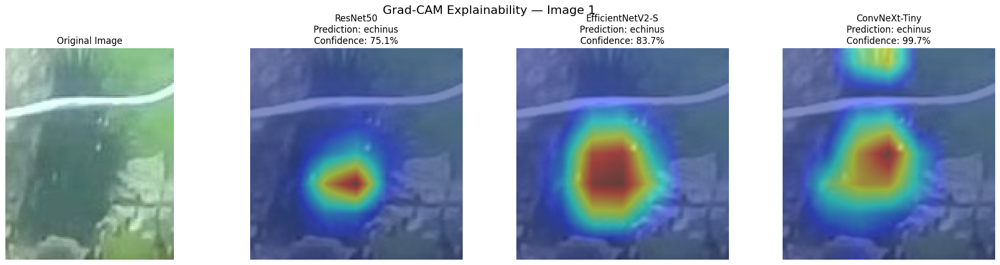


Image 2: 001194_f8d5b92f.jpg
True class: holothurian


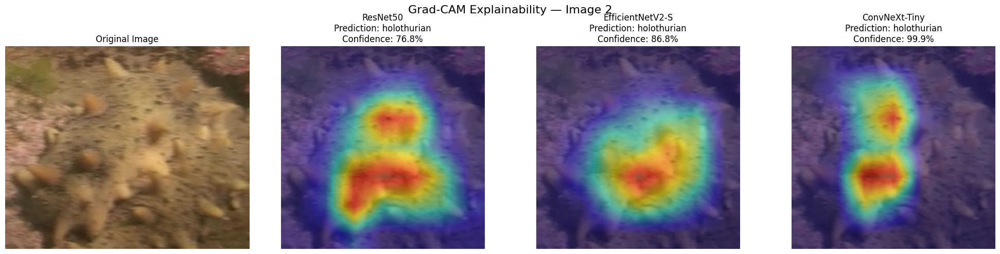


Image 3: 001198_e0f3e861.jpg
True class: starfish


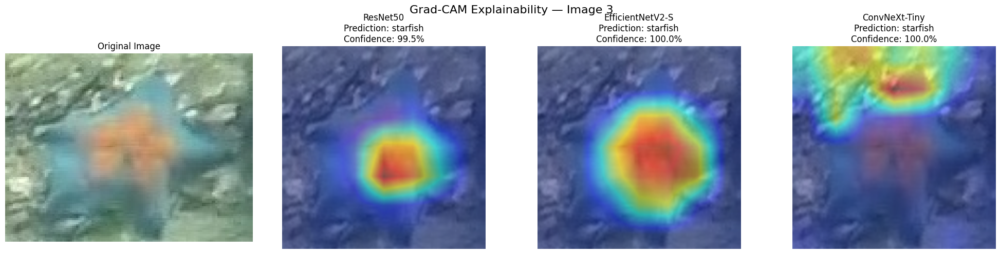


Grad-CAM files saved in:
/content/step38_gradcam
   gradcam_image_1.png
   gradcam_image_2.png
   gradcam_image_3.png

STEP 38 COMPLETED


In [ ]:
# ============================================================
# STEP 38 — GRAD-CAM / EXPLAINABLE AI
# ============================================================

import os
import cv2
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from PIL import Image
from torchvision import models

print("=" * 70)
print("STEP 38 — GRAD-CAM / EXPLAINABLE AI")
print("=" * 70)


# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

IMAGE_SIZE = 224

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"\nDevice: {device}")


# ------------------------------------------------------------
# 2. IMAGE PREPROCESSING
#    Same WB + CLAHE preprocessing used in Step 36
# ------------------------------------------------------------

imagenet_mean = torch.tensor(
    [0.485, 0.456, 0.406],
    dtype=torch.float32
).view(3, 1, 1)

imagenet_std = torch.tensor(
    [0.229, 0.224, 0.225],
    dtype=torch.float32
).view(3, 1, 1)


def white_balance_gray_world(image):

    image = image.astype(np.float32)

    mean_rgb = image.mean(axis=(0, 1))

    gray_mean = mean_rgb.mean()

    scale = gray_mean / (mean_rgb + 1e-8)

    balanced = image * scale

    balanced = np.clip(
        balanced,
        0,
        255
    )

    return balanced.astype(np.uint8)


def apply_clahe(image):

    lab = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2LAB
    )

    l_channel, a_channel, b_channel = cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    l_channel = clahe.apply(l_channel)

    lab = cv2.merge([
        l_channel,
        a_channel,
        b_channel
    ])

    result = cv2.cvtColor(
        lab,
        cv2.COLOR_LAB2RGB
    )

    return result


def preprocess_for_model(image):

    # PIL -> RGB numpy
    image = np.array(
        image.convert("RGB"),
        dtype=np.uint8
    )

    # White Balance
    image = white_balance_gray_world(image)

    # CLAHE
    image = apply_clahe(image)

    # Resize
    image = cv2.resize(
        image,
        (IMAGE_SIZE, IMAGE_SIZE),
        interpolation=cv2.INTER_AREA
    )

    # HWC -> CHW
    tensor = torch.from_numpy(
        image.copy()
    ).permute(
        2, 0, 1
    ).float() / 255.0

    # ImageNet normalization
    tensor = (
        tensor - imagenet_mean
    ) / imagenet_std

    return tensor


# ------------------------------------------------------------
# 3. LOAD MODELS
# ------------------------------------------------------------

print("\nLoading trained models...")


# ---------- ResNet50 ----------

resnet50 = models.resnet50(
    weights=None
)

resnet50.fc = nn.Linear(
    resnet50.fc.in_features,
    num_classes
)

resnet50.load_state_dict(
    torch.load(
        "/content/resnet50_wb_clahe_best.pth",
        map_location=device
    )
)

resnet50 = resnet50.to(device)
resnet50.eval()


# ---------- EfficientNetV2-S ----------

efficientnet = models.efficientnet_v2_s(
    weights=None
)

efficientnet.classifier[1] = nn.Linear(
    efficientnet.classifier[1].in_features,
    num_classes
)

efficientnet.load_state_dict(
    torch.load(
        "/content/efficientnetv2_s_wb_clahe_best.pth",
        map_location=device
    )
)

efficientnet = efficientnet.to(device)
efficientnet.eval()


# ---------- ConvNeXt-Tiny ----------

convnext = models.convnext_tiny(
    weights=None
)

convnext.classifier[2] = nn.Linear(
    convnext.classifier[2].in_features,
    num_classes
)

convnext.load_state_dict(
    torch.load(
        "/content/convnext_tiny_wb_clahe_best.pth",
        map_location=device
    )
)

convnext = convnext.to(device)
convnext.eval()


models_dict = {
    "ResNet50": resnet50,
    "EfficientNetV2-S": efficientnet,
    "ConvNeXt-Tiny": convnext
}

print(
    "\nModels loaded:",
    list(models_dict.keys())
)


# ------------------------------------------------------------
# 4. GRAD-CAM CLASS
# ------------------------------------------------------------

class GradCAM:

    def __init__(
        self,
        model,
        target_layer
    ):

        self.model = model
        self.target_layer = target_layer

        self.activations = None
        self.gradients = None

        self.forward_hook = (
            target_layer.register_forward_hook(
                self.save_activation
            )
        )

        self.backward_hook = (
            target_layer.register_full_backward_hook(
                self.save_gradient
            )
        )


    def save_activation(
        self,
        module,
        input,
        output
    ):

        self.activations = output


    def save_gradient(
        self,
        module,
        grad_input,
        grad_output
    ):

        self.gradients = grad_output[0]


    def generate(
        self,
        input_tensor,
        target_class=None
    ):

        self.model.zero_grad()

        output = self.model(
            input_tensor
        )

        if target_class is None:

            target_class = (
                output.argmax(
                    dim=1
                ).item()
            )

        score = output[
            0,
            target_class
        ]

        score.backward()

        activations = self.activations
        gradients = self.gradients

        # Global average pooling of gradients
        weights = gradients.mean(
            dim=(2, 3),
            keepdim=True
        )

        # Weighted activation maps
        cam = (
            weights * activations
        ).sum(
            dim=1,
            keepdim=True
        )

        # ReLU
        cam = torch.relu(cam)

        # Resize to image size
        cam = torch.nn.functional.interpolate(
            cam,
            size=(
                IMAGE_SIZE,
                IMAGE_SIZE
            ),
            mode="bilinear",
            align_corners=False
        )

        cam = cam.squeeze().detach().cpu().numpy()

        # Normalize 0-1
        cam -= cam.min()

        if cam.max() > 0:
            cam /= cam.max()

        return cam, target_class, output


    def remove_hooks(self):

        self.forward_hook.remove()
        self.backward_hook.remove()


# ------------------------------------------------------------
# 5. MODEL-SPECIFIC TARGET LAYERS
# ------------------------------------------------------------

target_layers = {

    "ResNet50":
        resnet50.layer4[-1],

    "EfficientNetV2-S":
        efficientnet.features[-1],

    "ConvNeXt-Tiny":
        convnext.features[-1]
}


# ------------------------------------------------------------
# 6. SELECT TEST IMAGES
# ------------------------------------------------------------

# Select up to 3 representative test images
num_visualizations = min(
    3,
    len(test_dataset.samples)
)

selected_indices = np.linspace(
    0,
    len(test_dataset.samples) - 1,
    num_visualizations,
    dtype=int
)

print(
    f"\nGenerating Grad-CAM for "
    f"{num_visualizations} test images..."
)


# ------------------------------------------------------------
# 7. CREATE OUTPUT DIRECTORY
# ------------------------------------------------------------

gradcam_dir = (
    "/content/step38_gradcam"
)

os.makedirs(
    gradcam_dir,
    exist_ok=True
)


# ------------------------------------------------------------
# 8. GENERATE GRAD-CAM
# ------------------------------------------------------------

for image_number, index in enumerate(
    selected_indices,
    start=1
):

    image_path, true_label = (
        test_dataset.samples[index]
    )

    original_image = Image.open(
        image_path
    ).convert("RGB")

    # Prepare model input
    input_tensor = preprocess_for_model(
        original_image
    ).unsqueeze(0).to(device)

    print(
        f"\nImage {image_number}: "
        f"{os.path.basename(image_path)}"
    )

    print(
        f"True class: "
        f"{test_dataset.classes[true_label]}"
    )


    # --------------------------------------------------------
    # Figure: Original + 3 Grad-CAMs
    # --------------------------------------------------------

    fig, axes = plt.subplots(
        1,
        4,
        figsize=(20, 5)
    )


    # Original image
    axes[0].imshow(
        original_image
    )

    axes[0].set_title(
        "Original Image"
    )

    axes[0].axis("off")


    # --------------------------------------------------------
    # Each model
    # --------------------------------------------------------

    for plot_index, (
        model_name,
        model
    ) in enumerate(
        models_dict.items(),
        start=1
    ):

        target_layer = target_layers[
            model_name
        ]

        gradcam = GradCAM(
            model,
            target_layer
        )

        cam, predicted_class, output = (
            gradcam.generate(
                input_tensor
            )
        )

        gradcam.remove_hooks()


        # Prediction probability
        probabilities = torch.softmax(
            output,
            dim=1
        )

        confidence = (
            probabilities[
                0,
                predicted_class
            ].item() * 100
        )

        predicted_name = (
            test_dataset.classes[
                predicted_class
            ]
        )


        # ----------------------------------------------------
        # Create heatmap
        # ----------------------------------------------------

        heatmap = np.uint8(
            255 * cam
        )

        heatmap = cv2.applyColorMap(
            heatmap,
            cv2.COLORMAP_JET
        )

        heatmap = cv2.cvtColor(
            heatmap,
            cv2.COLOR_BGR2RGB
        )


        # Original image resized
        base_image = np.array(
            original_image.resize(
                (
                    IMAGE_SIZE,
                    IMAGE_SIZE
                )
            )
        )


        # Overlay
        overlay = cv2.addWeighted(
            base_image,
            0.55,
            heatmap,
            0.45,
            0
        )


        # ----------------------------------------------------
        # Plot
        # ----------------------------------------------------

        axes[plot_index].imshow(
            overlay
        )

        axes[plot_index].set_title(
            f"{model_name}\n"
            f"Prediction: {predicted_name}\n"
            f"Confidence: {confidence:.1f}%"
        )

        axes[plot_index].axis("off")


    plt.suptitle(
        f"Grad-CAM Explainability — "
        f"Image {image_number}",
        fontsize=16
    )

    plt.tight_layout()


    # --------------------------------------------------------
    # Save figure
    # --------------------------------------------------------

    save_path = os.path.join(
        gradcam_dir,
        f"gradcam_image_{image_number}.png"
    )

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


# ------------------------------------------------------------
# 9. SAVE INFORMATION
# ------------------------------------------------------------

print("\nGrad-CAM files saved in:")

print(
    gradcam_dir
)

for file in sorted(
    os.listdir(gradcam_dir)
):

    print(
        "  ",
        file
    )


# ------------------------------------------------------------
# 10. COMPLETION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 38 COMPLETED")
print("=" * 70)